<center>

### **Clustering E-commerce Product Offers**
#### *K-means, Agglomerative, DBSCAN and Gaussian Mixture Models: implementation, diagnostics and a deployment decision*

---
###### *Sohail Zulfiqar &nbsp;·&nbsp; Reg No: 578135 (IGIS-NUST) &nbsp;·&nbsp; Applied Machine Learning, Assignment 2*
</center>

---
<p align="justify"><i>This text cell is the written report: findings, mathematics and the answers to the four questions, with the key figures. Part B below is the executable walkthrough (code, intermediate outputs and diagnostics) that produced every number quoted here.</i></p>

---
## **1. Executive Summary**

<p align="justify">
<b>What was done.</b> Four clustering algorithms (K-means, Ward agglomerative clustering, DBSCAN, Gaussian mixtures) were implemented on <b>35,311 PriceRunner product offers</b> (free-text titles from 306 merchants, 10 product categories). Titles were turned into a 20-dimensional, unit-length latent-semantic (LSA) vector. All tuning used a 10,000-offer <i>dev</i> split; the remaining <b>25,311 offers were kept unseen</b> for a final generalisation test. Category labels were used only to <i>evaluate</i> clusters, never to fit them.
</p>

| Model | Clusters | Noise | ARI (dev) | NMI (dev) | ARI (unseen) | NMI (unseen) | Stability (ARI) | Native `predict()` |
|---|---|---|---|---|---|---|---|---|
| **K-means** | 10 | 0 % | **0.62** | **0.70** | **0.62** | **0.70** | **0.82** | yes |
| Agglomerative (Ward) | 10 | 0 % | 0.55 | 0.68 | 0.56 | 0.69 | 0.68 | no |
| DBSCAN (eps 0.475, min_samples 160) | 15 | 19.5 % | 0.47 | 0.64 | 0.48 | 0.65 | 0.74 | no |
| GMM (full covariance) | 10 | 0 % | 0.54 | 0.65 | 0.53 | 0.65 | 0.69 | yes |

<p align="justify">
<i>ARI/NMI: agreement with the 10 true categories (1 = perfect, 0 = chance). Stability: ARI between refits on 80 % subsamples. "Unseen" = 25,311 offers never used for fitting or tuning; Ward and DBSCAN are scored there with a nearest-neighbour rule because they have no native <code>predict()</code>.</i>
</p>

<p align="justify">
<b>Answers in one line each</b> (derivations and evidence in the question sections):
</p>

1. **Why K-means fails:** it minimises squared distance to centroids, i.e. it assumes equal-size, equal-spread, spherical, convex clusters. Closed-form tipping points (size ratio $\approx 25$, elongation $\sqrt{\pi/8}\approx 0.63$) were confirmed by simulation: K-means collapses (ARI $\approx 0$) where GMM or DBSCAN score 1.0.
2. **Standardisation:** with four unscaled title descriptors added, one feature carried 93 % of the variance and K-means clusters became bins of title length (ARI **0.01**, 97 % of title-length variance explained). Z-scoring restored ARI to **0.54**. Standardising features that were already on a common scale gave no reliable gain.
3. **DBSCAN parameters:** `min_samples` and `eps` jointly fix one density level. Use the dimension rule ($\ge D+1$, typically $2D$ or more) for a range of `min_samples`, read the k-distance knee as an **upper bound** for `eps` (here it merged $\ge$ 94 % of points into one cluster), then choose the cell of a (`min_samples`, `eps`) grid that maximises a **label-free** score. This selected `min_samples` = 160, `eps` = 0.475, the same cell an oracle using labels would pick.
4. **Deployment:** **K-means** (k = 10, on L2-normalised LSA). It is the most accurate (ARI 0.62 on 25,311 unseen offers), the most stable under resampling, tens of times cheaper to fit than Ward (and the gap grows with $n$), and the only simple model with an exact out-of-sample rule. A confidence margin routes uncertain offers to review.

## **2. Problem, Data and Protocol**

<p align="justify">
<b>Business problem.</b> A price-comparison engine receives merchant offers whose titles are free text (e.g. <i>"apple iphone 8 plus 64gb silver"</i>). Grouping offers into coherent families (phones, washing machines, CPUs, ...) supports catalogue clean-up, category-level price analytics and routing to the right product-matching model. New merchants arrive without labels, which is why unsupervised clustering is attractive.
</p>

<p align="justify">
<b>Data.</b> <code>pricerunner_aggregate.csv</code> (the data file in the assignment folder; it opens directly in Excel): 35,311 offers with <code>Product Title</code>, <code>Merchant ID</code>, a fine ground-truth product id (<code>Cluster ID</code>, 13,233 products) and a coarse <code>Category Label</code> (10 categories). The ten categories are the evaluation target.
</p>

<p align="justify">
<b>Protocol (no leakage).</b>
</p>

- **Split:** a stratified 10,000-offer **dev** set for every fitting and tuning step; the other **25,311 offers are only touched in Section 9** to test generalisation.
- **Fit on dev only:** TF-IDF vocabulary and the SVD are learned on dev titles, then applied to the unseen offers.
- **Labels are for scoring, not fitting.** Hyper-parameters come from label-free criteria (BIC, silhouette, k-distance, dendrogram). Two disclosed exceptions: $k = 10$ is taken from the retailer's 10-category taxonomy, and the embedding size (20) was checked against labels (Figure 3).
- **Metrics.** *Internal:* silhouette, Davies-Bouldin, Calinski-Harabasz. *External* (against category): Adjusted Rand Index (ARI, chance-corrected pair agreement, 0 = random, 1 = identical), Normalised Mutual Information (NMI), homogeneity (each cluster holds one category), completeness (each category sits in one cluster), purity. DBSCAN noise is counted as its own group for external scores and excluded from internal scores.

<p align="justify">
<b>Where the four questions are answered:</b> Q1 (Section 6), Q2 (Section 7), Q3 (Section 8, using the DBSCAN experiments of Section 4.3), Q4 (Section 9).
</p>

<center>

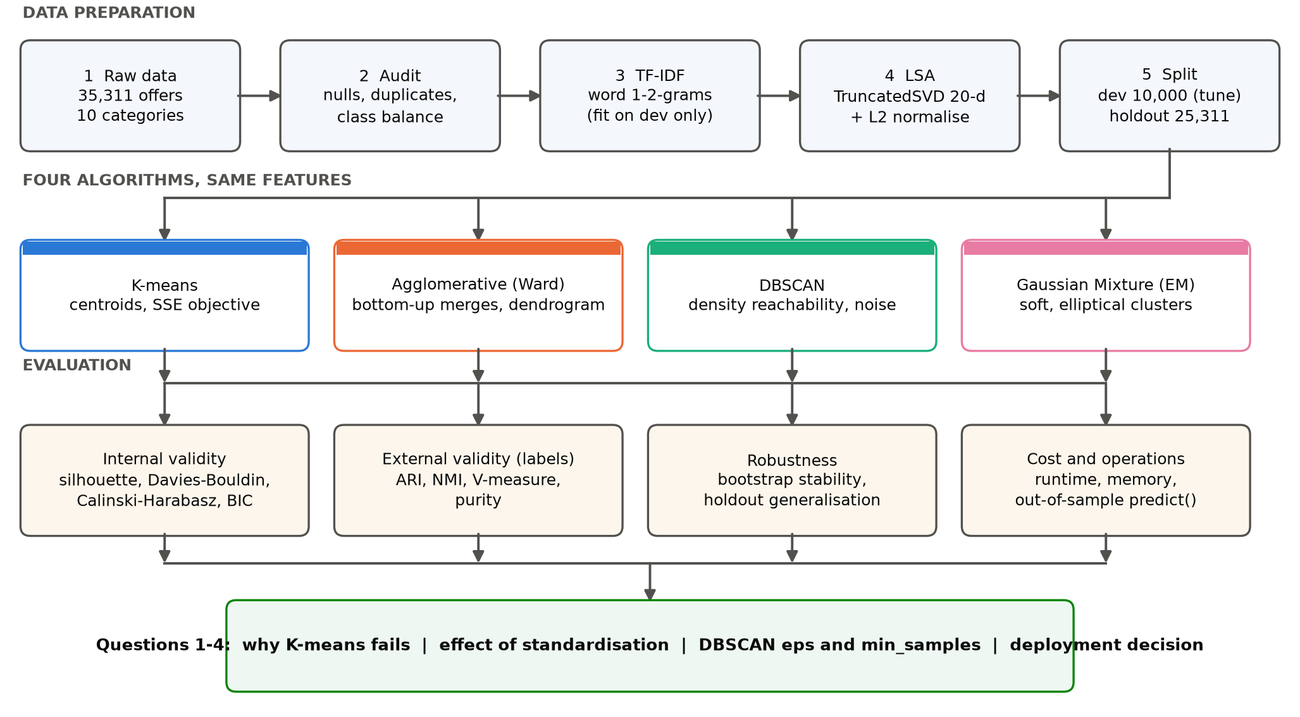
<br>
<i>Figure 1: End-to-end workflow: data preparation, four algorithms, evaluation, and the four questions.</i>
</center>

### **2.1 Data audit**

<p align="justify">
<b>Findings.</b>
</p>

- **Clean and complete:** no missing values; the CSV header had stray leading spaces (`" Merchant ID"`), stripped on load.
- **Duplicates are real.** 4,318 offers (12.2 %) repeat another title exactly: the same product listed by several merchants. They are kept (they are genuine marketplace density) but they matter for DBSCAN, where identical points count towards `min_samples`.
- **Class imbalance 2.5 : 1** (5,501 fridge-freezers vs 2,212 freezers), relevant to Q1.
- **Short, noisy text:** median 52 characters (about 8 words); 40.6 % of products have a single offer; some titles are German (*geschirrspüler*, *einbau*, *kühlschrank*), which will matter later.

<center>

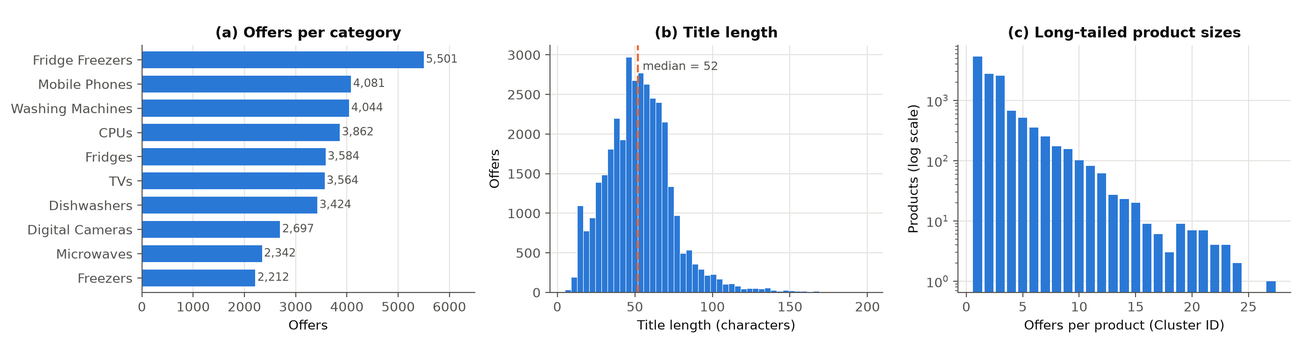
<br>
<i>Figure 2: Exploratory profile of the 35,311 offers: (a) offers per category, (b) title length, (c) offers per product.</i>
</center>

## **3. Feature Engineering and the Number of Clusters**

### **3.1 From titles to a geometry**

1. **TF-IDF** on word 1- and 2-grams (`min_df = 3`, sublinear term frequency): $w_{t,d} = \big(1+\ln \mathrm{tf}_{t,d}\big)\cdot\Big(\ln\tfrac{1+N}{1+\mathrm{df}_t}+1\Big)$, then each title is scaled to unit length.
2. **Latent semantic analysis (LSA):** truncated SVD $X \approx U_k\Sigma_k V_k^{\top}$ keeps $k$ dense latent coordinates $Z = XV_k$. Raw TF-IDF is 6,083-dimensional and 99.8 % zeros, where Euclidean distances concentrate and clustering is poor.
3. **Row normalisation** $\hat z_i = z_i/\lVert z_i\rVert$, so that $\lVert\hat z_i-\hat z_j\rVert^2 = 2\,(1-\cos\theta_{ij})$. Euclidean K-means on $\hat z$ is therefore cosine (spherical) K-means, and DBSCAN's `eps` is a cosine-type distance ($\varepsilon = 0.475 \Rightarrow \cos\theta \ge 0.887$).

<p align="justify">
<b>How many latent dimensions?</b> Figure 3 shows K-means quality rising to a plateau (NMI $\approx 0.70$-$0.72$) from 20 dimensions upward, and Ward peaking at 20 (0.68) then declining. <b>20 dimensions</b> is the smallest size on the plateau (16.1 % of TF-IDF variance, which is normal for sparse text). This is the one place labels were consulted.
</p>

<center>

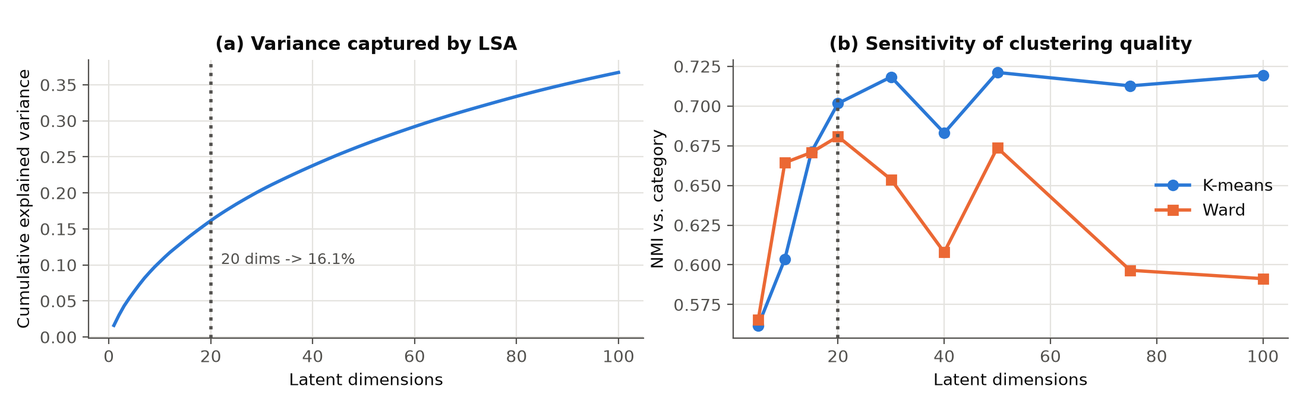
<br>
<i>Figure 3: Embedding size: (a) variance captured by LSA, (b) clustering quality (NMI against category) versus number of dimensions.</i>
</center>

### **3.2 How many clusters?**

<p align="justify">
No internal index points at $k = 10$: inertia falls smoothly, while silhouette, Calinski-Harabasz and Davies-Bouldin keep improving and are best at **$k = 19$** (Figure 4). The reason is structural: every category contains many brand/model families, so finer partitions always look "tighter". External NMI is flat at about 0.67-0.72 for $k = 9$-$14$. We therefore fix **$k = 10$ from the business taxonomy** (and say so), rather than pretend the data select it. The same $k$ is used for K-means, Ward and GMM; DBSCAN chooses its own number of clusters.
</p>

<center>

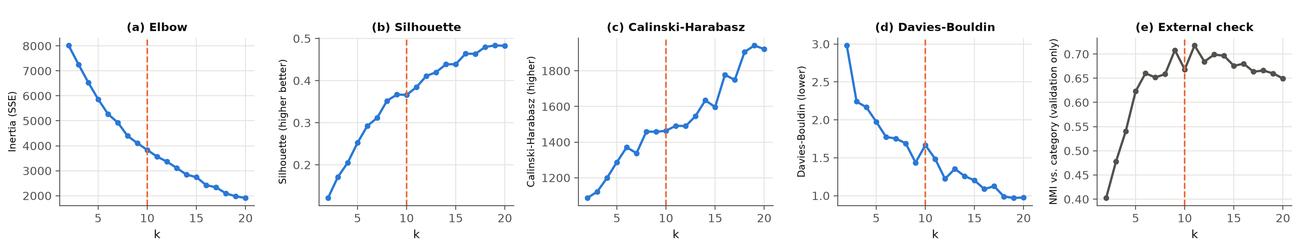
<br>
<i>Figure 4: K-means internal validity indices against k (dashed line: k = 10); panel (e) shows external NMI for validation only.</i>
</center>

## **4. The Four Algorithms**

### **4.1 K-means**

<p align="justify">
<b>Objective.</b> Find centroids $\mu_1..\mu_K$ minimising the within-cluster sum of squares $J=\sum_{k}\sum_{x\in C_k}\lVert x-\mu_k\rVert^2$. <b>Lloyd's algorithm</b> alternates <i>assign</i> (each point to its nearest centroid) and <i>update</i> ($\mu_k \leftarrow$ mean of $C_k$); $J$ never increases, so it converges, but only to a <b>local</b> minimum, hence k-means++ seeding and many restarts. Cost per run is $O(n\,K\,D\,I)$ time and $O(nD)$ memory.
</p>

<p align="justify">
The notebook contains a from-scratch implementation. Started from the same centroids, it reaches <b>exactly</b> the same partition as scikit-learn (ARI = 1.0000, identical inertia). Using 20 restarts, scikit-learn then finds a slightly better optimum (inertia 3,810 vs 3,840), a reminder that K-means results depend on initialisation.
</p>

**Table. K-means clusters (dev set):** size, majority category, purity and the highest-weight TF-IDF terms.

| Cluster | Size | Majority category | Purity | Top terms |
| :--- | ---: | :--- | ---: | :--- |
| 0 | 1372 | Fridge Freezers | 81% | freezer, fridge freezer, fridge, frost, frost free, free |
| 4 | 1224 | Dishwashers | 54% | bosch, dishwasher, washer, integrated, dryer, washer dryer |
| 1 | 1123 | Mobile Phones | 94% | sim, phone, mobile, mobile phone, samsung, sim free |
| 8 | 1105 | Fridges | 50% | liebherr, fridge, white, freezer, larder, under |
| 3 | 1096 | CPUs | 99% | intel, processor, core, ghz, xeon, intel xeon |
| 2 | 967 | TVs | 97% | tv, led, hd, smart, 4k, led tv |
| 6 | 876 | Digital Cameras | 86% | camera, digital, canon, sony, black, body |
| 7 | 868 | Dishwashers | 30% | siemens, ler, geschirrsp ler, geschirrsp, einbau, gorenje |
| 5 | 740 | Washing Machines | 100% | washing, machine, washing machine, white, spin, machine white |
| 9 | 629 | Microwaves | 84% | microwave, oven, microwave oven, steel, stainless steel, stainless |

<p align="justify">
<b>Reading the clusters.</b> Seven of ten clusters are at least 80 % pure (CPUs 99 %, washing machines 99.9 %, TVs 97 %, mobile phones 94 %, cameras 86 %, microwaves 84 %, fridge-freezers 81 %). Three are mixed. Cluster 7 is not a category at all: <b>72 % of its offers contain German marker words</b> (vs 0-3 % in the other clusters) so K-means has grouped by <i>language</i>, a nuisance direction in the embedding. Clusters 4 (dishwashers 54 %, washing machines 26 %) and 8 (fridges 50 %, freezers 30 %) mix neighbouring appliance types whose titles share vocabulary.
</p>

### **4.2 Agglomerative hierarchical clustering (Ward)**

<p align="justify">
Every offer starts as its own cluster; the two closest clusters are merged repeatedly. <b>Ward linkage</b> merges the pair with the smallest increase in within-cluster variance,
$$\Delta(A,B)=\frac{n_A\,n_B}{n_A+n_B}\,\lVert\mu_A-\mu_B\rVert^2,$$
the same sum-of-squares criterion as K-means, so its clusters are compact. Exact agglomeration needs the full pairwise-distance matrix: **$O(n^2)$ memory and $\ge O(n^2)$ time**, the main limitation (Section 9).
</p>

<p align="justify">
<b>Linkage comparison</b> (3,000-offer subsample). <i>Single</i> linkage chains almost everything into one cluster (96.8 % of offers, ARI 0.003); <i>complete</i> linkage is poor (ARI 0.27); <i>Ward</i> and <i>average</i> are close (ARI 0.52 vs 0.54, NMI 0.67 vs 0.68; differences of this size are within sampling noise). <b>Ward</b> is used because it optimises the same criterion as K-means and has the clean $\Delta$ interpretation above. The dendrogram (Figure 5) shows no sharp gap in merge cost at $k=10$: the cut is again imposed by the taxonomy.
</p>

<center>

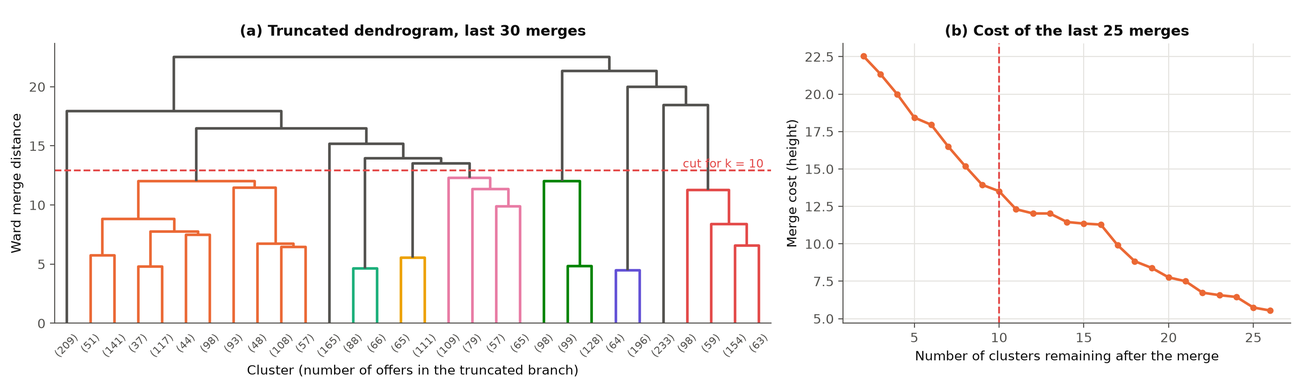
<br>
<i>Figure 5: Ward dendrogram on a 3,000-offer subsample (a) and the cost of the last 25 merges (b).</i>
</center>

**Table. Ward clusters (dev set):** size, majority category, purity and top terms.

| Cluster | Size | Majority category | Purity | Top terms |
| :--- | ---: | :--- | ---: | :--- |
| 3 | 1907 | Fridge Freezers | 60% | freezer, fridge, fridge freezer, liebherr, frost, smeg |
| 0 | 1781 | Fridges | 26% | bosch, white, fridge, hotpoint, in, washer |
| 1 | 1158 | Mobile Phones | 92% | sim, phone, samsung, mobile, mobile phone, black |
| 2 | 1082 | CPUs | 99% | intel, processor, core, ghz, xeon, intel xeon |
| 7 | 955 | TVs | 97% | tv, hd, led, smart, 4k, led tv |
| 9 | 871 | Digital Cameras | 86% | camera, digital, canon, sony, body, digital camera |
| 5 | 736 | Washing Machines | 100% | washing, machine, washing machine, white, spin, machine white |
| 8 | 541 | Dishwashers | 96% | dishwasher, integrated dishwasher, integrated, place, fully, fully integrated |
| 6 | 493 | Fridge Freezers | 35% | siemens, gorenje, einbau, hl, eek, hl gefrier |
| 4 | 476 | Microwaves | 98% | microwave, oven, microwave oven, steel, in, built in |

<p align="justify">
<b>Reading the clusters.</b> Ward isolates CPUs (99 %), washing machines (99.9 %), TVs (97 %), microwaves (98 %), dishwashers (96 %) and mobile phones (92 %) well, but it puts 1,781 offers in a mixed "bosch, white, hotpoint, washer" cluster (26 % fridges) and, like K-means, creates a German-language cluster (cluster 6, 36 % fridge-freezers).
</p>

### **4.3 DBSCAN and principled parameter selection**

<p align="justify">
<b>Definitions.</b> For radius $\varepsilon$ and threshold $m$ (<code>min_samples</code>, counting the point itself): a point is a <b>core point</b> if $|N_\varepsilon(p)|\ge m$; a point is a <b>border point</b> if it is within $\varepsilon$ of a core point but is not core; clusters are the connected components of core points plus their border points; all remaining points are <b>noise</b> ($-1$). DBSCAN needs no $k$, finds arbitrarily shaped clusters, and labels outliers.
</p>

<p align="justify">
<b>The selection procedure (no labels, no guessing)</b>
</p>

1. **Range for `min_samples`** from the dimension rule $m \ge D+1$ (here $D = 20$), the common default being $m = 2D$ (Sander et al., 1998); larger values for noisy, duplicated data. We scan $m \in \{5,\dots,320\}$.
2. **Upper bound for `eps`** from the **k-distance curve**: sort every point's distance to its $m$-th neighbour and take the knee (farthest point below the chord, Kneedle style).
3. **Scan below the knee** with a (`min_samples` $\times$ `eps`) grid and score every cell *without labels*: $\;\text{score}=(1-\text{noise fraction})\times\text{silhouette of the clustered points}\;$, subject to a **percolation guard** (at least 2 clusters and no cluster holding more than 50 % of the data). The score rewards tight clusters *and* coverage; without the noise factor, silhouette alone would reward discarding almost everything.
4. **Check the plateau and stability**, and only then compare with labels.

<p align="justify">
Results: (a) the knee <b>overshoots</b> (Figure 6 and the table: from <code>min_samples</code> = 40 upward, the knee <code>eps</code> merges at least 94 % of the clustered points into one cluster); (b) the grid optimum is <b>interior</b> (score 0.401, 0.441, 0.446, <b>0.451</b> at <code>min_samples</code> 40, 80, 120, <b>160</b>, then falls to 0.348 at 240), with a plateau over 80-160; (c) the selected cell is <code>min_samples</code> = 160, <code>eps</code> = 0.475.
</p>

<center>

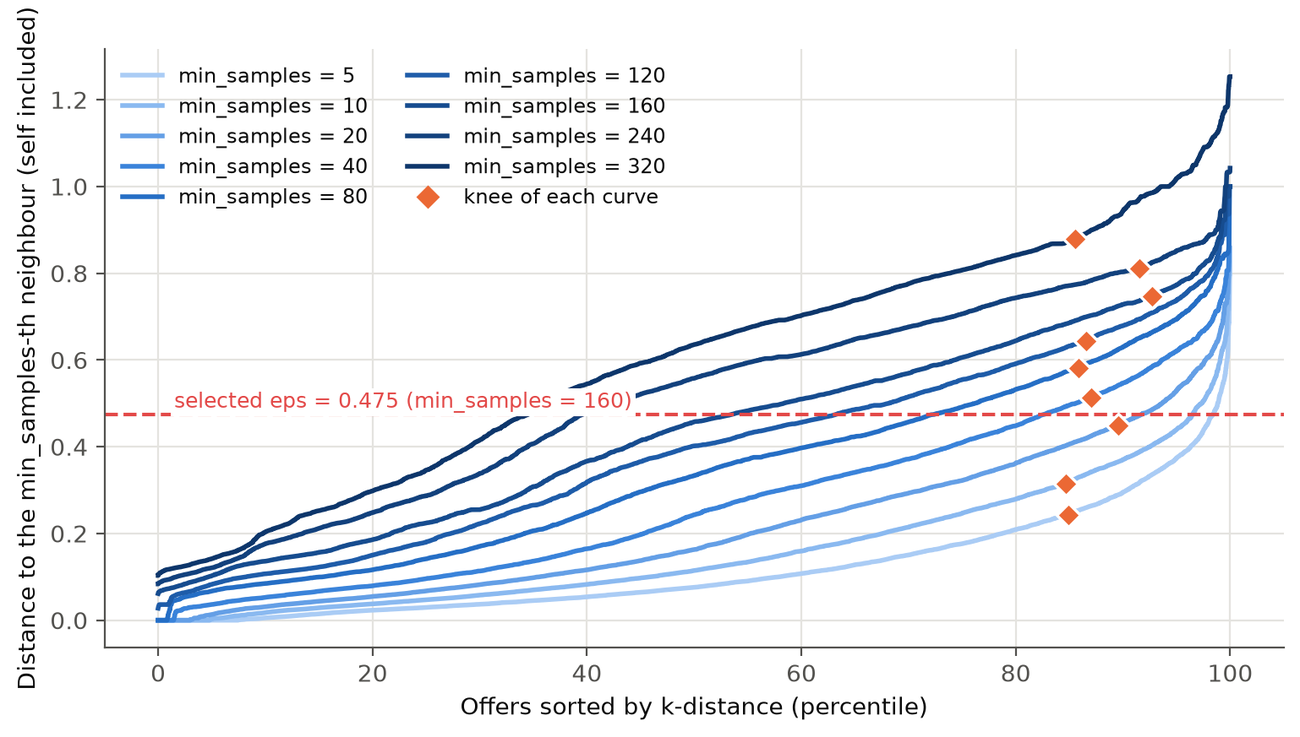
<br>
<i>Figure 6: Sorted k-distance curves for each min_samples. Diamonds mark the knees; the red line is the selected eps.</i>
</center>

**Table. What the k-distance knee suggests, and what it does.** The knee `eps` is an upper bound: for `min_samples` of 40 or more it merges at least 94 % of the clustered points into one cluster.

| min_samples | eps (knee) | Clusters | Noise | Largest cluster | ARI |
| :--- | ---: | ---: | ---: | ---: | ---: |
| 5 | 0.244 | 143 | 11.7% | 27.1% | 0.335 |
| 10 | 0.315 | 48 | 9.3% | 28.5% | 0.366 |
| 20 | 0.448 | 6 | 3.5% | 72.6% | 0.109 |
| 40 | 0.513 | 2 | 2.9% | 94.5% | 0.003 |
| 80 | 0.582 | 2 | 1.8% | 95.4% | 0.003 |
| 120 | 0.644 | 1 | 0.8% | 99.2% | 0.000 |
| 160 | 0.747 | 1 | 0.1% | 99.9% | -0.000 |
| 240 | 0.811 | 1 | 0.1% | 99.9% | -0.000 |
| 320 | 0.879 | 1 | 0.1% | 99.9% | -0.000 |

<center>

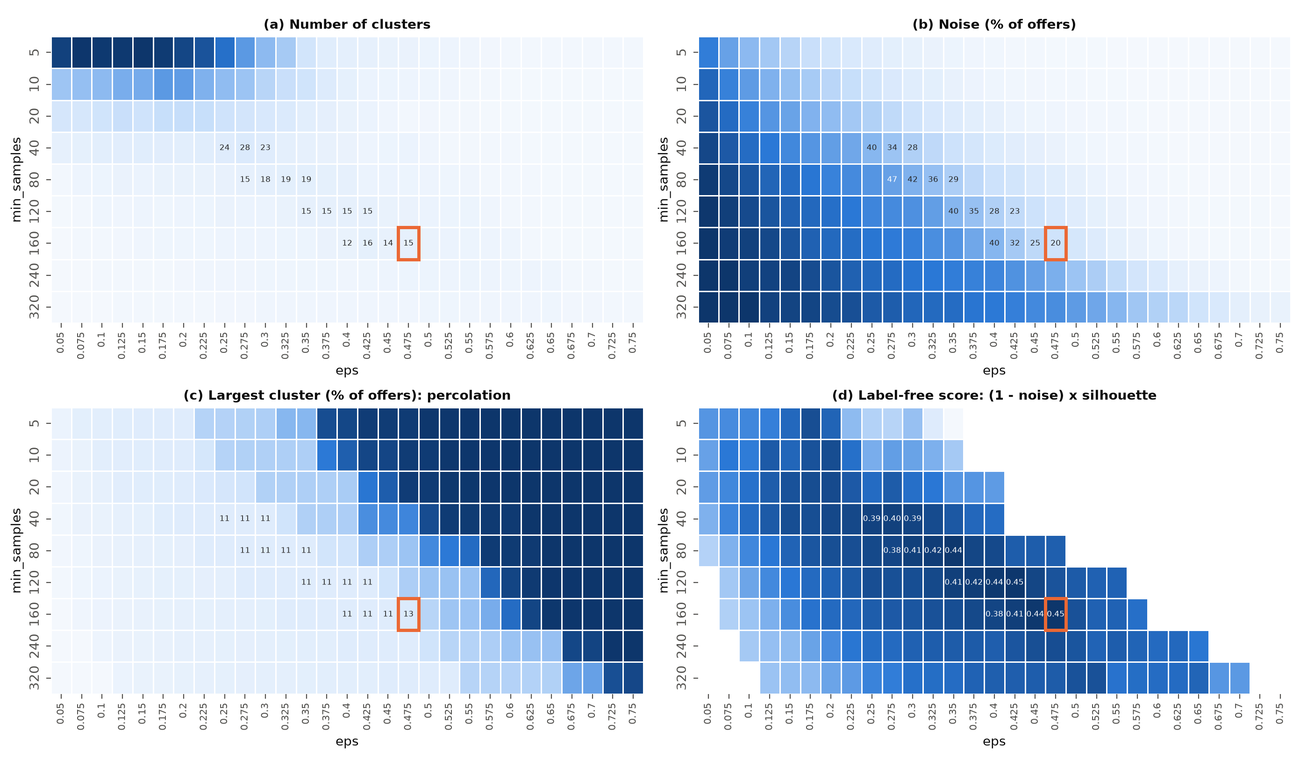
<br>
<i>Figure 7: DBSCAN grid search over min_samples and eps. Orange frame: selected cell. Numbers are shown where the label-free score is at least 0.38.</i>
</center>

**Table. Best cell for each `min_samples` (label-free score; ARI shown for reference only).**

| min_samples | eps | Clusters | Noise | Largest cluster | Silhouette | Score | ARI (reference) |
| :--- | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| 5 | 0.175 | 203 | 21.3% | 10.7% | 0.436 | 0.343 | 0.330 |
| 10 | 0.200 | 102 | 25.5% | 10.7% | 0.469 | 0.349 | 0.319 |
| 20 | 0.200 | 47 | 37.2% | 10.7% | 0.573 | 0.360 | 0.255 |
| 40 | 0.275 | 28 | 33.9% | 10.8% | 0.607 | 0.401 | 0.299 |
| 80 | 0.350 | 19 | 29.1% | 10.8% | 0.623 | 0.441 | 0.367 |
| 120 | 0.425 | 15 | 23.2% | 10.9% | 0.581 | 0.446 | 0.432 |
| 160 | 0.475 | 15 | 19.5% | 13.1% | 0.560 | 0.451 | 0.469 |
| 240 | 0.475 | 9 | 42.5% | 10.9% | 0.605 | 0.348 | 0.310 |
| 320 | 0.525 | 7 | 45.0% | 10.9% | 0.609 | 0.335 | 0.295 |

**Table. DBSCAN clusters (dev set, the 12 largest of 15):** size, majority category, purity and top terms.

| Cluster | Size | Majority category | Purity | Top terms |
| :--- | ---: | :--- | ---: | :--- |
| 6 | 1310 | Fridge Freezers | 63% | freezer, fridge, fridge freezer, frost, frost free, free |
| 5 | 1091 | CPUs | 99% | intel, processor, core, ghz, xeon, intel xeon |
| 3 | 959 | TVs | 97% | tv, hd, led, smart, 4k, led tv |
| 0 | 881 | Digital Cameras | 85% | camera, digital, black, sony, canon, body |
| 4 | 704 | Mobile Phones | 99% | sim, smartphone, sim free, free, dual, unlocked |
| 2 | 669 | Washing Machines | 100% | washing, machine, washing machine, white, machine white, spin |
| 1 | 453 | Fridge Freezers | 36% | siemens, gorenje, einbau, hl, eek, hlschrank |
| 10 | 415 | Microwaves | 98% | microwave, oven, microwave oven, steel, in, stainless |
| 8 | 282 | Dishwashers | 100% | dishwasher, integrated dishwasher, integrated, fully integrated, fully, place |
| 12 | 260 | Mobile Phones | 100% | phone, mobile, mobile phone, nokia, htc, sim |
| 9 | 241 | Fridge Freezers | 24% | bosch, hlschrank, wei, edelstahl, bosch hlschrank, hlger |
| 11 | 233 | Washing Machines | 100% | washer, dryer, washer dryer, dryer white, white, 5kg |

<p align="justify">
<b>Reading the clusters.</b> DBSCAN returns 15 dense groups that cover 80.5 % of the offers and flags 19.5 % as noise. Its clusters are very pure where it commits (CPUs 99 %, TVs 97 %, washing machines 100 %, mobile phones 99-100 %, dishwashers 98-100 %, microwaves 98 %) but it does not split the fridge / fridge-freezer / freezer region and creates German-language clusters. Homogeneity ("Homog." in the table) is high (0.68) but completeness ("Compl.") lower (0.62): <b>DBSCAN is a precise but partial clustering</b>. <b>HDBSCAN</b>, which removes <code>eps</code> altogether, produced 92 micro-clusters and 41.9 % noise on this data (ARI 0.07), so it does not rescue the category task either.
</p>

### **4.4 Gaussian mixture model (EM)**

<p align="justify">
<b>Model.</b> $p(x)=\sum_{k=1}^{K}\pi_k\,\mathcal N(x\mid\mu_k,\Sigma_k)$. <b>EM</b> alternates the E-step (responsibilities $r_{ik}=\pi_k\mathcal N(x_i\mid\mu_k,\Sigma_k)\big/\sum_j\pi_j\mathcal N(x_i\mid\mu_j,\Sigma_j)$) and the M-step ($\pi_k,\mu_k,\Sigma_k$ re-estimated with weights $r_{ik}$); the log-likelihood never decreases. The covariance structure is chosen with the <b>BIC</b> $=p\ln n-2\ln\hat L$ (lower is better). K-means is the limit $\Sigma_k=\sigma^2 I$, $\pi_k = 1/K$, $\sigma\to 0$.
</p>

<p align="justify">
<b>Selection.</b> At $k = 10$ the BIC is lowest for <b>full</b> covariance ($-648{,}954$) against diagonal ($-405{,}529$), spherical ($-262{,}086$) and tied ($-257{,}245$), and falls further as $k$ grows (Figure 8), the same "finer is always better" pattern as the internal indices. The fitted mixture is confident: 97.7 % of offers have a posterior $\ge 0.99$ and only 1.0 % are ambiguous ($<0.9$) (Figure 9).
</p>

<center>

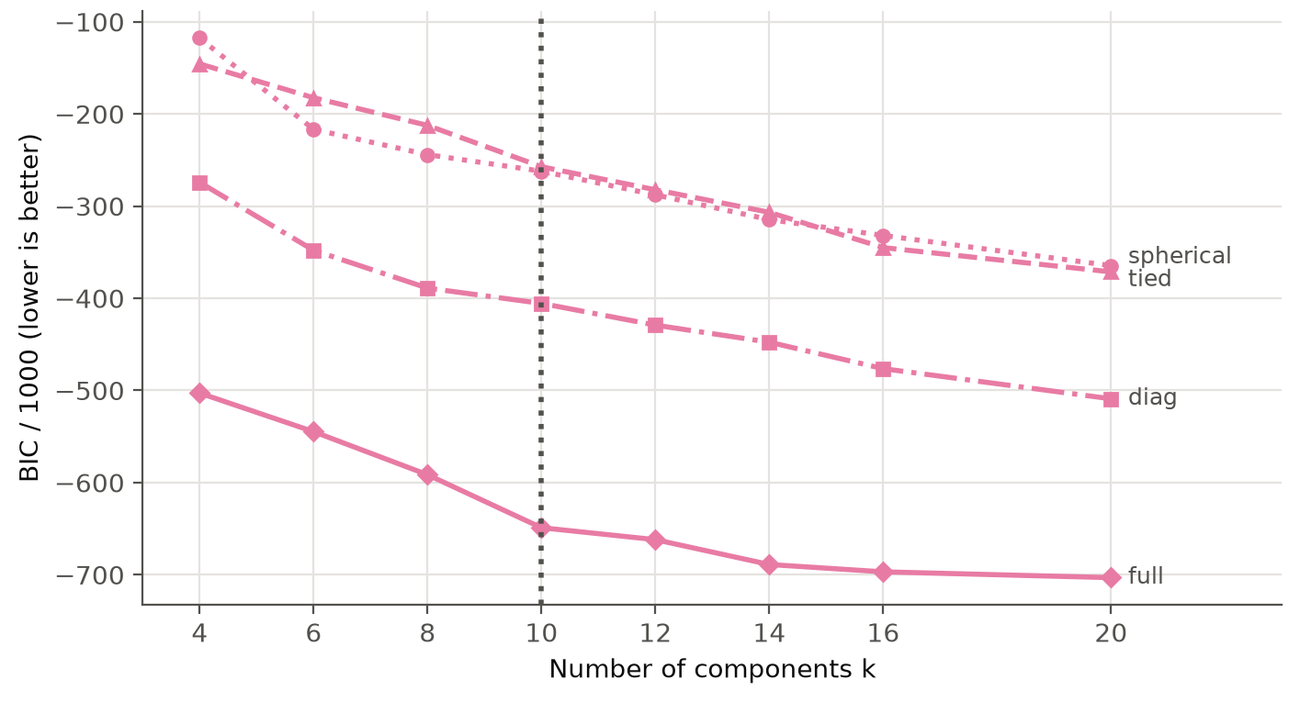
<br>
<i>Figure 8: GMM model selection with BIC by covariance type and number of components.</i>
</center>

<center>

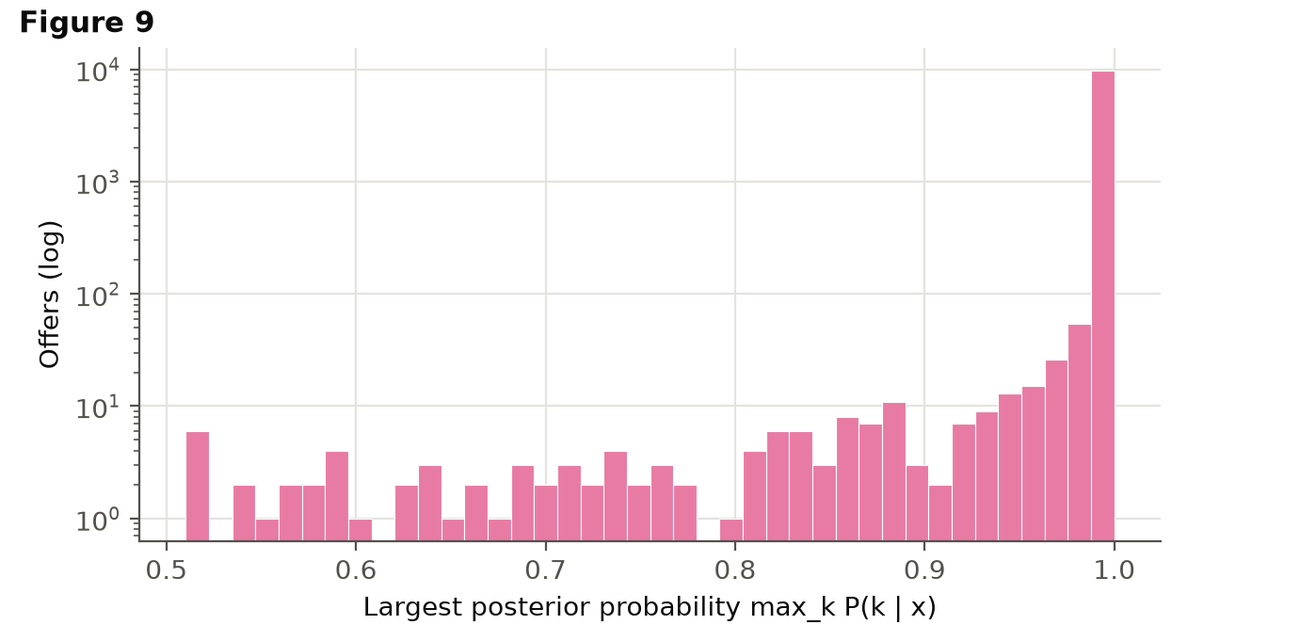
<br>
<i>Figure 9: GMM soft assignments: distribution of the largest posterior probability per offer.</i>
</center>

## **5. Model Comparison**

**Table. Dev set (10,000 offers), 10 true categories.** DBSCAN's internal indices are computed on the 80.5 % of offers that were not labelled as noise.

| Model | Clusters | Noise | Fit (s) | Silh. | Davies-Bouldin | Calinski-Harabasz | ARI | NMI | Homog. | Compl. | Purity |
| :--- | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| K-means | 10 | 0.0% | 0.3 | 0.372 | 1.57 | 1480 | 0.622 | 0.699 | 0.700 | 0.697 | 0.769 |
| Agglomerative (Ward) | 10 | 0.0% | 5.5 | 0.357 | 1.68 | 1346 | 0.550 | 0.681 | 0.669 | 0.693 | 0.731 |
| DBSCAN | 15 | 19.5% | 0.2 | 0.558 | 0.84 | 2066 | 0.469 | 0.644 | 0.677 | 0.615 | 0.714 |
| GMM | 10 | 0.0% | 22.2 | 0.289 | 2.28 | 1057 | 0.538 | 0.654 | 0.653 | 0.655 | 0.688 |

<center>

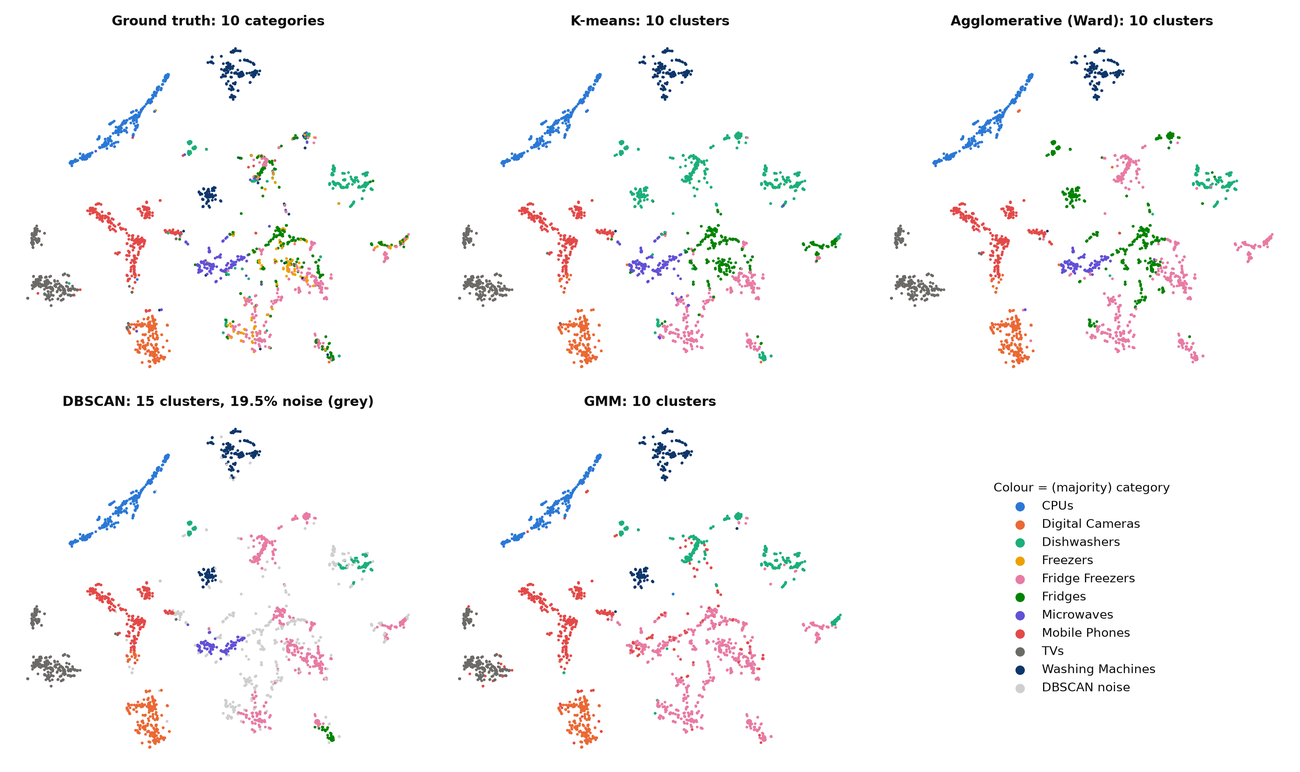
<br>
<i>Figure 10: t-SNE map of 3,000 dev offers coloured by true category and by the (majority) category of each model's clusters.</i>
</center>

<center>

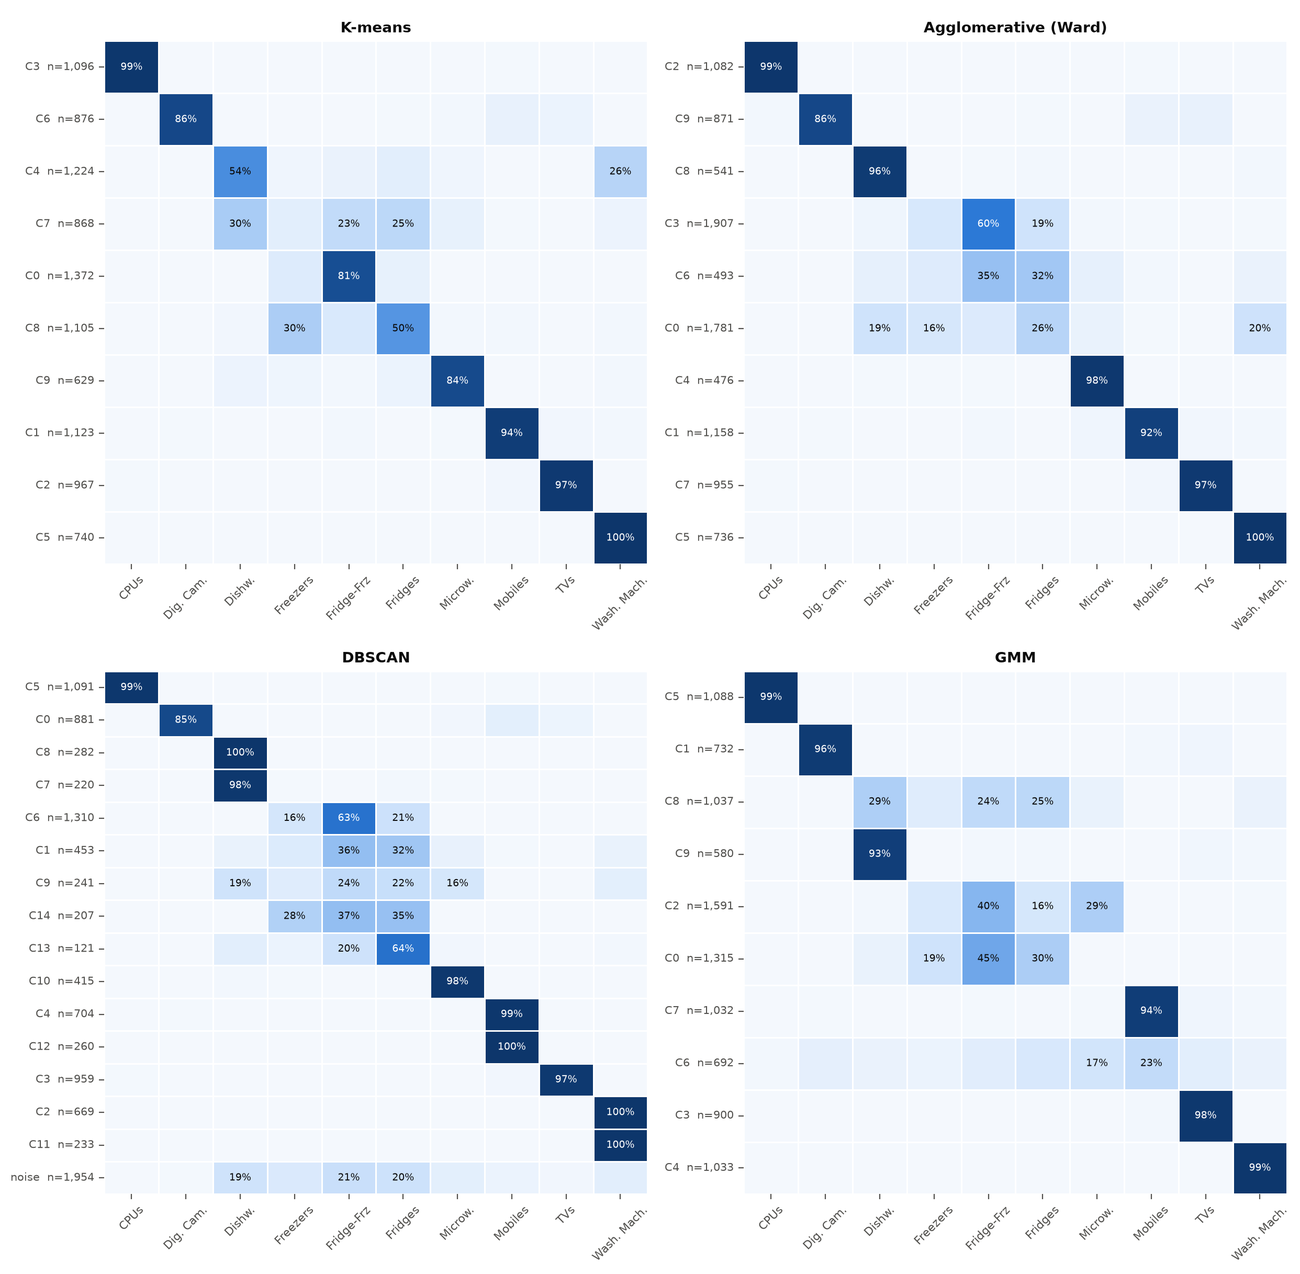
<br>
<i>Figure 11: Cluster composition: share of each true category inside each cluster, for the four models.</i>
</center>

<p align="justify">
<b>Reading the table.</b>
</p>

- **External agreement ranks K-means > Ward > GMM > DBSCAN** (ARI 0.62 / 0.55 / 0.54 / 0.47; NMI 0.70 / 0.68 / 0.65 / 0.64).
- **DBSCAN's silhouette (0.56) and Davies-Bouldin (0.84) look best only because they are computed on the 80.5 % of offers that were not discarded**; they are not comparable with the other rows.
- All four models recover the visually separate "islands" (CPUs, TVs, cameras, phones, washing machines; Figure 10). They differ in the crowded middle of the map where fridges, freezers, dishwashers and microwaves overlap (Figure 11). GMM's two largest clusters (1,591 and 1,315 offers) each blend fridge-freezers with fridges, freezers or microwaves, whereas K-means and Ward keep these better apart.
- Every model creates at least one **German-language cluster**: language is a stronger signal in the embedding than category for those offers (see Section 10).

## **6. Question 1: Why can K-means fail when clusters differ in density, size or shape?**

> **Short answer.** K-means minimises $J=\sum_k\sum_{x\in C_k}\lVert x-\mu_k\rVert^2$. This is the hard-assignment limit of a Gaussian mixture with **identical isotropic covariances $\sigma^2 I$ and equal weights**. It can therefore only represent equal-spread, roughly equal-size, *convex, spherical* clusters. When the data violate these assumptions, the partition that minimises $J$ is **not** the partition a human would call correct.

<p align="justify">
<b>Mathematics: four failure modes.</b>
</p>

1. **Density / spread: the boundary ignores variance.** A point goes to the nearer centroid, so the boundary is the perpendicular bisector halfway between centroids, **whatever the spreads**. For two clusters $N(0,\sigma_1^2)$ and $N(d,\sigma_2^2)$ with $\sigma_1\gg\sigma_2$, the fraction of the broad cluster lost to the tight one is (first order) $\;1-\Phi\!\big(\tfrac{d}{2\sigma_1}\big)$, e.g. 20 % when $\sigma_1 = 0.6\,d$. A density-aware (Bayes) boundary would sit much closer to the tight cluster.
2. **Size: splitting a big cluster is cheaper than isolating a small one.** Separating cluster $B$ from $A$ lowers $J$ by $\dfrac{n_An_B}{n_A+n_B}\lVert\mu_A-\mu_B\rVert^2\approx n_B\,d^2$ (the Ward identity of Section 4.2). Cutting a Gaussian cluster of $n_1$ points through its centre lowers $J$ by $\tfrac{2}{\pi}n_1\sigma_1^2$. K-means prefers to **split the large cluster and swallow the small one** when
$$\frac{n_1}{n_2}>\frac{\pi}{2}\,\frac{d^2}{\sigma_1^2}\quad(=25\ \text{for clusters } d=4\sigma_1\text{ apart, i.e. clearly separated}).$$

3. **Shape: elongation.** Two thin parallel stripes (long-axis std $\sigma_a$, gap $d$) with $n$ points in total: the correct split lowers $J$ by $nd^2/4$, a wrong cut across the long axis by $\tfrac{2}{\pi}n\sigma_a^2$. The wrong cut wins when $\;\sigma_a/d>\sqrt{\pi/8}\approx0.63$. Euclidean distance has no notion of direction, so correlated/elongated clusters are cut across.
4. **Non-convexity.** Voronoi cells are convex, so interleaved shapes (two moons, concentric rings, a river, a fault line) cannot be separated by *any* choice of centroids.

<center>

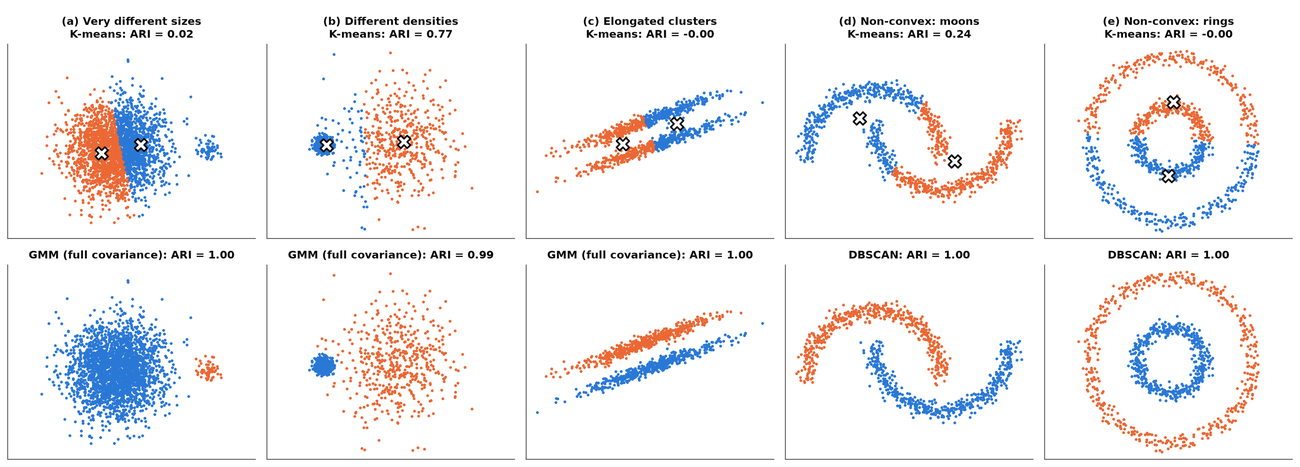
<br>
<i>Figure 12: The same data clustered by K-means (top, X = centroid) and by an algorithm whose assumptions match the shape (bottom).</i>
</center>

<p align="justify">
<i>Figure 12 note: GMM was fitted with 10 random starts (<code>init_params="random_from_data"</code>) and the best likelihood kept; initialising it from K-means would inherit K-means' wrong partition, which is itself a practical lesson.</i>
</p>

<center>

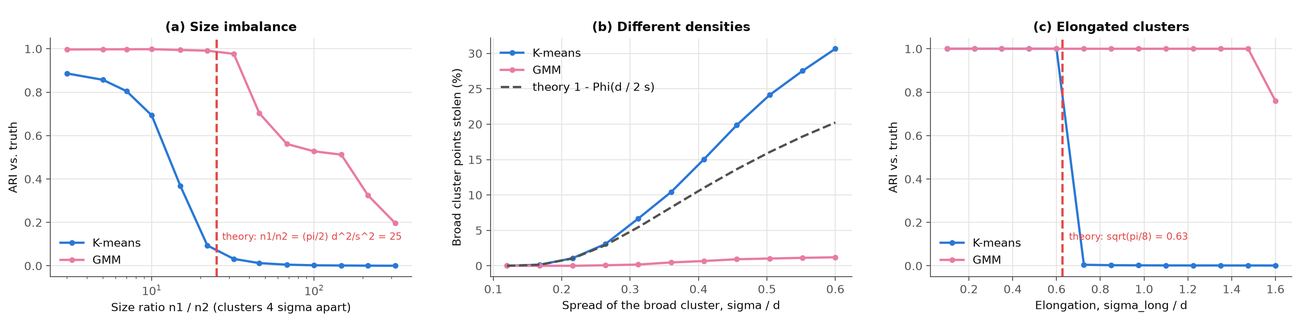
<br>
<i>Figure 13: Simulation against the closed-form predictions: (a) size imbalance, (b) different densities, (c) elongated clusters.</i>
</center>

<p align="justify">
<b>Evidence.</b> Figure 12 applies the same data to K-means and to an algorithm whose assumptions fit; Figure 13 checks the formulas by simulation:
</p>

| Failure mode | Theory | Simulation (K-means) | GMM / DBSCAN |
|---|---|---|---|
| Size imbalance (4 $\sigma$ apart) | breaks near $n_1/n_2 = 25$ | ARI $<0.5$ from ratio $\approx 13$, $\approx 0.03$ beyond 32 | GMM holds ARI $\ge 0.5$ up to ratio $\approx 150$ |
| Broad cluster, $\sigma_1=0.5\,d$ | loses 16 % (first order) | loses 24 % | GMM loses 1 % |
| Elongation | breaks at $\sigma_a/d=0.63$ | ARI falls through 0.5 at 0.66 | GMM stays at ARI $\approx 1$ |
| Moons / rings | impossible for convex cells | ARI 0.24 / $-0.00$ | DBSCAN ARI 1.00 / 1.00 |

<p align="justify">
The theory is a first-order guide (centroids drift towards the points they steal, so K-means does slightly worse than predicted in the density case), but both tipping points are located correctly.
</p>

<p align="justify">
<b>In our data.</b> The K-means German-language cluster (Section 4.1) and the dishwasher/washing-machine and fridge/freezer clusters are the same phenomenon: clusters whose spread and orientation in LSA space differ from a sphere around a mean.
</p>

<p align="justify">
<b>Real-world examples.</b>
</p>

- **Land-cover mapping (remote sensing):** water is a tight spectral cluster, but bare soil and urban surfaces form a long, elongated "soil line" in red-NIR space. K-means or ISODATA cuts the soil line into arbitrary pieces; a Gaussian maximum-likelihood classifier with class covariances follows it.
- **Crime or accident hotspots (GIS):** incidents lie along roads and fault lines (non-convex strips), plus scattered isolated events. K-means partitions a road into Voronoi chunks and forces outliers into clusters; DBSCAN follows the strip and labels the isolated events as noise.
- **Customer segmentation:** a few very-high-spend customers against a huge mass of low spend (different size *and* spread): K-means splits the mass and merges the VIPs; a log transform or GMM separates them.

<p align="justify">
<b>Remedies.</b> GMM with full covariance (elliptical, different sizes; use several random starts and pick by likelihood, as K-means initialisation can trap it, see Figure 12 notes), DBSCAN/HDBSCAN (arbitrary shapes, noise), spectral clustering, feature transforms (log, whitening), or over-cluster and then merge.
</p>

## **7. Question 2: How does standardisation change the clusters? (experiment)**

<p align="justify">
<b>Design.</b> Real systems seldom cluster text alone; they append structured descriptors. To each offer we add four numeric descriptors of its title (<code>title_chars</code>, <code>title_words</code>, <code>digit_chars</code>, <code>avg_word_len</code>, whose scales differ by orders of magnitude) to the 20 LSA coordinates. Four conditions, each run through all four algorithms: <b>A</b> LSA only (baseline), <b>B</b> LSA + descriptors, raw; <b>C</b> LSA + descriptors, z-scored; <b>D</b> LSA only, z-scored. DBSCAN's <code>eps</code> is re-read from the <i>same point of the k-distance curve</i> in each space (it equals 0.475, 3.21, 3.01 and 2.34), because <code>eps</code> carries the units of the features.
</p>

<p align="justify">
<b>Mathematics.</b> Euclidean distance is $d^2(x,y)=\sum_j(x_j-y_j)^2$. Feature $j$ therefore contributes roughly $\mathrm{Var}(x_j)\big/\sum_l\mathrm{Var}(x_l)$ of the geometry. After $z_j=(x_j-\bar x_j)/s_j$ the distance becomes $\sum_j (x_j-y_j)^2/s_j^2$ (a diagonal Mahalanobis distance) and every feature carries the same share, $1/24$ here.
</p>

<center>

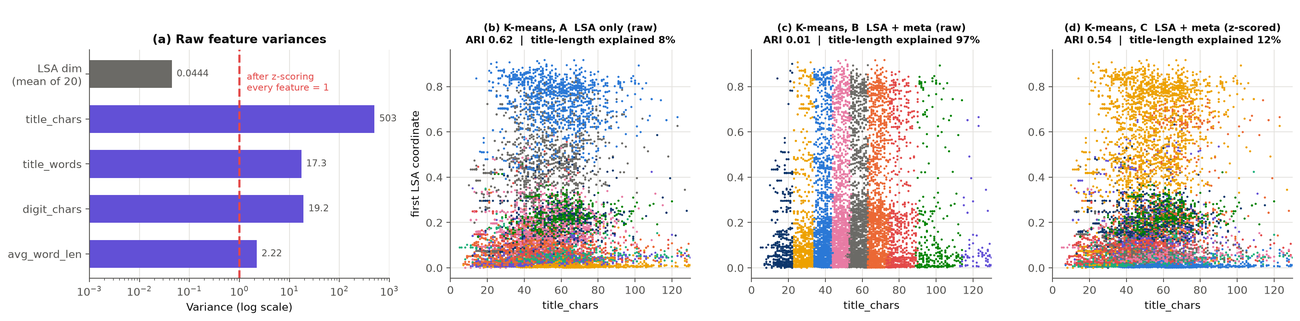
<br>
<i>Figure 14: Unscaled descriptors take over the geometry: (a) raw feature variances; (b-d) K-means partitions under conditions A, B and C.</i>
</center>

<center>

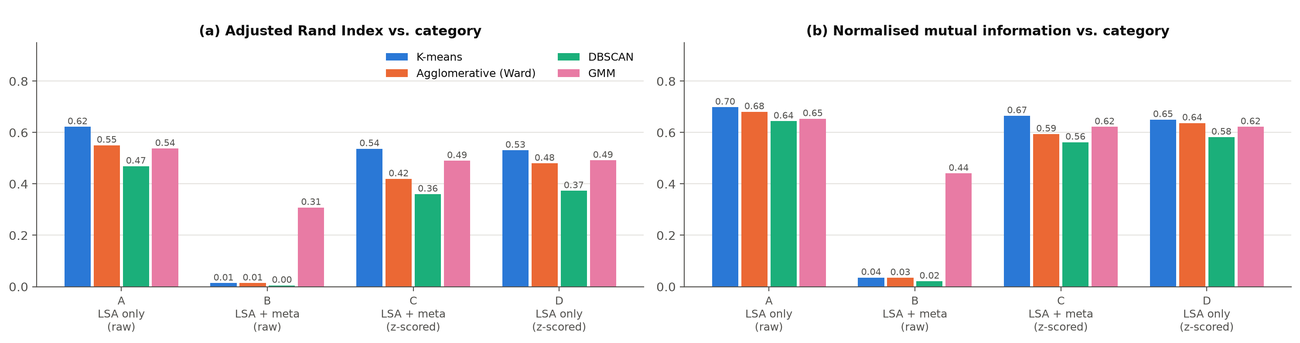
<br>
<i>Figure 15: Effect of feature scaling on each algorithm: (a) ARI and (b) NMI against category for conditions A-D.</i>
</center>

<p align="justify">
<b>Results (Figures 14-15; ARI against category).</b>
</p>

| Condition | K-means (mean $\pm$ sd, 10 seeds) | Ward | DBSCAN | GMM |
|---|---|---|---|---|
| A: LSA only | 0.60 $\pm$ 0.04 | 0.55 | 0.47 | 0.54 |
| **B: + descriptors, raw** | **0.01** | **0.01** | **0.005** | 0.31 |
| C: + descriptors, z-scored | 0.54 $\pm$ 0.04 | 0.42 | 0.36 | 0.49 |
| D: LSA only, z-scored | 0.55 $\pm$ 0.06 | 0.48 | 0.37 | 0.49 |

1. **Without scaling the geometry is hijacked.** `title_chars` alone carries 92.7 % of the total variance in B (the 20 LSA coordinates together carry 0.16 %, the four descriptors 99.8 %). K-means and Ward clusters become **bins of title length** (97.5 % and 96.5 % of the variance of `title_chars` is explained by cluster membership, against 8 % in A), and agreement with the categories vanishes (ARI 0.01).
2. **Standardisation repairs it (B $\to$ C):** ARI returns to 0.54 (K-means) and the length effect falls to 12 %. C is still a little below A: the four descriptors are mostly noise for category and now get 1/6 of the weight.
3. **It is not a free lunch (A $\to$ D).** The 20 LSA coordinates already share a scale (std 0.16-0.27); z-scoring them changes K-means by less than its seed-to-seed spread (0.60 $\pm$ 0.04 vs 0.55 $\pm$ 0.06) but lowers Ward (0.55 $\to$ 0.48) and DBSCAN (0.47 $\to$ 0.37), because it inflates weak components. When features share a unit and variance carries information (TF-IDF/LSA, spectral bands), scaling can *remove* signal.
4. **Algorithms differ in scale sensitivity.** K-means, Ward and DBSCAN use raw Euclidean distance, so they are fully exposed. GMM with full covariance models each feature's scale itself (its Mahalanobis distance is affine-invariant), so it degrades less (0.54 $\to$ 0.31), but not to zero because EM starts from a K-means partition computed on the unscaled data.

<p align="justify">
<b>Rules of thumb.</b> Standardise (or robust-scale / log-transform skewed features) when features differ in units or range and each should matter comparably, e.g. <i>age (years) vs income (dollars)</i> in customer segmentation, or <i>NDVI in [-1, 1] vs a 16-bit digital number</i> in remote sensing. Do not blindly standardise features that already live on a common scale. Always re-derive scale-bound parameters (<code>eps</code>) after scaling.
</p>

## **8. Question 3: How should DBSCAN's eps and min_samples be selected without arbitrary choices?**

> **Short answer.** Treat the pair as **one density threshold plus one resolution**, constrain `min_samples` with the dimension rule, bound `eps` with the k-distance knee, and let a **label-free validity score** pick the cell on a grid, with a guard against chaining.

<p align="justify">
<b>Mathematics.</b> In a region of local density $\lambda$ (points per unit volume in $D$ dimensions) the expected neighbour count inside radius $\varepsilon$ is $\lambda\,V_D\,\varepsilon^{D}$, with $V_D=\pi^{D/2}/\Gamma(D/2+1)$. A point is core when this reaches $m$, so DBSCAN returns the <b>level set of a density estimate at</b>
$$\lambda^{*}=\frac{m}{V_D\,\varepsilon^{D}} .$$
The two parameters are not independent: they define one density level $\lambda^*$, and $m$ sets the smallest cluster size that counts as a cluster. Likewise the $m$-th neighbour distance of a point is $r_m(x)\approx\big(m/(\lambda(x)V_D)\big)^{1/D}$, so the sorted <b>k-distance curve is the distribution of local densities</b>; its knee is where "cluster-like" densities give way to "sparse" ones. As $\varepsilon$ grows, clusters first form, then <b>percolate</b>: bridges of points join them into one component.
</p>

<p align="justify">
<b>Procedure and result (Section 4.3, Figures 6-7).</b>
</p>

| Step | Rule | Outcome here |
|---|---|---|
| 1. `min_samples` range | $m\ge D+1=21$; default $2D=40$; larger for noisy / duplicated data | scan $m\in\{5,\dots,320\}$ |
| 2. `eps` upper bound | knee of the $m$-distance curve | knee `eps` percolates for $m\ge40$ (**$\ge$ 94 % of points in one cluster**) |
| 3. Choose the cell | maximise $(1-\text{noise})\times\text{silhouette}$, guard: $\ge 2$ clusters, largest $\le 50$ % | **`min_samples` = 160, `eps` = 0.475** (score 0.451) |
| 4. Robustness | plateau, interior optimum, resampling | scores 0.441 / 0.446 / 0.451 for $m$ = 80 / 120 / 160, then 0.348 at 240; mean bootstrap ARI 0.74 |
| 5. Only now, labels | validate | ARI 0.47, the same cell an oracle maximising ARI would have chosen |

<p align="justify">
<b>Real-world analogue.</b> With physical units, choose <code>eps</code> from the application: clustering GPS crash points, <code>eps</code> = 200 m (a street segment) and <code>min_samples</code> = 10 crashes (the smallest hotspot worth acting on). In an abstract embedding there is no such unit, hence the data-driven procedure above. Alternatives that avoid <code>eps</code>: HDBSCAN (tried: 92 micro-clusters here) or OPTICS.
</p>

<p align="justify">
<b>Cautions.</b> Standardise first (Q2) or <code>eps</code> is meaningless; re-derive <code>eps</code> after any rescaling; DBSCAN degrades when clusters have very different densities (a single $\lambda^*$ cannot fit all of them), which is exactly where HDBSCAN helps.
</p>

## **9. Question 4: Which model for deployment, and what is the evidence?**

<p align="justify">
All numbers come from the executed notebook: generalisation to 25,311 unseen offers, stability under 80 % subsampling (10 refits), scalability up to all 35,311 offers, and the operational properties of each model.
</p>

**Table. Generalisation to the 25,311 unseen offers.** Ward and DBSCAN are scored with a nearest-neighbour rule because they have no native `predict()`.

| Model | ARI dev | ARI unseen | NMI dev | NMI unseen | Homog. | Compl. | Noise | Assign 25,311 offers (s) |
| :--- | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| K-means | 0.622 | 0.618 | 0.699 | 0.696 | 0.698 | 0.695 | 0.0% | 0.00 |
| Agglomerative (Ward) | 0.550 | 0.560 | 0.681 | 0.686 | 0.676 | 0.697 | 0.0% | 0.27 |
| DBSCAN | 0.469 | 0.476 | 0.644 | 0.647 | 0.682 | 0.616 | 19.3% | 0.15 |
| GMM | 0.538 | 0.533 | 0.654 | 0.650 | 0.650 | 0.651 | 0.0% | 0.07 |

**Table. Stability: ARI between refits on 80 % subsamples and the reference partition (10 refits).**

| Model | Mean ARI | Std | Min |
| :--- | ---: | ---: | ---: |
| K-means | 0.817 | 0.088 | 0.705 |
| Agglomerative (Ward) | 0.676 | 0.036 | 0.632 |
| DBSCAN | 0.736 | 0.027 | 0.695 |
| GMM | 0.692 | 0.038 | 0.643 |

**Table. Fit time in seconds against the number of offers.** Exact Ward would need about 5 GB for the distance matrix at 35,311 offers.

| Offers (n) | K-means | Agglomerative (Ward) | DBSCAN | GMM |
| ---: | ---: | ---: | ---: | ---: |
| 2,500 | 0.09 | 0.24 | 0.03 | 0.37 |
| 5,000 | 0.11 | 1.08 | 0.08 | 0.97 |
| 10,000 | 0.20 | 4.53 | 0.26 | 2.62 |
| 20,000 | 0.28 | 23.26 | 0.62 | 4.08 |
| 35,311 | 0.55 | not run (memory) | 3.95 | 12.92 |

<center>

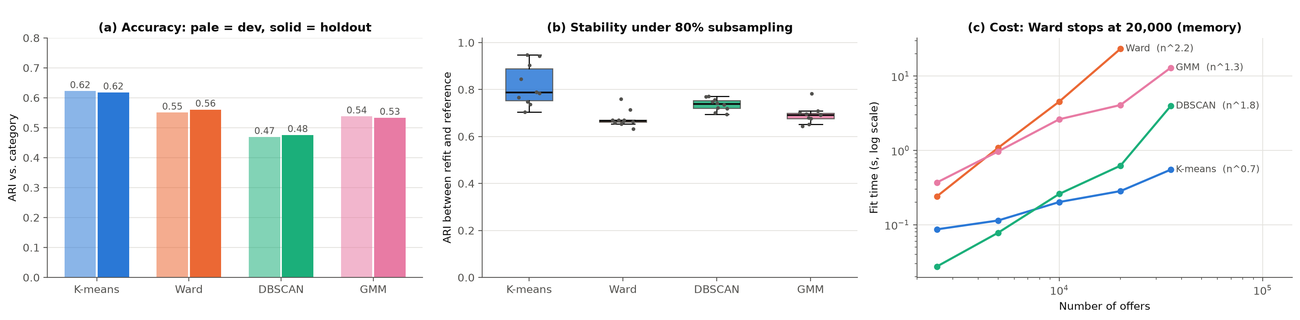
<br>
<i>Figure 16: Evidence for the deployment decision: (a) accuracy on unseen offers, (b) stability under subsampling, (c) fit time against n.</i>
</center>

| Evidence | K-means | Ward | DBSCAN | GMM |
|---|---|---|---|---|
| **Accuracy on 25,311 unseen offers** (ARI / NMI) | **0.62 / 0.70** | 0.56 / 0.69 | 0.48 / 0.65 | 0.53 / 0.65 |
| **Generalisation** (dev $\to$ unseen ARI) | 0.62 $\to$ 0.62 | 0.55 $\to$ 0.56 | 0.47 $\to$ 0.48 | 0.54 $\to$ 0.53 |
| **Stability** (mean ARI under 80 % resampling) | **0.82** | 0.68 | 0.74 | 0.69 |
| **Cost** | sub-second, near-linear in $n$ | $\approx n^2$ time, 5 GB of RAM at 35k offers | near-linear to quadratic | seconds to tens of seconds |
| **Scoring new offers** | native, one distance computation per centroid | nearest-neighbour proxy | nearest-core-point proxy, 19 % noise | native with probabilities |
| **What must be chosen** | $k$ | $k$ and linkage | `eps`, `min_samples` (fragile, Q3) | $k$, covariance type, initialisation |

<p align="justify">
<b>Why K-means.</b> It has the best accuracy and stability in the table, it is the cheapest, and it is the only model that is both accurate <i>and</i> simple to serve: the whole model is ten centroids. Its weaknesses (Q1) are real but did not bite on this data once the offers were mapped to the unit sphere, where category groups are roughly spherical caps.
</p>

<p align="justify">
<b>Why not the others.</b> <i>Ward</i>: slightly lower accuracy and the lowest stability, with quadratic memory (35k offers already need 5 GB; a catalogue of millions is out of reach) and no <code>predict()</code>. <i>DBSCAN</i>: leaves about 19 % of offers unlabelled, depends on two fragile parameters and returns 15 groups that do not map to the 10 categories; keep it as an <b>outlier / near-duplicate detector</b>, not as the category assigner. <i>GMM</i>: the most flexible and the only soft model, but ARI is about 0.08 lower, it is far slower to fit (tens of seconds against under a second), EM depends on initialisation, and its extra flexibility did not pay on unit-sphere LSA features.
</p>

<p align="justify">
<b>How strong is the evidence?</b> K-means' own seed-to-seed spread is about 0.04 ARI (10 seeds: 0.54-0.63), so its lead over Ward (+0.06 to +0.07 ARI, +0.02 NMI) is modest and not decisive on accuracy alone; its leads over GMM (+0.08) and DBSCAN (+0.15) are clearer. K-means partitions vary the most across resamples (sd 0.09), yet even its worst refit (0.71) agrees more with the reference than the <i>average</i> Ward refit (0.68). The decision therefore rests on accuracy <b>plus</b> stability, cost and serving simplicity together.
</p>

<p align="justify">
<b>Operating it</b> (prototype in the notebook; the fitted pipeline is saved to <code>models/kmeans_deployment.joblib</code>):
</p>

1. **Score** a new title with the saved TF-IDF, SVD, normalisation and centroids; report the **confidence margin** $1-d_1/d_2$ (distance to the nearest vs second-nearest centroid). Route low-margin offers (for example $<0.2$) to human review.
2. **Pre-process language:** detect German titles and translate or route them separately (the largest observed error source, Section 4.1).
3. **Monitor drift** weekly: mean distance to centroid, cluster-share shift, and ARI against the previous model on a fixed audit set; **refit monthly** or when drift crosses a threshold.
4. **Revisit the choice if requirements change:** soft memberships needed $\to$ GMM (tied covariance); noise filtering needed $\to$ DBSCAN pre-filter; a small catalogue that needs a hierarchy $\to$ Ward.

<p align="justify">
<b>A caution on the evidence.</b> An ARI of 0.62 is good but not high. When labels exist, a <i>supervised</i> classifier is the right tool for assigning categories; clustering earns its place for unlabelled merchants, for discovering structure, and for bootstrapping labels.
</p>

## **10. Limitations and Next Steps**

- **Text only.** Offers are described by short titles. Language mixing (German vs English) creates clusters unrelated to category; translation, language ID or multilingual embeddings are the first improvements, and images or attributes would help the fridge/freezer boundary.
- **One dataset, one split.** Results come from one stratified 10,000-offer dev sample and one 25,311-offer holdout; differences below about 0.04 ARI (the K-means seed spread) should not be over-read.
- **Label-informed choices.** $k = 10$ and the embedding size use external knowledge (disclosed); every other tuning step is label-free.
- **Fixed embedding.** TF-IDF + LSA is a simple baseline; sentence embeddings may separate categories better and change the ranking.
- **Timings** are from one laptop run and vary by machine; the *scaling exponents* and memory formulas carry the message.

## **11. Reproducibility**

| Item | Detail |
|---|---|
| Run | `jupyter nbconvert --to notebook --execute Clustering_Assignment.ipynb` from the assignment folder (about 10 minutes) |
| Input | `pricerunner_aggregate.csv` in the same folder |
| Packages | see `requirements.txt` (Python 3.14, scikit-learn 1.9, pandas 3.1, numpy 2.5, scipy 1.18, matplotlib 3.11, seaborn 0.13) |
| Seeds | every random step uses seed 42 (or an explicit seed list) |
| Colab | Open the notebook in Colab from GitHub; the first code cell downloads `pricerunner_aggregate.csv` from the repository (or asks for an upload); then Runtime > Run all (slower than a 12-thread laptop) |
| Outputs | `images/` (16 figures), `results/` (CSV/JSON tables quoted above), `models/kmeans_deployment.joblib` |


---
<a id="partb"></a>
## **Part B. Implementation walkthrough**

<p align="justify">Everything below is executable. Each step has its code, its output and a short commentary, in the order the analysis was done; the numbers quoted in the report above come from these cells.
(In Google Colab the first code cell downloads <code>pricerunner_aggregate.csv</code> from the repository, or asks you to upload it; then <i>Runtime, Run all</i>.)</p>

**Contents** &nbsp; [B1 Data audit](#s3) · [B2 Features](#s4) · [B3 Choosing k](#s5) · [B4 K-means](#s6) · [B5 Agglomerative](#s7) · [B6 DBSCAN](#s8) · [B7 GMM](#s9) · [B8 Comparison](#s10) · [**B9 Q1**](#q1) · [**B10 Q2**](#q2) · [**B11 Q3**](#q3) · [**B12 Q4**](#q4) · [B13 Limits](#s15) · [B14 Reproducibility](#s16)

---

In [ ]:
# Make sure the data file sits next to the notebook (does nothing when it is already there).
# In Google Colab or a fresh clone it is downloaded from the GitHub repository; if that fails, Colab asks for an upload.
from pathlib import Path
DATA_URL = "https://raw.githubusercontent.com/sohailzulfiqarrao/aml-ms25igis-578135/main/Assignments/Assignment%202/pricerunner_aggregate.csv"
if not Path("pricerunner_aggregate.csv").exists():
    try:
        import urllib.request
        urllib.request.urlretrieve(DATA_URL, "pricerunner_aggregate.csv")
        print("Downloaded pricerunner_aggregate.csv from the repository.")
    except Exception as err:
        print("Download failed:", err)
        try:
            from google.colab import files                  # raises ImportError outside Colab
            print("Select pricerunner_aggregate.csv in the dialog below ...")
            files.upload()
        except ImportError:
            pass
    assert Path("pricerunner_aggregate.csv").exists(), "Place pricerunner_aggregate.csv next to the notebook"

In [1]:
# ==============================================================================
# ENVIRONMENT, REPRODUCIBILITY AND PLOT STYLE
# ==============================================================================
import time, json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from matplotlib.colors import LinearSegmentedColormap
from cycler import cycler
import seaborn as sns
from IPython.display import display

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN, HDBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.manifold import TSNE
from sklearn.datasets import make_blobs, make_moons, make_circles
from sklearn.metrics import (adjusted_rand_score, normalized_mutual_info_score,
                             homogeneity_completeness_v_measure, silhouette_score,
                             davies_bouldin_score, calinski_harabasz_score)
from scipy.cluster.hierarchy import linkage, dendrogram, cophenet, fcluster
from scipy.spatial.distance import pdist
from scipy.stats import norm

warnings.filterwarnings("ignore")
SEED = 42
DATA = Path("pricerunner_aggregate.csv")
IMG, RES = Path("images"), Path("results")
IMG.mkdir(exist_ok=True); RES.mkdir(exist_ok=True)

# Validated categorical palette (blue, orange, aqua, yellow, magenta, green, violet, red) + 2 neutrals
PAL = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100",
           magenta="#e87ba4", green="#008300", violet="#6250d6", red="#e34948")
CAT10 = list(PAL.values()) + ["#6b6a66", "#0d366b"]
# one colour per algorithm, used consistently in every figure
ALGO = ["K-means", "Agglomerative (Ward)", "DBSCAN", "GMM"]
ALGO_COL = {"K-means": PAL["blue"], "Agglomerative (Ward)": PAL["orange"],
            "DBSCAN": PAL["aqua"], "GMM": PAL["magenta"]}
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
BLUES = LinearSegmentedColormap.from_list("blues", ["#f4f8fd", "#cde2fb", "#86b6ef", "#2a78d6", "#184f95", "#0d366b"])

mpl.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 200, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "axes.titlecolor": INK, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelsize": 10, "font.size": 10,
    "legend.frameon": False, "axes.prop_cycle": cycler(color=list(PAL.values())),
    "lines.linewidth": 2.0, "figure.autolayout": False,
})

def savefig(name):
    plt.savefig(IMG / f"{name}.png", bbox_inches="tight", dpi=200)
    plt.show()

def pct(x): return f"{100 * x:.1f}%"
print("Libraries loaded. Random seed:", SEED)

Libraries loaded. Random seed: 42


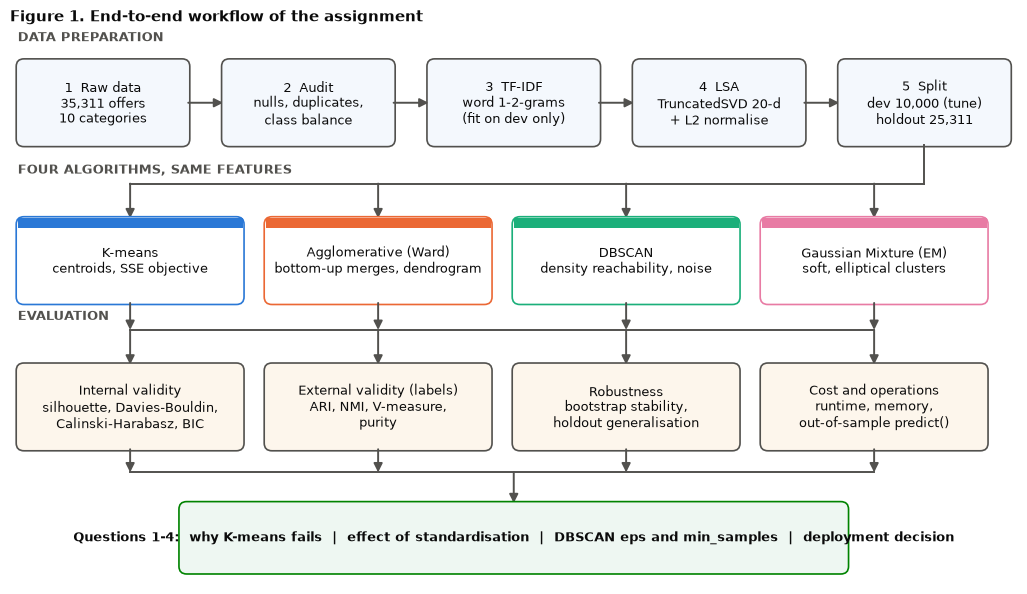

In [2]:
# ==============================================================================
# WORKFLOW DIAGRAM
# ==============================================================================
def box(ax, x, y, w, h, text, fc="#f4f8fd", ec=INK2, fs=9, bold=False, tc=INK):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.1", fc=fc, ec=ec, lw=1.2))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs, color=tc,
            fontweight="bold" if bold else "normal", linespacing=1.3)

def arrow(ax, p1, p2, color=INK2):
    ax.add_patch(FancyArrowPatch(p1, p2, arrowstyle="-|>", mutation_scale=13, lw=1.4, color=color, shrinkA=0, shrinkB=0))

fig, ax = plt.subplots(figsize=(13, 7.2)); ax.set_xlim(0, 13); ax.set_ylim(0, 7.2); ax.axis("off"); ax.grid(False)
# Row 1: data preparation
steps = ["1  Raw data\n35,311 offers\n10 categories", "2  Audit\nnulls, duplicates,\nclass balance",
         "3  TF-IDF\nword 1-2-grams\n(fit on dev only)", "4  LSA\nTruncatedSVD 20-d\n+ L2 normalise",
         "5  Split\ndev 10,000 (tune)\nholdout 25,311"]
xs = [0.1 + i * 2.65 for i in range(5)]
for i, (x, s) in enumerate(zip(xs, steps)):
    box(ax, x, 5.7, 2.2, 1.1, s, fc="#f4f8fd")
    if i: arrow(ax, (xs[i - 1] + 2.2, 6.25), (x, 6.25))
ax.text(0.1, 7.05, "DATA PREPARATION", fontsize=9, fontweight="bold", color=INK2)
# Row 2: four algorithms
mx = [0.1 + i * 3.2 for i in range(4)]
labels = ["K-means\ncentroids, SSE objective", "Agglomerative (Ward)\nbottom-up merges, dendrogram",
          "DBSCAN\ndensity reachability, noise", "Gaussian Mixture (EM)\nsoft, elliptical clusters"]
ax.plot([mx[0] + 1.45, xs[4] + 1.1], [5.2, 5.2], color=INK2, lw=1.4); ax.plot([xs[4] + 1.1] * 2, [5.7, 5.2], color=INK2, lw=1.4)
for x, n, s in zip(mx, ALGO, labels):
    arrow(ax, (x + 1.45, 5.2), (x + 1.45, 4.75))
    box(ax, x, 3.65, 2.9, 1.1, s, fc="white", ec=ALGO_COL[n], bold=False, fs=9)
    ax.add_patch(plt.Rectangle((x, 4.62), 2.9, 0.13, color=ALGO_COL[n], lw=0))
ax.text(0.1, 5.33, "FOUR ALGORITHMS, SAME FEATURES", fontsize=9, fontweight="bold", color=INK2)
# Row 3: evaluation
ev = ["Internal validity\nsilhouette, Davies-Bouldin,\nCalinski-Harabasz, BIC", "External validity (labels)\nARI, NMI, V-measure,\npurity",
      "Robustness\nbootstrap stability,\nholdout generalisation", "Cost and operations\nruntime, memory,\nout-of-sample predict()"]
ax.plot([mx[0] + 1.45, mx[3] + 1.45], [3.3, 3.3], color=INK2, lw=1.4)
for x in mx: arrow(ax, (x + 1.45, 3.65), (x + 1.45, 3.3)); arrow(ax, (x + 1.45, 3.3), (x + 1.45, 2.85))
for x, s in zip(mx, ev): box(ax, x, 1.75, 2.9, 1.1, s, fc="#fdf6ec")
ax.text(0.1, 3.43, "EVALUATION", fontsize=9, fontweight="bold", color=INK2)
# Row 4: questions + decision
ax.plot([mx[0] + 1.45, mx[3] + 1.45], [1.45, 1.45], color=INK2, lw=1.4)
for x in mx: arrow(ax, (x + 1.45, 1.75), (x + 1.45, 1.45))
arrow(ax, (6.5, 1.45), (6.5, 1.05))
box(ax, 2.2, 0.15, 8.6, 0.9, "Questions 1-4:  why K-means fails  |  effect of standardisation  |  DBSCAN eps and min_samples  |  deployment decision",
    fc="#eef7f2", ec=PAL["green"], bold=True, fs=9.5)
plt.title("Figure 1. End-to-end workflow of the assignment", loc="left", pad=6)
savefig("fig01_workflow")

<a id="s3"></a>
## **B1. Data audit**

In [3]:
# ==============================================================================
# LOAD AND AUDIT THE DATA
# ==============================================================================
raw = pd.read_csv(DATA)
raw.columns = raw.columns.str.strip()          # the CSV header has leading spaces (" Merchant ID")
df = raw.copy()
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns\n")
display(df.head(6))

audit = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "unique": df.nunique(),
})
display(audit)
n_dup_titles = df["Product Title"].duplicated().sum()
print(f"Exact duplicate titles   : {n_dup_titles:,} ({pct(n_dup_titles / len(df))}) - same product listed identically by several merchants")
print(f"Distinct merchants       : {df['Merchant ID'].nunique()}")
print(f"Product clusters (ground truth, fine level)  : {df['Cluster ID'].nunique():,}")
print(f"Categories (ground truth, coarse level)      : {df['Category Label'].nunique()}")

Shape: 35,311 rows x 7 columns



,Product ID,Product Title,Merchant ID,Cluster ID,Cluster Label,Category ID,Category Label
0,1,apple iphone 8 plus 64gb silver,1,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones
1,2,apple iphone 8 plus 64 gb spacegrau,2,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones
2,3,apple mq8n2b/a iphone 8 plus 64gb 5.5 12mp sim...,3,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones
3,4,apple iphone 8 plus 64gb space grey,4,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones
4,5,apple iphone 8 plus gold 5.5 64gb 4g unlocked ...,5,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones
5,6,apple iphone 8 plus gold 5.5 64gb 4g unlocked ...,6,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones


,dtype,missing,unique
Product ID,int64,0,35311
Product Title,str,0,30993
Merchant ID,int64,0,306
Cluster ID,int64,0,13233
Cluster Label,str,0,12849
Category ID,int64,0,10
Category Label,str,0,10


Exact duplicate titles   : 4,318 (12.2%) - same product listed identically by several merchants
Distinct merchants       : 306
Product clusters (ground truth, fine level)  : 13,233
Categories (ground truth, coarse level)      : 10


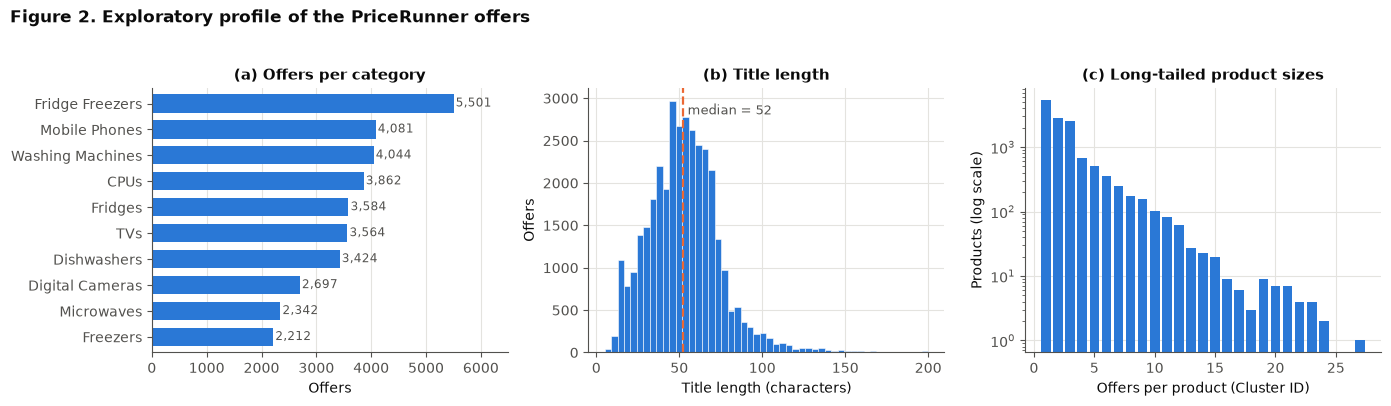

Largest / smallest category: 5,501 / 2,212 = 2.5x imbalance
Products with a single offer: 40.6%; median offers per product: 2


In [4]:
title_len = df["Product Title"].str.len()
cat_counts = df["Category Label"].value_counts()
prod_sizes = df.groupby("Cluster ID").size()

fig, axes = plt.subplots(1, 3, figsize=(14, 3.9))
ax = axes[0]
cat_counts.sort_values().plot.barh(ax=ax, color=PAL["blue"], width=0.7)
for i, v in enumerate(cat_counts.sort_values()): ax.text(v + 40, i, f"{v:,}", va="center", fontsize=8.5, color=INK2)
ax.set_xlim(0, cat_counts.max() * 1.18); ax.set_xlabel("Offers"); ax.set_ylabel(""); ax.grid(axis="y", visible=False)
ax.set_title("(a) Offers per category")
ax = axes[1]
ax.hist(title_len, bins=50, color=PAL["blue"], edgecolor="white", linewidth=0.4)
ax.axvline(title_len.median(), color=PAL["orange"], ls="--", lw=1.6); ax.text(title_len.median() + 3, ax.get_ylim()[1] * 0.9, f"median = {title_len.median():.0f}", color=INK2, fontsize=9)
ax.set_xlabel("Title length (characters)"); ax.set_ylabel("Offers"); ax.set_title("(b) Title length")
ax = axes[2]
vc = prod_sizes.value_counts().sort_index()
ax.bar(vc.index, vc.values, color=PAL["blue"], width=0.8); ax.set_yscale("log")
ax.set_xlabel("Offers per product (Cluster ID)"); ax.set_ylabel("Products (log scale)"); ax.set_title("(c) Long-tailed product sizes")
plt.suptitle("Figure 2. Exploratory profile of the PriceRunner offers", x=0.01, ha="left", fontweight="bold", y=1.03)
plt.tight_layout(); savefig("fig02_eda")
print(f"Largest / smallest category: {cat_counts.max():,} / {cat_counts.min():,} = {cat_counts.max() / cat_counts.min():.1f}x imbalance")
print(f"Products with a single offer: {pct((prod_sizes == 1).mean())}; median offers per product: {prod_sizes.median():.0f}")

**Findings.**

- **Clean and complete:** no missing values; the CSV header had stray leading spaces (`" Merchant ID"`), stripped on load.
- **Duplicates are real.** 4,318 offers (12.2 %) repeat another title exactly: the same product listed by several merchants. They are kept (they are genuine marketplace density) but they matter for DBSCAN, where identical points count towards `min_samples`.
- **Class imbalance 2.5 : 1** (5,501 fridge-freezers vs 2,212 freezers), relevant to Q1.
- **Short, noisy text:** median 52 characters (about 8 words); 40.6 % of products have a single offer; some titles are German (*geschirrspüler*, *einbau*, *kühlschrank*), which will matter later.

<a id="s4"></a>
## **B2. Feature engineering: from titles to a geometry**

1. **TF-IDF** on word 1- and 2-grams (`min_df = 3`, sublinear term frequency): $w_{t,d} = \big(1+\ln \mathrm{tf}_{t,d}\big)\cdot\Big(\ln\tfrac{1+N}{1+\mathrm{df}_t}+1\Big)$, then each title is scaled to unit length.
2. **Latent semantic analysis (LSA):** truncated SVD $X \approx U_k\Sigma_k V_k^{\top}$ keeps $k$ dense latent coordinates $Z = XV_k$. Raw TF-IDF is 6,083-dimensional and 99.8 % zeros, where Euclidean distances concentrate and clustering is poor.
3. **Row normalisation** $\hat z_i = z_i/\lVert z_i\rVert$, so that $\lVert\hat z_i-\hat z_j\rVert^2 = 2\,(1-\cos\theta_{ij})$. Euclidean K-means on $\hat z$ is therefore cosine (spherical) K-means, and DBSCAN's `eps` is a cosine-type distance ($\varepsilon = 0.475 \Rightarrow \cos\theta \ge 0.887$).

**How many latent dimensions?** Figure 3 shows K-means quality rising to a plateau (NMI $\approx 0.70$-$0.72$) from 20 dimensions upward, and Ward peaking at 20 (0.68) then declining. **20 dimensions** is the smallest size on the plateau (16.1 % of TF-IDF variance, which is normal for sparse text). This is the one place labels were consulted.

In [5]:
# ==============================================================================
# FEATURE ENGINEERING: TF-IDF -> LSA, AND THE dev / holdout SPLIT
# ==============================================================================
titles = df["Product Title"].astype(str).str.lower()
cat = df["Category Label"].astype("category")
CLASSES = list(cat.cat.categories)
y = cat.cat.codes.to_numpy()
K = len(CLASSES)

N_DEV = 10_000
idx_dev, idx_hold = train_test_split(np.arange(len(df)), train_size=N_DEV, stratify=y, random_state=SEED)
y_dev, y_hold = y[idx_dev], y[idx_hold]
print(f"dev: {len(idx_dev):,} offers (all tuning)   |   holdout: {len(idx_hold):,} offers (touched only for the final generalisation test)")

t0 = time.time()
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=3, sublinear_tf=True).fit(titles.iloc[idx_dev])   # fitted on dev ONLY
X_dev, X_hold = tfidf.transform(titles.iloc[idx_dev]), tfidf.transform(titles.iloc[idx_hold])
svd = TruncatedSVD(100, random_state=SEED).fit(X_dev)
S_dev, S_hold = svd.transform(X_dev), svd.transform(X_hold)
print(f"TF-IDF matrix (dev): {X_dev.shape[0]:,} x {X_dev.shape[1]:,}, {pct(X_dev.nnz / np.prod(X_dev.shape))} non-zero   ({time.time() - t0:.1f}s)")

def embed(S, n):
    """Keep the first n latent dimensions and put every row on the unit sphere (cosine geometry)."""
    return normalize(S[:, :n])

dev: 10,000 offers (all tuning)   |   holdout: 25,311 offers (touched only for the final generalisation test)


TF-IDF matrix (dev): 10,000 x 6,083, 0.2% non-zero   (1.9s)


,n_components,cum_variance,NMI_kmeans,NMI_ward
0,5,0.063,0.562,0.566
1,10,0.104,0.604,0.664
2,15,0.135,0.671,0.671
3,20,0.161,0.702,0.681
4,30,0.204,0.718,0.654
5,40,0.238,0.683,0.608
6,50,0.267,0.721,0.674
7,75,0.324,0.713,0.597
8,100,0.367,0.719,0.591


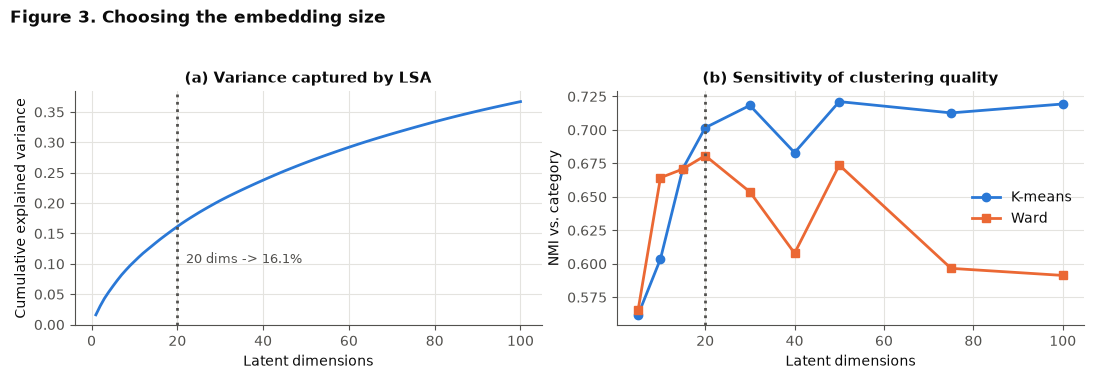

In [6]:
# Representation sensitivity: how many latent dimensions?  (labels used here ONLY to validate this one preprocessing choice)
dims = [5, 10, 15, 20, 30, 40, 50, 75, 100]
rows = []
for n in dims:
    Zn = embed(S_dev, n)
    km_scores = [normalized_mutual_info_score(y_dev, KMeans(K, n_init=10, random_state=s).fit_predict(Zn)) for s in range(3)]
    wd = AgglomerativeClustering(K, linkage="ward").fit_predict(Zn)
    rows.append(dict(n_components=n, cum_variance=svd.explained_variance_ratio_[:n].sum(),
                     NMI_kmeans=np.mean(km_scores), NMI_ward=normalized_mutual_info_score(y_dev, wd)))
dim_sweep = pd.DataFrame(rows)
display(dim_sweep.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axes[0]
cv = np.cumsum(svd.explained_variance_ratio_)
ax.plot(np.arange(1, 101), cv, color=PAL["blue"]); ax.set_xlabel("Latent dimensions"); ax.set_ylabel("Cumulative explained variance")
ax.axvline(20, color=INK2, ls=":"); ax.text(22, cv[19] - 0.06, f"20 dims -> {pct(cv[19])}", fontsize=9, color=INK2)
ax.set_title("(a) Variance captured by LSA")
ax = axes[1]
ax.plot(dim_sweep.n_components, dim_sweep.NMI_kmeans, marker="o", color=ALGO_COL["K-means"], label="K-means")
ax.plot(dim_sweep.n_components, dim_sweep.NMI_ward, marker="s", color=ALGO_COL["Agglomerative (Ward)"], label="Ward")
ax.axvline(20, color=INK2, ls=":"); ax.set_xlabel("Latent dimensions"); ax.set_ylabel("NMI vs. category"); ax.legend(); ax.set_title("(b) Sensitivity of clustering quality")
plt.suptitle("Figure 3. Choosing the embedding size", x=0.01, ha="left", fontweight="bold", y=1.04)
plt.tight_layout(); savefig("fig03_embedding_size")

In [7]:
N_COMP = 20
Z_dev, Z_hold = embed(S_dev, N_COMP), embed(S_hold, N_COMP)
print(f"Final feature space: {Z_dev.shape[1]} latent dimensions, unit-norm rows, {pct(cv[N_COMP - 1])} of TF-IDF variance retained")

# ---------- shared evaluation helpers ----------
def external_scores(y_true, lab):
    h, c, v = homogeneity_completeness_v_measure(y_true, lab)
    purity = pd.crosstab(lab, y_true).max(axis=1).sum() / len(y_true)
    return dict(ARI=adjusted_rand_score(y_true, lab), NMI=normalized_mutual_info_score(y_true, lab),
                Homogeneity=h, Completeness=c, V_measure=v, Purity=purity)

def internal_scores(Z, lab, sample=None):
    m = lab != -1                              # noise points carry no cluster, so they are excluded
    if len(np.unique(lab[m])) < 2: return dict(Silhouette=np.nan, Davies_Bouldin=np.nan, Calinski_Harabasz=np.nan)
    Zm, lm = Z[m], lab[m]
    ss = None if sample is None or len(lm) <= sample else sample
    return dict(Silhouette=silhouette_score(Zm, lm, sample_size=ss, random_state=SEED),
                Davies_Bouldin=davies_bouldin_score(Zm, lm), Calinski_Harabasz=calinski_harabasz_score(Zm, lm))

def n_clusters(lab): return len(set(lab)) - (1 if -1 in lab else 0)

MODELS = {}                                    # name -> dict(labels, fit_seconds, estimator)
def register(name, lab, secs, est=None): MODELS[name] = dict(labels=lab, secs=secs, est=est)

Final feature space: 20 latent dimensions, unit-norm rows, 16.1% of TF-IDF variance retained


<a id="s5"></a>
## **B3. How many clusters?**

No internal index points at $k = 10$: inertia falls smoothly, while silhouette, Calinski-Harabasz and Davies-Bouldin keep improving and are best at **$k = 19$** (Figure 4). The reason is structural: every category contains many brand/model families, so finer partitions always look "tighter". External NMI is flat at about 0.67-0.72 for $k = 9$-$14$. We therefore fix **$k = 10$ from the business taxonomy** (and say so), rather than pretend the data select it. The same $k$ is used for K-means, Ward and GMM; DBSCAN chooses its own number of clusters.

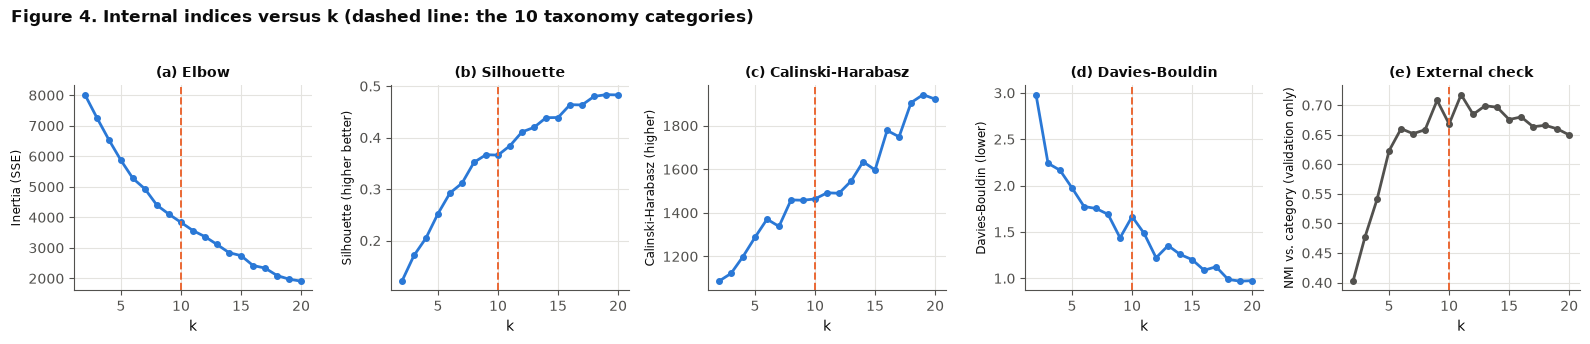

Best k by silhouette: 19 | by Calinski-Harabasz: 19 | by Davies-Bouldin: 19 | by NMI (external): 11


,inertia,silhouette,calinski,davies_bouldin,NMI
k,,,,,
6,5272.709,0.292,1370.813,1.774,0.660
8,4395.468,0.352,1459.219,1.690,0.658
9,4101.458,0.367,1457.733,1.437,0.708
10,3833.502,0.366,1463.783,1.666,0.668
11,3564.845,0.384,1491.826,1.485,0.718
12,3365.986,0.411,1489.828,1.221,0.684
14,2842.018,0.439,1634.360,1.257,0.696
19,1974.118,0.483,1942.238,0.969,0.660


In [8]:
# ==============================================================================
# HOW MANY CLUSTERS?  (K-means as the probe)
# ==============================================================================
ks = list(range(2, 21))
rows = []
for k in ks:
    km = KMeans(k, n_init=5, random_state=SEED).fit(Z_dev)
    rows.append(dict(k=k, inertia=km.inertia_, silhouette=silhouette_score(Z_dev, km.labels_, sample_size=5000, random_state=SEED),
                     calinski=calinski_harabasz_score(Z_dev, km.labels_), davies_bouldin=davies_bouldin_score(Z_dev, km.labels_),
                     NMI=normalized_mutual_info_score(y_dev, km.labels_)))
ksweep = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 5, figsize=(16, 3.3))
spec = [("inertia", "Inertia (SSE)", "(a) Elbow"), ("silhouette", "Silhouette (higher better)", "(b) Silhouette"),
        ("calinski", "Calinski-Harabasz (higher)", "(c) Calinski-Harabasz"), ("davies_bouldin", "Davies-Bouldin (lower)", "(d) Davies-Bouldin"),
        ("NMI", "NMI vs. category (validation only)", "(e) External check")]
for ax, (col, yl, ttl) in zip(axes, spec):
    ax.plot(ksweep.k, ksweep[col], marker="o", ms=4, color=PAL["blue"] if col != "NMI" else INK2)
    ax.axvline(K, color=PAL["orange"], ls="--", lw=1.4); ax.set_xlabel("k"); ax.set_ylabel(yl, fontsize=8.5); ax.set_title(ttl, fontsize=10)
plt.suptitle("Figure 4. Internal indices versus k (dashed line: the 10 taxonomy categories)", x=0.01, ha="left", fontweight="bold", y=1.03)
plt.tight_layout(); savefig("fig04_choose_k")
print("Best k by silhouette:", int(ksweep.loc[ksweep.silhouette.idxmax(), "k"]), "| by Calinski-Harabasz:", int(ksweep.loc[ksweep.calinski.idxmax(), "k"]),
      "| by Davies-Bouldin:", int(ksweep.loc[ksweep.davies_bouldin.idxmin(), "k"]), "| by NMI (external):", int(ksweep.loc[ksweep.NMI.idxmax(), "k"]))
display(ksweep[ksweep.k.isin([6, 8, 9, 10, 11, 12, 14, 19])].set_index("k").round(3))

<a id="s6"></a>
## **B4. Algorithm 1: K-means**

**Objective.** Find centroids $\mu_1..\mu_K$ minimising the within-cluster sum of squares $J=\sum_{k}\sum_{x\in C_k}\lVert x-\mu_k\rVert^2$. **Lloyd's algorithm** alternates *assign* (each point to its nearest centroid) and *update* ($\mu_k \leftarrow$ mean of $C_k$); $J$ never increases, so it converges, but only to a **local** minimum, hence k-means++ seeding and many restarts. Cost per run is $O(n\,K\,D\,I)$ time and $O(nD)$ memory.

The first cell below is a from-scratch implementation. Started from the same centroids, it reaches **exactly** the same partition as scikit-learn (ARI = 1.0000, identical inertia). Using 20 restarts, scikit-learn then finds a slightly better optimum (inertia 3,810 vs 3,840), a reminder that K-means results depend on initialisation.

In [9]:
# ==============================================================================
# ALGORITHM 1 - K-MEANS (Lloyd's algorithm from scratch, validated against scikit-learn)
# ==============================================================================
def kmeans_scratch(X, k, n_iter=300, seed=0, tol=1e-9, init=None):
    """k-means++ seeding followed by Lloyd iterations: assign -> update, until the centroids stop moving."""
    rng = np.random.default_rng(seed)
    if init is None:
        C = [X[rng.integers(len(X))]]
        for _ in range(1, k):                                   # k-means++: next centre drawn with probability proportional to D(x)^2
            d2 = np.min(((X[:, None, :] - np.asarray(C)[None]) ** 2).sum(-1), axis=1)
            C.append(X[rng.choice(len(X), p=d2 / d2.sum())])
        C = np.asarray(C)
    else:
        C = np.array(init, dtype=float)
    C0 = C.copy()
    for it in range(1, n_iter + 1):
        d2 = ((X[:, None, :] - C[None]) ** 2).sum(-1)           # squared distance of every point to every centroid
        lab = d2.argmin(1)                                      # assignment step
        newC = np.array([X[lab == j].mean(0) if np.any(lab == j) else C[j] for j in range(k)])   # update step
        if np.abs(newC - C).max() < tol: break
        C = newC
    return lab, C, d2[np.arange(len(X)), lab].sum(), it, C0

# (1) Correctness check: from the SAME starting centroids, both implementations must reach the SAME partition.
lab_s, C_s, inertia_s, iters_s, C0 = kmeans_scratch(Z_dev, K, seed=0)
ref = KMeans(K, init=C0, n_init=1, algorithm="lloyd", tol=0, max_iter=300).fit(Z_dev)
print(f"Same initial centroids -> from-scratch inertia {inertia_s:.4f} ({iters_s} it.) | scikit-learn inertia {ref.inertia_:.4f} ({ref.n_iter_} it.) | ARI between partitions = {adjusted_rand_score(lab_s, ref.labels_):.4f}")

# (2) Production fit: many restarts guard against poor local minima (K-means is non-convex)
t0 = time.time()
best = min((kmeans_scratch(Z_dev, K, seed=s) for s in range(20)), key=lambda r: r[2])
t_scratch = time.time() - t0
t0 = time.time()
km = KMeans(K, init="k-means++", n_init=20, random_state=SEED).fit(Z_dev)
t_km = time.time() - t0
register("K-means", km.labels_, t_km, km)
print(f"Best of 20 restarts : from-scratch inertia = {best[2]:.2f} ({t_scratch:.1f}s) | scikit-learn inertia = {km.inertia_:.2f} ({t_km:.1f}s) | ARI = {adjusted_rand_score(best[0], km.labels_):.3f}")

Same initial centroids -> from-scratch inertia 4498.9570 (18 it.) | scikit-learn inertia 4498.9570 (17 it.) | ARI between partitions = 1.0000


Best of 20 restarts : from-scratch inertia = 3840.46 (8.5s) | scikit-learn inertia = 3809.98 (0.3s) | ARI = 0.802


In [10]:
vocab = np.array(tfidf.get_feature_names_out())
def cluster_table(lab, X=X_dev, top=6, min_size=1):
    rows = []
    for c in sorted(set(lab) - {-1}):
        m = lab == c
        if m.sum() < min_size: continue
        top_terms = vocab[np.asarray(X[m].mean(axis=0)).ravel().argsort()[::-1][:top]]
        counts = np.bincount(y_dev[m], minlength=K)
        rows.append(dict(cluster=c, size=int(m.sum()), majority_category=CLASSES[counts.argmax()], purity=counts.max() / m.sum(), top_terms=", ".join(top_terms)))
    return pd.DataFrame(rows).sort_values("size", ascending=False).reset_index(drop=True)

km_table = cluster_table(MODELS["K-means"]["labels"])
display(km_table.style.format({"purity": "{:.0%}"}).hide(axis="index"))

cluster,size,majority_category,purity,top_terms
0,1372,Fridge Freezers,81%,"freezer, fridge freezer, fridge, frost, frost free, free"
4,1224,Dishwashers,54%,"bosch, dishwasher, washer, integrated, dryer, washer dryer"
1,1123,Mobile Phones,94%,"sim, phone, mobile, mobile phone, samsung, sim free"
8,1105,Fridges,50%,"liebherr, fridge, white, freezer, larder, under"
3,1096,CPUs,99%,"intel, processor, core, ghz, xeon, intel xeon"
2,967,TVs,97%,"tv, led, hd, smart, 4k, led tv"
6,876,Digital Cameras,86%,"camera, digital, canon, sony, black, body"
7,868,Dishwashers,30%,"siemens, ler, geschirrsp ler, geschirrsp, einbau, gorenje"
5,740,Washing Machines,100%,"washing, machine, washing machine, white, spin, machine white"
9,629,Microwaves,84%,"microwave, oven, microwave oven, steel, stainless steel, stainless"


In [11]:
# Cluster 7 and its look-alikes mix categories. A quick diagnostic: how many offers per K-means cluster are German-language titles?
german = titles.iloc[idx_dev].str.contains(r"\b(?:einbau\w*|geschirrsp\w*|hlschrank\w*|gefrier\w*|edelstahl|waschmaschine\w*|unterbau\w*|k hlschrank|freistehend\w*)\b", regex=True).to_numpy()
by_cluster = pd.DataFrame({"cluster": MODELS["K-means"]["labels"], "german_marker": german}).groupby("cluster").german_marker.mean().rename("share with a German marker word")
print(f"German marker words appear in {pct(german.mean())} of dev titles overall.")
display(by_cluster.to_frame().T.style.format("{:.0%}"))

German marker words appear in 7.0% of dev titles overall.


cluster,0,1,2,3,4,5,6,7,8,9
share with a German marker word,0%,0%,0%,0%,3%,0%,0%,72%,3%,0%


**Reading the clusters.** Seven of ten clusters are at least 80 % pure (CPUs 99 %, washing machines 99.9 %, TVs 97 %, mobile phones 94 %, cameras 86 %, microwaves 84 %, fridge-freezers 81 %). Three are mixed. Cluster 7 is not a category at all: **72 % of its offers contain German marker words** (vs 0-3 % in the other clusters) so K-means has grouped by *language*, a nuisance direction in the embedding. Clusters 4 (dishwashers 54 %, washing machines 26 %) and 8 (fridges 50 %, freezers 30 %) mix neighbouring appliance types whose titles share vocabulary.

<a id="s7"></a>
## **B5. Algorithm 2: Agglomerative hierarchical clustering**

Every offer starts as its own cluster; the two closest clusters are merged repeatedly. **Ward linkage** merges the pair with the smallest increase in within-cluster variance,
$$\Delta(A,B)=\frac{n_A\,n_B}{n_A+n_B}\,\lVert\mu_A-\mu_B\rVert^2,$$
the same sum-of-squares criterion as K-means, so its clusters are compact. Exact agglomeration needs the full pairwise-distance matrix: **$O(n^2)$ memory and $\ge O(n^2)$ time**, the main limitation (Section B12).

**Linkage comparison** (3,000-offer subsample). *Single* linkage chains almost everything into one cluster (96.8 % of offers, ARI 0.003); *complete* linkage is poor (ARI 0.27); *Ward* and *average* are close (ARI 0.52 vs 0.54, NMI 0.67 vs 0.68; differences of this size are within sampling noise). **Ward** is used because it optimises the same criterion as K-means and has the clean $\Delta$ interpretation above. The dendrogram (Figure 5) shows no sharp gap in merge cost at $k=10$: the cut is again imposed by the taxonomy.

In [12]:
# ==============================================================================
# ALGORITHM 2 - AGGLOMERATIVE HIERARCHICAL CLUSTERING
# ==============================================================================
# Which linkage? Compared on a 3,000-offer subsample (the exact algorithm stores an n x n matrix)
rs = np.random.default_rng(SEED)
sub = rs.choice(len(Z_dev), 3000, replace=False)
Zs, ys = Z_dev[sub], y_dev[sub]
rows, LINKS = [], {}
for method in ["ward", "average", "complete", "single"]:
    L = linkage(Zs, method=method)
    LINKS[method] = L
    coph, _ = cophenet(L, pdist(Zs))
    lab = fcluster(L, K, criterion="maxclust")
    rows.append(dict(linkage=method, cophenetic_corr=coph, ARI=adjusted_rand_score(ys, lab), NMI=normalized_mutual_info_score(ys, lab),
                     largest_cluster_share=np.bincount(lab).max() / len(lab)))
link_cmp = pd.DataFrame(rows)
display(link_cmp.round(3))

,linkage,cophenetic_corr,ARI,NMI,largest_cluster_share
0,ward,0.732,0.517,0.667,0.265
1,average,0.885,0.537,0.677,0.285
2,complete,0.772,0.268,0.436,0.259
3,single,0.516,0.003,0.056,0.968


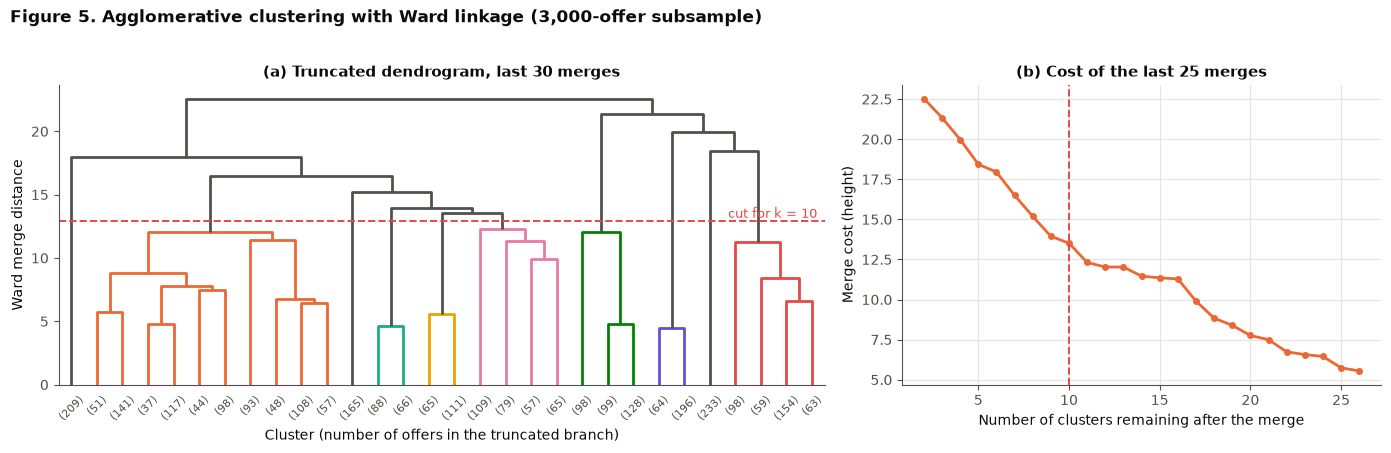

In [13]:
# Dendrogram (Ward) and merge-height profile
L = LINKS["ward"]
cut = (L[-K, 2] + L[-(K - 1), 2]) / 2            # height that leaves exactly K clusters
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw=dict(width_ratios=[1.6, 1]))
ax = axes[0]
dendrogram(L, truncate_mode="lastp", p=30, color_threshold=cut, ax=ax, no_labels=False, leaf_font_size=8, above_threshold_color=INK2, show_leaf_counts=True)
ax.axhline(cut, color=PAL["red"], ls="--", lw=1.4); ax.text(ax.get_xlim()[1] * 0.99, cut * 1.02, f"cut for k = {K}", color=PAL["red"], fontsize=9, ha="right")
ax.set_ylabel("Ward merge distance"); ax.set_xlabel("Cluster (number of offers in the truncated branch)"); ax.grid(False); ax.set_title("(a) Truncated dendrogram, last 30 merges")
ax = axes[1]
h = L[-25:, 2][::-1]; kk = np.arange(2, 27)
ax.plot(kk, h, marker="o", ms=4, color=ALGO_COL["Agglomerative (Ward)"])
ax.axvline(K, color=PAL["red"], ls="--", lw=1.4); ax.set_xlabel("Number of clusters remaining after the merge"); ax.set_ylabel("Merge cost (height)")
ax.set_title("(b) Cost of the last 25 merges")
plt.suptitle("Figure 5. Agglomerative clustering with Ward linkage (3,000-offer subsample)", x=0.01, ha="left", fontweight="bold", y=1.02)
plt.tight_layout(); savefig("fig05_dendrogram")

In [14]:
# Final model on the full dev set
t0 = time.time()
ward = AgglomerativeClustering(n_clusters=K, linkage="ward").fit(Z_dev)
t_ward = time.time() - t0
register("Agglomerative (Ward)", ward.labels_, t_ward, ward)
print(f"Ward fit on {len(Z_dev):,} offers: {t_ward:.1f}s; memory for the pairwise matrix ~ {len(Z_dev) * (len(Z_dev) - 1) / 2 * 8 / 1e9:.2f} GB")
display(cluster_table(ward.labels_).style.format({"purity": "{:.0%}"}).hide(axis="index"))

Ward fit on 10,000 offers: 5.5s; memory for the pairwise matrix ~ 0.40 GB


cluster,size,majority_category,purity,top_terms
3,1907,Fridge Freezers,60%,"freezer, fridge, fridge freezer, liebherr, frost, smeg"
0,1781,Fridges,26%,"bosch, white, fridge, hotpoint, in, washer"
1,1158,Mobile Phones,92%,"sim, phone, samsung, mobile, mobile phone, black"
2,1082,CPUs,99%,"intel, processor, core, ghz, xeon, intel xeon"
7,955,TVs,97%,"tv, hd, led, smart, 4k, led tv"
9,871,Digital Cameras,86%,"camera, digital, canon, sony, body, digital camera"
5,736,Washing Machines,100%,"washing, machine, washing machine, white, spin, machine white"
8,541,Dishwashers,96%,"dishwasher, integrated dishwasher, integrated, place, fully, fully integrated"
6,493,Fridge Freezers,35%,"siemens, gorenje, einbau, hl, eek, hl gefrier"
4,476,Microwaves,98%,"microwave, oven, microwave oven, steel, in, built in"


**Reading the clusters.** Ward isolates CPUs (99 %), washing machines (99.9 %), TVs (97 %), microwaves (98 %), dishwashers (96 %) and mobile phones (92 %) well, but it puts 1,781 offers in a mixed "bosch, white, hotpoint, washer" cluster (26 % fridges) and, like K-means, creates a German-language cluster (cluster 6, 36 % fridge-freezers).

<a id="s8"></a>
## **B6. Algorithm 3: DBSCAN and principled parameter selection (basis for Q3)**

**Definitions.** For radius $\varepsilon$ and threshold $m$ (`min_samples`, counting the point itself): a point is a **core point** if $|N_\varepsilon(p)|\ge m$; a point is a **border point** if it is within $\varepsilon$ of a core point but is not core; clusters are the connected components of core points plus their border points; all remaining points are **noise** ($-1$). DBSCAN needs no $k$, finds arbitrarily shaped clusters, and labels outliers.

**The selection procedure (no labels, no guessing)**

1. **Range for `min_samples`** from the dimension rule $m \ge D+1$ (here $D = 20$), the common default being $m = 2D$ (Sander et al., 1998); larger values for noisy, duplicated data. We scan $m \in \{5,\dots,320\}$.
2. **Upper bound for `eps`** from the **k-distance curve**: sort every point's distance to its $m$-th neighbour and take the knee (farthest point below the chord, Kneedle style).
3. **Scan below the knee** with a (`min_samples` $\times$ `eps`) grid and score every cell *without labels*: $\;\text{score}=(1-\text{noise fraction})\times\text{silhouette of the clustered points}\;$, subject to a **percolation guard** (at least 2 clusters and no cluster holding more than 50 % of the data). The score rewards tight clusters *and* coverage; without the noise factor, silhouette alone would reward discarding almost everything.
4. **Check the plateau and stability**, and only then compare with labels.

Result below: (a) the knee **overshoots** (Figure 6 and the table: from `min_samples` = 40 upward, the knee `eps` merges at least 94 % of the clustered points into one cluster); (b) the grid optimum is **interior** (score 0.401, 0.441, 0.446, **0.451** at `min_samples` 40, 80, 120, **160**, then falls to 0.348 at 240), with a plateau over 80-160; (c) the selected cell is `min_samples` = 160, `eps` = 0.475.

In [15]:
# ==============================================================================
# ALGORITHM 3 - DBSCAN, WITH PRINCIPLED PARAMETER SELECTION  (answers Question 3)
# ==============================================================================
# Step 1: k-distance curves.  sklearn counts the point itself in min_samples, so the relevant distance is the
# distance to the (min_samples)-th nearest point INCLUDING itself  (= column min_samples-1 of kneighbors).
MS_GRID = [5, 10, 20, 40, 80, 120, 160, 240, 320]
nnb = NearestNeighbors(n_neighbors=max(MS_GRID)).fit(Z_dev)
dist_all, _ = nnb.kneighbors(Z_dev)

def kdist(ms): return np.sort(dist_all[:, ms - 1])
def knee_index(d):
    """Kneedle-style knee of an increasing convex curve: the point farthest below the chord joining its end points."""
    x = np.linspace(0, 1, len(d)); yv = (d - d.min()) / (d.max() - d.min())
    return int(np.argmax(x - yv))

knees = {ms: kdist(ms)[knee_index(kdist(ms))] for ms in MS_GRID}
print("k-distance knee  ->  eps suggested by the curve")
for ms in MS_GRID:
    d = kdist(ms); i = knee_index(d)
    print(f"  min_samples = {ms:>2}:  eps_knee = {knees[ms]:.3f}   (knee at percentile {100 * i / len(d):.0f} of the sorted curve)")

k-distance knee  ->  eps suggested by the curve
  min_samples =  5:  eps_knee = 0.244   (knee at percentile 85 of the sorted curve)
  min_samples = 10:  eps_knee = 0.315   (knee at percentile 85 of the sorted curve)
  min_samples = 20:  eps_knee = 0.448   (knee at percentile 90 of the sorted curve)
  min_samples = 40:  eps_knee = 0.513   (knee at percentile 87 of the sorted curve)
  min_samples = 80:  eps_knee = 0.582   (knee at percentile 86 of the sorted curve)
  min_samples = 120:  eps_knee = 0.644   (knee at percentile 87 of the sorted curve)
  min_samples = 160:  eps_knee = 0.747   (knee at percentile 93 of the sorted curve)
  min_samples = 240:  eps_knee = 0.811   (knee at percentile 92 of the sorted curve)
  min_samples = 320:  eps_knee = 0.879   (knee at percentile 86 of the sorted curve)


In [16]:
# Step 2: sweep a (min_samples x eps) grid and score every cell WITHOUT using the labels.
# score = (1 - noise fraction) x silhouette of the clustered points  -> rewards tight clusters AND coverage.
# guard : the largest cluster must hold <= 50% of the data (otherwise eps has "percolated" and chained everything together).
EPS_GRID = np.round(np.arange(0.05, 0.7501, 0.025), 3)
rows = []
t0 = time.time()
for ms in MS_GRID:
    for eps in EPS_GRID:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(Z_dev)
        nc = n_clusters(lab); noise = (lab == -1).mean()
        largest = np.bincount(lab[lab != -1]).max() / len(lab) if nc else 0.0
        sil = internal_scores(Z_dev, lab, sample=3000)["Silhouette"]
        ext = external_scores(y_dev, lab)
        valid = nc >= 2 and largest <= 0.5
        rows.append(dict(min_samples=ms, eps=eps, clusters=nc, noise=noise, largest=largest, silhouette=sil,
                         score=(1 - noise) * sil if valid else np.nan, ARI=ext["ARI"], NMI=ext["NMI"], homogeneity=ext["Homogeneity"]))
grid = pd.DataFrame(rows)
print(f"{len(grid)} DBSCAN fits in {time.time() - t0:.0f}s")
best_row = grid.loc[grid.score.idxmax()]
MS_STAR, EPS_STAR = int(best_row.min_samples), float(best_row.eps)
print(f"\nSelected by the label-free score:  min_samples = {MS_STAR}, eps = {EPS_STAR}  "
      f"(score {best_row.score:.3f}, {int(best_row.clusters)} clusters, {pct(best_row.noise)} noise)")
print(f"eps suggested by the k-distance knee at that min_samples: {knees[MS_STAR]:.3f}")
oracle = grid.loc[grid.ARI.idxmax()]
print(f"For reference only - oracle cell (best ARI): min_samples = {int(oracle.min_samples)}, eps = {oracle.eps}, ARI = {oracle.ARI:.3f}")
grid.to_csv(RES / "dbscan_grid.csv", index=False)
best_per_ms = grid.loc[grid.groupby("min_samples").score.idxmax(), ["min_samples", "eps", "clusters", "noise", "largest", "silhouette", "score", "ARI"]]
print("\nBest cell for each min_samples (label-free score; ARI shown for reference only):")
display(best_per_ms.style.format({"eps": "{:.3f}", "noise": "{:.1%}", "largest": "{:.1%}", "silhouette": "{:.3f}", "score": "{:.3f}", "ARI": "{:.3f}"}).hide(axis="index"))

# What happens if we simply trust the knee?
rows = []
for ms in MS_GRID:
    lab = DBSCAN(eps=knees[ms], min_samples=ms).fit_predict(Z_dev)
    nc = n_clusters(lab)
    rows.append(dict(min_samples=ms, eps_knee=knees[ms], clusters=nc, noise=(lab == -1).mean(),
                     largest_cluster=np.bincount(lab[lab != -1]).max() / len(lab) if nc else 0, ARI=adjusted_rand_score(y_dev, lab)))
knee_eval = pd.DataFrame(rows)
display(knee_eval.style.format({"eps_knee": "{:.3f}", "noise": "{:.1%}", "largest_cluster": "{:.1%}", "ARI": "{:.3f}"}).hide(axis="index"))

261 DBSCAN fits in 123s

Selected by the label-free score:  min_samples = 160, eps = 0.475  (score 0.451, 15 clusters, 19.5% noise)
eps suggested by the k-distance knee at that min_samples: 0.747
For reference only - oracle cell (best ARI): min_samples = 160, eps = 0.475, ARI = 0.469

Best cell for each min_samples (label-free score; ARI shown for reference only):


min_samples,eps,clusters,noise,largest,silhouette,score,ARI
5,0.175,203,21.3%,10.7%,0.436,0.343,0.330
10,0.200,102,25.5%,10.7%,0.469,0.349,0.319
20,0.200,47,37.2%,10.7%,0.573,0.360,0.255
40,0.275,28,33.9%,10.8%,0.607,0.401,0.299
80,0.350,19,29.1%,10.8%,0.623,0.441,0.367
120,0.425,15,23.2%,10.9%,0.581,0.446,0.432
160,0.475,15,19.5%,13.1%,0.560,0.451,0.469
240,0.475,9,42.5%,10.9%,0.605,0.348,0.310
320,0.525,7,45.0%,10.9%,0.609,0.335,0.295


min_samples,eps_knee,clusters,noise,largest_cluster,ARI
5,0.244,143,11.7%,27.1%,0.335
10,0.315,48,9.3%,28.5%,0.366
20,0.448,6,3.5%,72.6%,0.109
40,0.513,2,2.9%,94.5%,0.003
80,0.582,2,1.8%,95.4%,0.003
120,0.644,1,0.8%,99.2%,0.000
160,0.747,1,0.1%,99.9%,-0.000
240,0.811,1,0.1%,99.9%,-0.000
320,0.879,1,0.1%,99.9%,-0.000


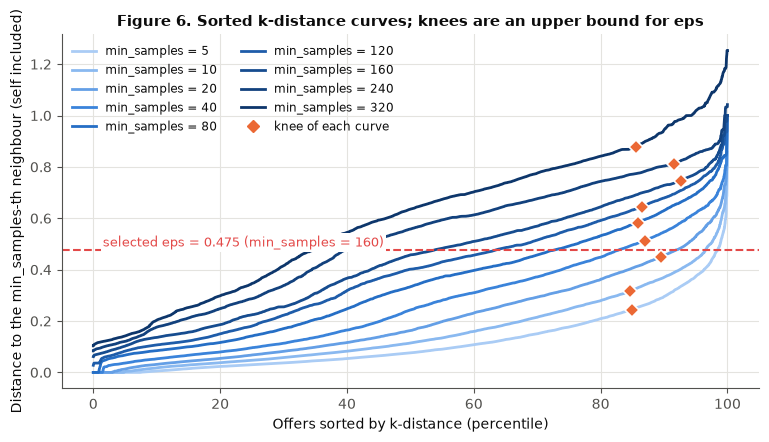

In [17]:
fig, ax = plt.subplots(figsize=(9, 4.6))
shades = [BLUES(v) for v in np.linspace(0.3, 1.0, len(MS_GRID))]
for ms, c in zip(MS_GRID, shades):
    d = kdist(ms); i = knee_index(d)
    ax.plot(np.arange(len(d)) / len(d) * 100, d, color=c, lw=2, label=f"min_samples = {ms}")
    ax.plot(i / len(d) * 100, d[i], marker="D", ms=7, color=PAL["orange"], mec="white", mew=1.2, zorder=5)
ax.plot([], [], marker="D", ls="", color=PAL["orange"], label="knee of each curve")
ax.axhline(EPS_STAR, color=PAL["red"], ls="--", lw=1.5); ax.text(1.5, EPS_STAR + 0.015, f"selected eps = {EPS_STAR} (min_samples = {MS_STAR})", color=PAL["red"], fontsize=9, bbox=dict(fc="white", ec="none", pad=1.5), zorder=6)
ax.set_xlabel("Offers sorted by k-distance (percentile)"); ax.set_ylabel("Distance to the min_samples-th neighbour (self included)")
ax.set_title("Figure 6. Sorted k-distance curves; knees are an upper bound for eps"); ax.legend(loc="upper left", fontsize=8.5, ncol=2)
savefig("fig06_kdistance")

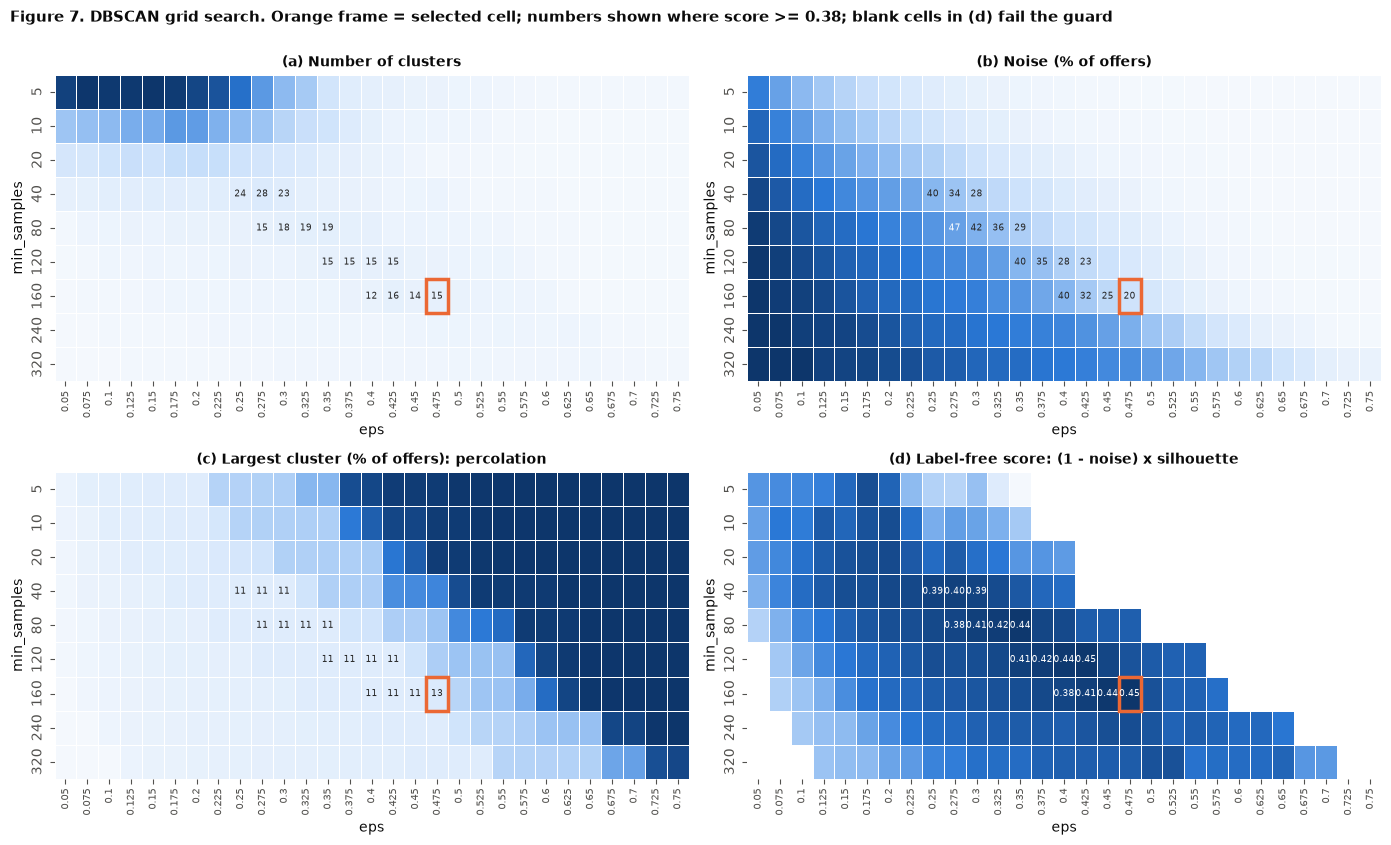

In [18]:
GOOD = 0.38        # numbers are printed only inside the near-optimal region (score >= 0.38)
def grid_heat(ax, col, title, fmt, scale=1.0):
    piv = grid.pivot(index="min_samples", columns="eps", values=col) * scale
    good = grid.pivot(index="min_samples", columns="eps", values="score") >= GOOD
    txt = np.where(good.values, np.vectorize(lambda v: format(v, fmt))(np.nan_to_num(piv.values)), "")
    sns.heatmap(piv, ax=ax, cmap=BLUES, annot=txt, fmt="", annot_kws=dict(fontsize=6.3), cbar=False,
                linewidths=0.5, linecolor="white", xticklabels=[f"{e:g}" for e in piv.columns])
    ax.set_title(title, fontsize=10); ax.set_xlabel("eps"); ax.set_ylabel("min_samples"); ax.tick_params(axis="x", labelsize=7.5, rotation=90); ax.grid(False)
    ri, ci = list(piv.index).index(MS_STAR), list(piv.columns).index(EPS_STAR)
    ax.add_patch(plt.Rectangle((ci, ri), 1, 1, fill=False, ec=PAL["orange"], lw=2.5))

fig, axes = plt.subplots(2, 2, figsize=(14, 8.4))
grid_heat(axes[0, 0], "clusters", "(a) Number of clusters", ".0f")
grid_heat(axes[0, 1], "noise", "(b) Noise (% of offers)", ".0f", scale=100)
grid_heat(axes[1, 0], "largest", "(c) Largest cluster (% of offers): percolation", ".0f", scale=100)
grid_heat(axes[1, 1], "score", "(d) Label-free score: (1 - noise) x silhouette", ".2f")
plt.suptitle("Figure 7. DBSCAN grid search. Orange frame = selected cell; numbers shown where score >= 0.38; blank cells in (d) fail the guard", x=0.01, ha="left", fontweight="bold", y=1.0, fontsize=11)
plt.tight_layout(); savefig("fig07_dbscan_grid")

In [19]:
# Step 3: final DBSCAN, plus HDBSCAN as an eps-free extension
t0 = time.time()
db = DBSCAN(eps=EPS_STAR, min_samples=MS_STAR).fit(Z_dev)
t_db = time.time() - t0
register("DBSCAN", db.labels_, t_db, db)
lab = db.labels_
print(f"DBSCAN(eps={EPS_STAR}, min_samples={MS_STAR}): {n_clusters(lab)} clusters, {pct((lab == -1).mean())} noise, {len(db.core_sample_indices_):,} core points, fit {t_db:.1f}s")
t0 = time.time()
hdb = HDBSCAN(min_cluster_size=20, min_samples=10).fit(Z_dev)
print(f"HDBSCAN (no eps needed; min_cluster_size=20): {hdb.labels_.max() + 1} clusters, {pct((hdb.labels_ == -1).mean())} noise, "
      f"ARI = {adjusted_rand_score(y_dev, hdb.labels_):.3f}, NMI = {normalized_mutual_info_score(y_dev, hdb.labels_):.3f}  ({time.time() - t0:.1f}s)")
display(cluster_table(db.labels_, min_size=60).head(12).style.format({"purity": "{:.0%}"}).hide(axis="index"))

DBSCAN(eps=0.475, min_samples=160): 15 clusters, 19.5% noise, 5,358 core points, fit 0.2s


HDBSCAN (no eps needed; min_cluster_size=20): 92 clusters, 41.9% noise, ARI = 0.066, NMI = 0.434  (2.6s)


cluster,size,majority_category,purity,top_terms
6,1310,Fridge Freezers,63%,"freezer, fridge, fridge freezer, frost, frost free, free"
5,1091,CPUs,99%,"intel, processor, core, ghz, xeon, intel xeon"
3,959,TVs,97%,"tv, hd, led, smart, 4k, led tv"
0,881,Digital Cameras,85%,"camera, digital, black, sony, canon, body"
4,704,Mobile Phones,99%,"sim, smartphone, sim free, free, dual, unlocked"
2,669,Washing Machines,100%,"washing, machine, washing machine, white, machine white, spin"
1,453,Fridge Freezers,36%,"siemens, gorenje, einbau, hl, eek, hlschrank"
10,415,Microwaves,98%,"microwave, oven, microwave oven, steel, in, stainless"
8,282,Dishwashers,100%,"dishwasher, integrated dishwasher, integrated, fully integrated, fully, place"
12,260,Mobile Phones,100%,"phone, mobile, mobile phone, nokia, htc, sim"


**Reading the clusters.** DBSCAN returns 15 dense groups that cover 80.5 % of the offers and flags 19.5 % as noise. Its clusters are very pure where it commits (CPUs 99 %, TVs 97 %, washing machines 100 %, mobile phones 99-100 %, dishwashers 98-100 %, microwaves 98 %) but it does not split the fridge / fridge-freezer / freezer region and creates German-language clusters. Homogeneity ("Homog." in the table) is high (0.68) but completeness ("Compl.") lower (0.62): **DBSCAN is a precise but partial clustering**. **HDBSCAN**, which removes `eps` altogether, produced 92 micro-clusters and 41.9 % noise on this data (ARI 0.07), so it does not rescue the category task either.

<a id="s9"></a>
## **B7. Algorithm 4: Gaussian mixture model (EM)**

**Model.** $p(x)=\sum_{k=1}^{K}\pi_k\,\mathcal N(x\mid\mu_k,\Sigma_k)$. **EM** alternates the E-step (responsibilities $r_{ik}=\pi_k\mathcal N(x_i\mid\mu_k,\Sigma_k)\big/\sum_j\pi_j\mathcal N(x_i\mid\mu_j,\Sigma_j)$) and the M-step ($\pi_k,\mu_k,\Sigma_k$ re-estimated with weights $r_{ik}$); the log-likelihood never decreases. The covariance structure is chosen with the **BIC** $=p\ln n-2\ln\hat L$ (lower is better). K-means is the limit $\Sigma_k=\sigma^2 I$, $\pi_k = 1/K$, $\sigma\to 0$.

**Selection.** At $k = 10$ the BIC is lowest for **full** covariance ($-648{,}954$) against diagonal ($-405{,}529$), spherical ($-262{,}086$) and tied ($-257{,}245$), and falls further as $k$ grows (Figure 8), the same "finer is always better" pattern as the internal indices. The fitted mixture is confident: 97.7 % of offers have a posterior $\ge 0.99$ and only 1.0 % are ambiguous ($<0.9$) (Figure 9).

32 GMM fits in 45s


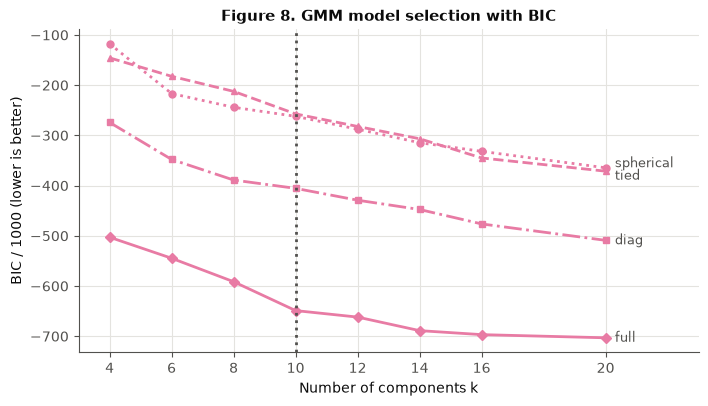

BIC at k = 10: {'spherical': -262086.0, 'diag': -405529.0, 'tied': -257245.0, 'full': -648954.0} -> full


In [20]:
# ==============================================================================
# ALGORITHM 4 - GAUSSIAN MIXTURE MODEL (EM)
# ==============================================================================
cov_types = ["spherical", "diag", "tied", "full"]
ks_g = [4, 6, 8, 10, 12, 14, 16, 20]
rows, t0 = [], time.time()
for cov in cov_types:
    for k in ks_g:
        g = GaussianMixture(k, covariance_type=cov, n_init=1, random_state=SEED, reg_covar=1e-4, max_iter=300).fit(Z_dev)
        rows.append(dict(covariance=cov, k=k, BIC=g.bic(Z_dev), AIC=g.aic(Z_dev), n_params=sum(p.size for p in g._get_parameters())))
gmm_sweep = pd.DataFrame(rows)
print(f"{len(gmm_sweep)} GMM fits in {time.time() - t0:.0f}s")

fig, ax = plt.subplots(figsize=(8, 4.2))
sty = {"spherical": (":", "o"), "diag": ("-.", "s"), "tied": ("--", "^"), "full": ("-", "D")}
for cov in cov_types:
    d = gmm_sweep[gmm_sweep.covariance == cov]
    ax.plot(d.k, d.BIC / 1e3, ls=sty[cov][0], marker=sty[cov][1], ms=5, color=ALGO_COL["GMM"])
    dy = {"spherical": 9, "tied": -9}.get(cov, 0)
    ax.text(d.k.iloc[-1] + 0.3, d.BIC.iloc[-1] / 1e3 + dy, cov, va="center", fontsize=9, color=INK2)
ax.axvline(K, color=INK2, ls=":"); ax.set_xlim(3, 23); ax.set_xticks([4, 6, 8, 10, 12, 14, 16, 20]); ax.set_xlabel("Number of components k"); ax.set_ylabel("BIC / 1000 (lower is better)")
ax.set_title("Figure 8. GMM model selection with BIC")
savefig("fig08_gmm_bic")
bic_at_K = gmm_sweep[gmm_sweep.k == K].set_index("covariance").BIC
print("BIC at k = 10:", bic_at_K.round(0).to_dict(), "->", bic_at_K.idxmin())

GMM (full covariance, k=10): fit 22.2s, converged=True, mixing weights = [0.159 0.131 0.109 0.104 0.103 0.103 0.09  0.073 0.069 0.058]
Soft assignment: 97.7% of offers have posterior >= 0.99; 1.0% are ambiguous (< 0.9)


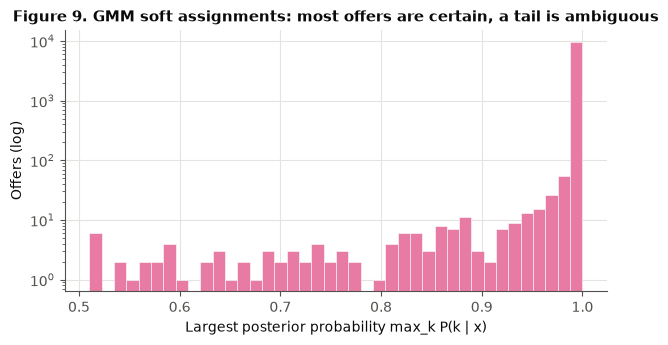

In [21]:
t0 = time.time()
gmm = GaussianMixture(K, covariance_type="full", n_init=5, random_state=SEED, reg_covar=1e-4, max_iter=300).fit(Z_dev)
t_gmm = time.time() - t0
post = gmm.predict_proba(Z_dev)
register("GMM", post.argmax(1), t_gmm, gmm)
maxp = post.max(1)
print(f"GMM (full covariance, k={K}): fit {t_gmm:.1f}s, converged={gmm.converged_}, mixing weights = {np.round(np.sort(gmm.weights_)[::-1], 3)}")
print(f"Soft assignment: {pct((maxp >= 0.99).mean())} of offers have posterior >= 0.99; {pct((maxp < 0.9).mean())} are ambiguous (< 0.9)")
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.hist(maxp, bins=40, color=ALGO_COL["GMM"], edgecolor="white", linewidth=0.4)
ax.set_yscale("log"); ax.set_xlabel("Largest posterior probability max_k P(k | x)"); ax.set_ylabel("Offers (log)")
ax.set_title("Figure 9. GMM soft assignments: most offers are certain, a tail is ambiguous")
savefig("fig09_gmm_posterior")

<a id="s10"></a>
## **B8. Side-by-side comparison on the dev set**

In [22]:
# ==============================================================================
# SIDE-BY-SIDE COMPARISON ON THE DEV SET
# ==============================================================================
def evaluate_all():
    rows = []
    for name in ALGO:
        m = MODELS[name]; lab = m["labels"]
        rows.append({"Model": name, "Clusters": n_clusters(lab), "Noise": (lab == -1).mean(), "Fit time (s)": m["secs"],
                     **internal_scores(Z_dev, lab), **external_scores(y_dev, lab)})
    return pd.DataFrame(rows).set_index("Model")

comparison = evaluate_all()
comparison.to_csv(RES / "model_comparison_dev.csv")
SHORT = {"Davies_Bouldin": "Davies-Bouldin", "Calinski_Harabasz": "Calinski-Harabasz", "Homogeneity": "Homog.", "Completeness": "Compl.", "V_measure": "V-meas."}
display(comparison.rename(columns=SHORT).style.format({"Noise": "{:.1%}", "Fit time (s)": "{:.1f}", "Silhouette": "{:.3f}", "Davies-Bouldin": "{:.2f}", "Calinski-Harabasz": "{:.0f}",
                                 "ARI": "{:.3f}", "NMI": "{:.3f}", "Homog.": "{:.3f}", "Compl.": "{:.3f}", "V-meas.": "{:.3f}", "Purity": "{:.3f}"}))

,Clusters,Noise,Fit time (s),Silhouette,Davies-Bouldin,Calinski-Harabasz,ARI,NMI,Homog.,Compl.,V-meas.,Purity
Model,,,,,,,,,,,,
K-means,10,0.0%,0.3,0.372,1.57,1480,0.622,0.699,0.700,0.697,0.699,0.769
Agglomerative (Ward),10,0.0%,5.5,0.357,1.68,1346,0.550,0.681,0.669,0.693,0.681,0.731
DBSCAN,15,19.5%,0.2,0.558,0.84,2066,0.469,0.644,0.677,0.615,0.644,0.714
GMM,10,0.0%,22.2,0.289,2.28,1057,0.538,0.654,0.653,0.655,0.654,0.688


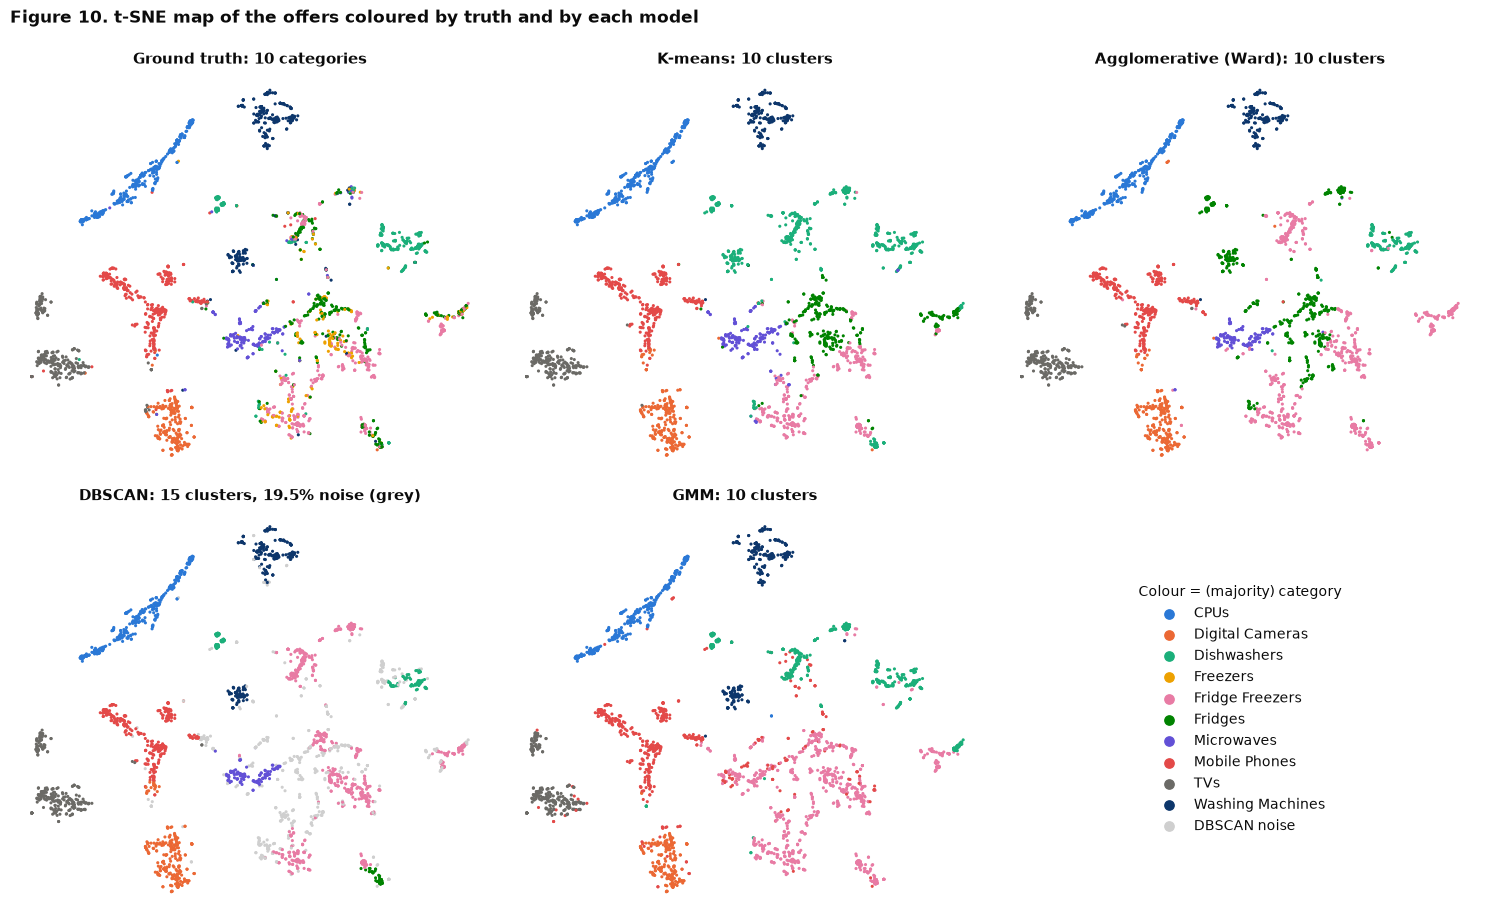

In [23]:
# 2-D map of the embedding (t-SNE on 3,000 random dev offers); each cluster is coloured by its MAJORITY category
rs = np.random.default_rng(SEED)
vis = rs.choice(len(Z_dev), 3000, replace=False)
emb2 = TSNE(2, perplexity=40, init="pca", random_state=SEED).fit_transform(Z_dev[vis])

def majority_colour(lab):
    out = {}
    for c in set(lab):
        out[c] = "#cfcfcf" if c == -1 else CAT10[np.bincount(y_dev[lab == c], minlength=K).argmax()]
    return out

fig, axes = plt.subplots(2, 3, figsize=(15, 9.2))
axs = axes.ravel()
axs[0].scatter(*emb2.T, c=[CAT10[i] for i in y_dev[vis]], s=5, lw=0); axs[0].set_title("Ground truth: 10 categories")
for ax, name in zip(axs[1:5], ALGO):
    lab = MODELS[name]["labels"]; mc = majority_colour(lab)
    ax.scatter(*emb2.T, c=[mc[c] for c in lab[vis]], s=5, lw=0)
    ttl = f"{name}: {n_clusters(lab)} clusters" + (f", {pct((lab == -1).mean())} noise (grey)" if (lab == -1).any() else "")
    ax.set_title(ttl, color=INK)
for ax in axs[:5]: ax.set_xticks([]); ax.set_yticks([]); ax.grid(False); ax.spines[["left", "bottom"]].set_visible(False)
axs[5].axis("off")
for i, c in enumerate(CLASSES): axs[5].scatter([], [], c=CAT10[i], s=45, label=c)
axs[5].scatter([], [], c="#cfcfcf", s=45, label="DBSCAN noise"); axs[5].legend(loc="center", fontsize=10, title="Colour = (majority) category", title_fontsize=10)
plt.suptitle("Figure 10. t-SNE map of the offers coloured by truth and by each model", x=0.01, ha="left", fontweight="bold", y=0.995)
plt.tight_layout(); savefig("fig10_tsne")

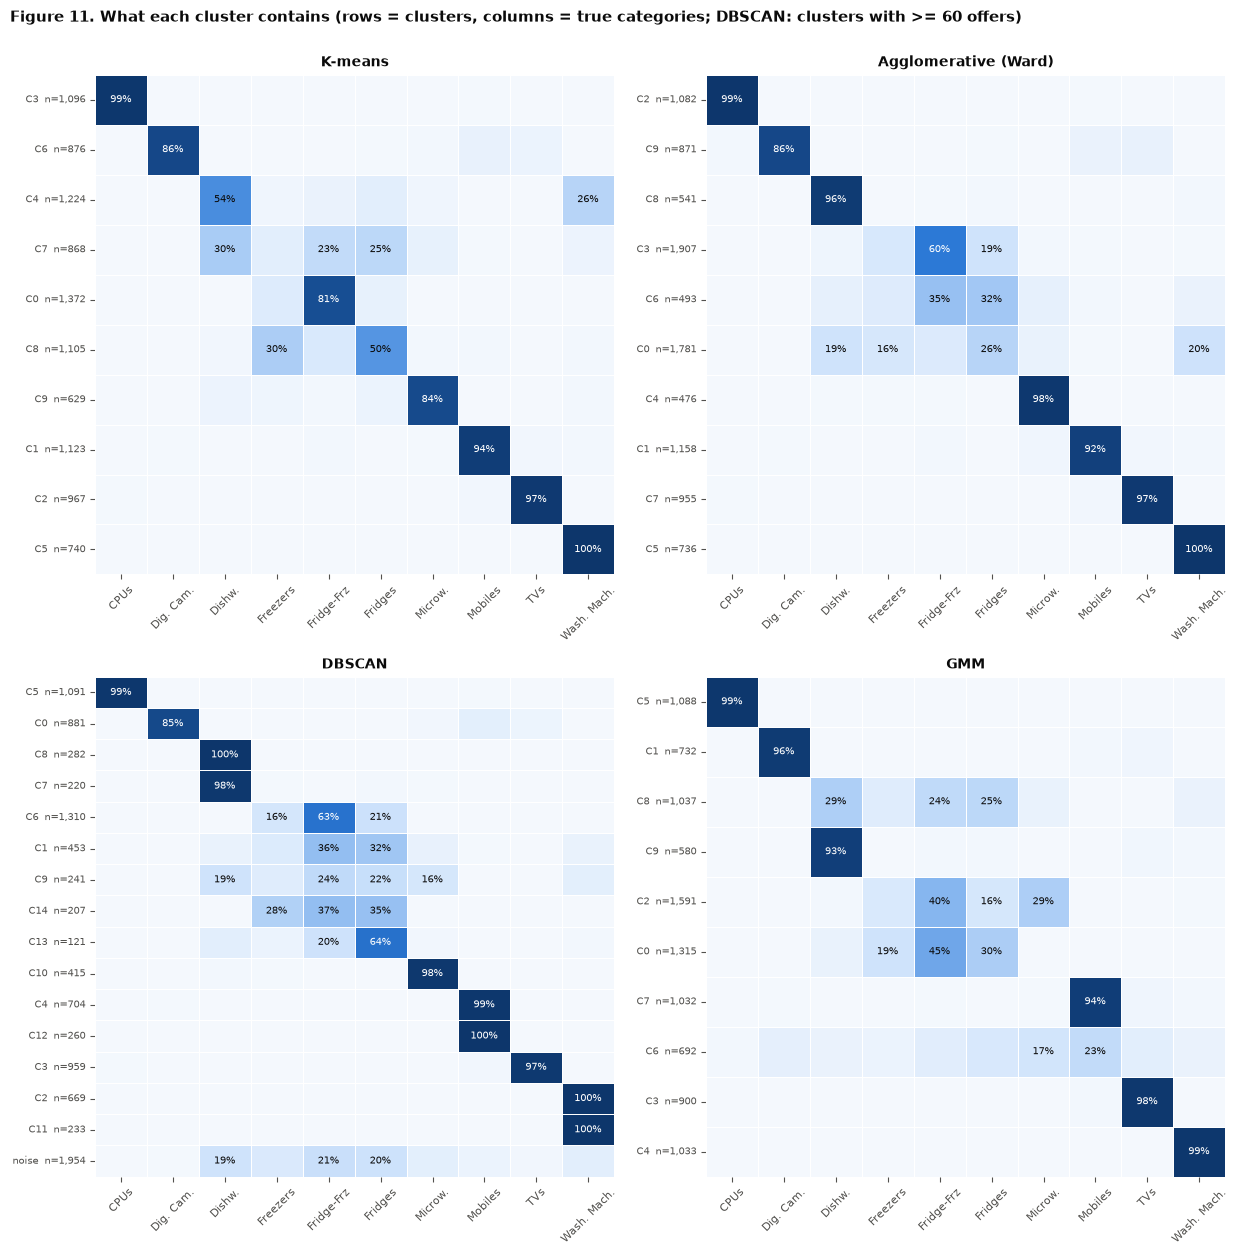

In [24]:
# Cluster-versus-category composition (rows = clusters, columns = true categories, cell = share of the cluster)
short = [c.replace("Washing Machines", "Wash. Mach.").replace("Digital Cameras", "Dig. Cam.").replace("Fridge Freezers", "Fridge-Frz").replace("Mobile Phones", "Mobiles").replace("Dishwashers", "Dishw.").replace("Microwaves", "Microw.") for c in CLASSES]
def composition(ax, lab, title, min_size=1):
    ct = pd.crosstab(lab, y_dev).reindex(columns=range(K), fill_value=0)
    ct = ct[ct.sum(axis=1) >= min_size]
    prop = ct.div(ct.sum(axis=1), axis=0)
    order = sorted(prop.index, key=lambda c: (c == -1, prop.loc[c].values.argmax(), -ct.loc[c].sum()))
    prop, ct = prop.loc[order], ct.loc[order]
    ylab = [("noise" if c == -1 else f"C{c}") + f"  n={ct.loc[c].sum():,}" for c in prop.index]
    txt = np.where(prop.values >= 0.15, (prop.values * 100).round().astype(int).astype(str) + "%", "")
    sns.heatmap(prop, ax=ax, cmap=BLUES, vmin=0, vmax=1, cbar=False, xticklabels=short, yticklabels=ylab, linewidths=0.4, linecolor="white",
                annot=txt, fmt="", annot_kws=dict(fontsize=7))
    for t in ax.texts:
        t.set_color("white" if t.get_text() and int(t.get_text().strip("%")) > 55 else INK)
    ax.set_title(title, fontsize=10); ax.set_xlabel(""); ax.set_ylabel(""); ax.tick_params(axis="x", labelsize=8, rotation=45); ax.tick_params(axis="y", labelsize=7.5); ax.grid(False)

fig, axes = plt.subplots(2, 2, figsize=(12.5, 12.5))
for ax, name in zip(axes.ravel(), ALGO):
    composition(ax, MODELS[name]["labels"], name, min_size=60 if name == "DBSCAN" else 1)
plt.suptitle("Figure 11. What each cluster contains (rows = clusters, columns = true categories; DBSCAN: clusters with >= 60 offers)", x=0.01, ha="left", fontweight="bold", y=1.0, fontsize=11)
plt.tight_layout(); savefig("fig11_composition")

**Reading the table.**

- **External agreement ranks K-means > Ward > GMM > DBSCAN** (ARI 0.62 / 0.55 / 0.54 / 0.47; NMI 0.70 / 0.68 / 0.65 / 0.64).
- **DBSCAN's silhouette (0.56) and Davies-Bouldin (0.84) look best only because they are computed on the 80.5 % of offers that were not discarded**; they are not comparable with the other rows.
- All four models recover the visually separate "islands" (CPUs, TVs, cameras, phones, washing machines; Figure 10). They differ in the crowded middle of the map where fridges, freezers, dishwashers and microwaves overlap (Figure 11). GMM's two largest clusters (1,591 and 1,315 offers) each blend fridge-freezers with fridges, freezers or microwaves, whereas K-means and Ward keep these better apart.
- Every model creates at least one **German-language cluster**: language is a stronger signal in the embedding than category for those offers (see Section B13).

<a id="q1"></a>
---
## **B9. Question 1: why can K-means fail when clusters differ in density, size or shape?**

> **Short answer.** K-means minimises $J=\sum_k\sum_{x\in C_k}\lVert x-\mu_k\rVert^2$. This is the hard-assignment limit of a Gaussian mixture with **identical isotropic covariances $\sigma^2 I$ and equal weights**. It can therefore only represent equal-spread, roughly equal-size, *convex, spherical* clusters. When the data violate these assumptions, the partition that minimises $J$ is **not** the partition a human would call correct.

**Mathematics: four failure modes.**

1. **Density / spread: the boundary ignores variance.** A point goes to the nearer centroid, so the boundary is the perpendicular bisector halfway between centroids, **whatever the spreads**. For two clusters $N(0,\sigma_1^2)$ and $N(d,\sigma_2^2)$ with $\sigma_1\gg\sigma_2$, the fraction of the broad cluster lost to the tight one is (first order) $\;1-\Phi\!\big(\tfrac{d}{2\sigma_1}\big)$, e.g. 20 % when $\sigma_1 = 0.6\,d$. A density-aware (Bayes) boundary would sit much closer to the tight cluster.
2. **Size: splitting a big cluster is cheaper than isolating a small one.** Separating cluster $B$ from $A$ lowers $J$ by $\dfrac{n_An_B}{n_A+n_B}\lVert\mu_A-\mu_B\rVert^2\approx n_B\,d^2$ (the Ward identity of Section B5). Cutting a Gaussian cluster of $n_1$ points through its centre lowers $J$ by $\tfrac{2}{\pi}n_1\sigma_1^2$. K-means prefers to **split the large cluster and swallow the small one** when
$$\frac{n_1}{n_2}>\frac{\pi}{2}\,\frac{d^2}{\sigma_1^2}\quad(=25\ \text{for clusters } d=4\sigma_1\text{ apart, i.e. clearly separated}).$$
3. **Shape: elongation.** Two thin parallel stripes (long-axis std $\sigma_a$, gap $d$) with $n$ points in total: the correct split lowers $J$ by $nd^2/4$, a wrong cut across the long axis by $\tfrac{2}{\pi}n\sigma_a^2$. The wrong cut wins when $\;\sigma_a/d>\sqrt{\pi/8}\approx0.63$. Euclidean distance has no notion of direction, so correlated/elongated clusters are cut across.
4. **Non-convexity.** Voronoi cells are convex, so interleaved shapes (two moons, concentric rings, a river, a fault line) cannot be separated by *any* choice of centroids.

**Evidence.** Figure 12 applies the same data to K-means and to an algorithm whose assumptions fit; Figure 13 checks the formulas by simulation:

| Failure mode | Theory | Simulation (K-means) | GMM / DBSCAN |
|---|---|---|---|
| Size imbalance (4 $\sigma$ apart) | breaks near $n_1/n_2 = 25$ | ARI $<0.5$ from ratio $\approx 13$, $\approx 0.03$ beyond 32 | GMM holds ARI $\ge 0.5$ up to ratio $\approx 150$ |
| Broad cluster, $\sigma_1=0.5\,d$ | loses 16 % (first order) | loses 24 % | GMM loses 1 % |
| Elongation | breaks at $\sigma_a/d=0.63$ | ARI falls through 0.5 at 0.66 | GMM stays at ARI $\approx 1$ |
| Moons / rings | impossible for convex cells | ARI 0.24 / $-0.00$ | DBSCAN ARI 1.00 / 1.00 |

The theory is a first-order guide (centroids drift towards the points they steal, so K-means does slightly worse than predicted in the density case), but both tipping points are located correctly.

**In our data.** The K-means German-language cluster (Section B4) and the dishwasher/washing-machine and fridge/freezer clusters are the same phenomenon: clusters whose spread and orientation in LSA space differ from a sphere around a mean.

**Real-world examples.**
- **Land-cover mapping (remote sensing):** water is a tight spectral cluster, but bare soil and urban surfaces form a long, elongated "soil line" in red-NIR space. K-means or ISODATA cuts the soil line into arbitrary pieces; a Gaussian maximum-likelihood classifier with class covariances follows it.
- **Crime or accident hotspots (GIS):** incidents lie along roads and fault lines (non-convex strips), plus scattered isolated events. K-means partitions a road into Voronoi chunks and forces outliers into clusters; DBSCAN follows the strip and labels the isolated events as noise.
- **Customer segmentation:** a few very-high-spend customers against a huge mass of low spend (different size *and* spread): K-means splits the mass and merges the VIPs; a log transform or GMM separates them.

**Remedies.** GMM with full covariance (elliptical, different sizes; use several random starts and pick by likelihood, as K-means initialisation can trap it, see Figure 12 notes), DBSCAN/HDBSCAN (arbitrary shapes, noise), spectral clustering, feature transforms (log, whitening), or over-cluster and then merge.

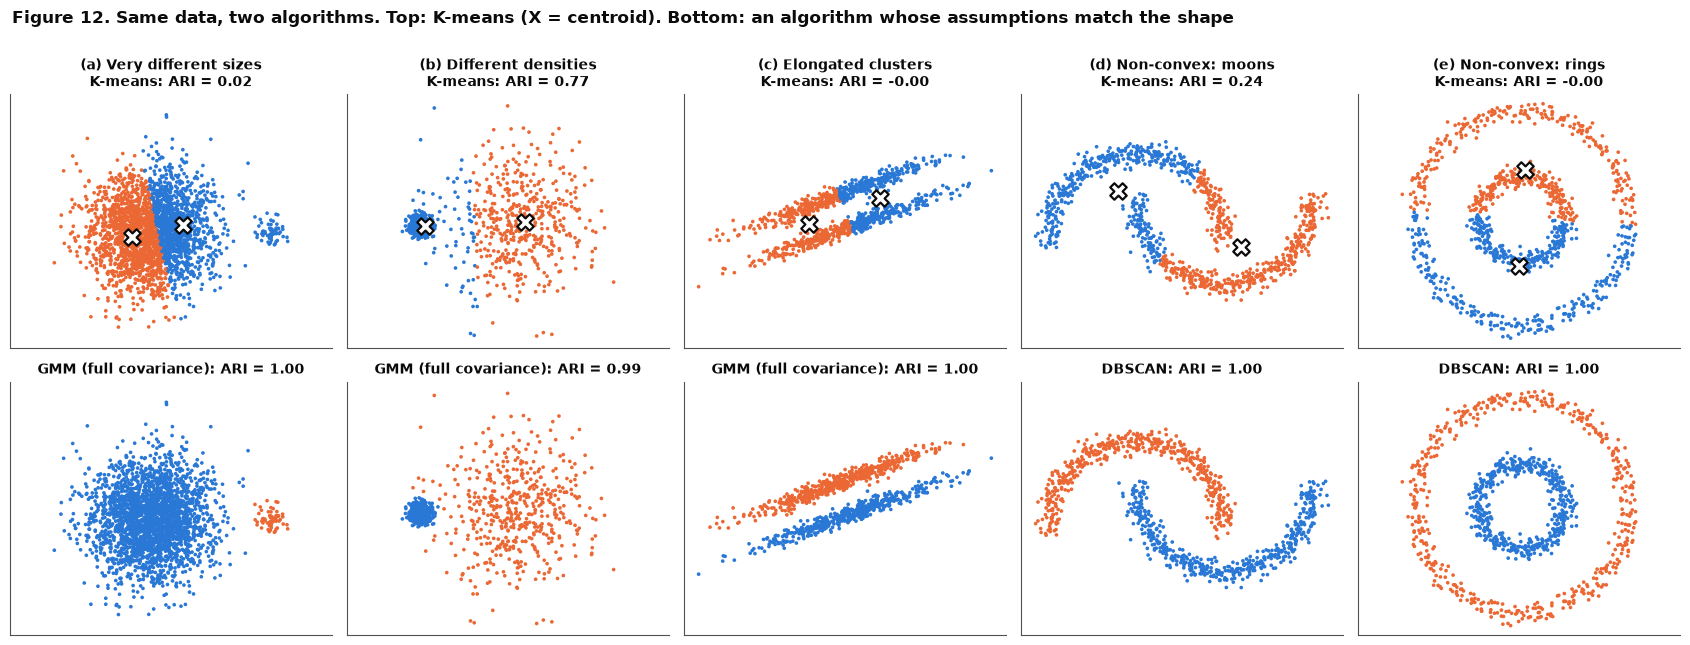

method,DBSCAN,GMM (full covariance),K-means
scenario,,,
(a) Very different sizes,NaN,1.00,0.02
(b) Different densities,NaN,0.99,0.77
(c) Elongated clusters,NaN,1.00,-0.00
(d) Non-convex: moons,1.0,NaN,0.24
(e) Non-convex: rings,1.0,NaN,-0.00


In [25]:
# ==============================================================================
# QUESTION 1 - WHY CAN K-MEANS FAIL?  Controlled experiments on synthetic data
# ==============================================================================
def rot(X, deg):
    a = np.deg2rad(deg); R = np.array([[np.cos(a), -np.sin(a)], [np.sin(a), np.cos(a)]])
    return X @ R.T

def scenario_sizes(seed):      # 2,500 vs 60 points, centres 4 sigma apart  (clearly separated, but 42:1 imbalance)
    return make_blobs(n_samples=[2500, 60], centers=[[0, 0], [4, 0]], cluster_std=[1.0, 0.25], random_state=seed)
def scenario_density(seed):    # equal sizes, very different spread
    return make_blobs(n_samples=[500, 500], centers=[[0, 0], [5, 0]], cluster_std=[0.3, 2.0], random_state=seed)
def stripes(n, sig_long, d, sig_short, seed, theta=0.0):
    """Two thin parallel clusters: long axis std = sig_long, short axis std = sig_short, centres d apart across the short axis."""
    noise, yy = make_blobs(n_samples=[n, n], centers=[[0, 0], [0, 0]], cluster_std=1.0, random_state=seed)
    X = noise * np.array([sig_long, sig_short]) + np.where(yy[:, None] == 1, [0.0, d], [0.0, 0.0])
    return rot(X, theta), yy

def scenario_aniso(seed):      # long-axis spread 1.5x the gap between the stripes
    return stripes(500, 3.0, 2.0, 0.25, seed, theta=20)
def scenario_moons(seed):      return make_moons(n_samples=1000, noise=0.07, random_state=seed)
def scenario_circles(seed):    return make_circles(n_samples=1000, factor=0.4, noise=0.05, random_state=seed)

SCEN = [("(a) Very different sizes", scenario_sizes, "gmm"), ("(b) Different densities", scenario_density, "gmm"),
        ("(c) Elongated clusters", scenario_aniso, "gmm"), ("(d) Non-convex: moons", scenario_moons, "dbscan"),
        ("(e) Non-convex: rings", scenario_circles, "dbscan")]
DB_PARAMS = {"(d) Non-convex: moons": dict(eps=0.2, min_samples=5), "(e) Non-convex: rings": dict(eps=0.15, min_samples=5)}
PCOL = [PAL["blue"], PAL["orange"], PAL["aqua"], PAL["magenta"]]

fig, axes = plt.subplots(2, 5, figsize=(17, 6.4))
rows = []
for j, (name, fn, fixer) in enumerate(SCEN):
    X, yy = fn(SEED)
    km_ = KMeans(2, n_init=10, random_state=SEED).fit(X)
    if fixer == "gmm":
        fx = GaussianMixture(2, covariance_type="full", n_init=10, init_params="random_from_data", random_state=SEED).fit(X).predict(X); fx_name = "GMM (full covariance)"
    else:
        fx = DBSCAN(**DB_PARAMS[name]).fit_predict(X); fx_name = "DBSCAN"
    for i, (lab, mname) in enumerate([(km_.labels_, "K-means"), (fx, fx_name)]):
        ax = axes[i, j]
        cols = [PCOL[c] if c >= 0 else "#bbbbbb" for c in lab]
        ax.scatter(X[:, 0], X[:, 1], c=cols, s=7, lw=0)
        if i == 0: ax.scatter(*km_.cluster_centers_.T, marker="X", s=140, c="white", edgecolors=INK, linewidths=1.6, zorder=5)
        ari = adjusted_rand_score(yy, lab)
        ax.set_title(f"{name}\n{mname}: ARI = {ari:.2f}" if i == 0 else f"{mname}: ARI = {ari:.2f}", fontsize=10, color=INK)
        ax.set_aspect("equal", adjustable="datalim"); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        rows.append(dict(scenario=name, method=mname, ARI=ari))
plt.suptitle("Figure 12. Same data, two algorithms. Top: K-means (X = centroid). Bottom: an algorithm whose assumptions match the shape", x=0.01, ha="left", fontweight="bold", y=1.0)
plt.tight_layout(); savefig("fig12_kmeans_failure_gallery")
synthetic_scores = pd.DataFrame(rows); display(synthetic_scores.pivot(index="scenario", columns="method", values="ARI").round(2))

*Figure 12 note: GMM was fitted with 10 random starts (`init_params="random_from_data"`) and the best likelihood kept; initialising it from K-means would inherit K-means' wrong partition, which is itself a practical lesson.*

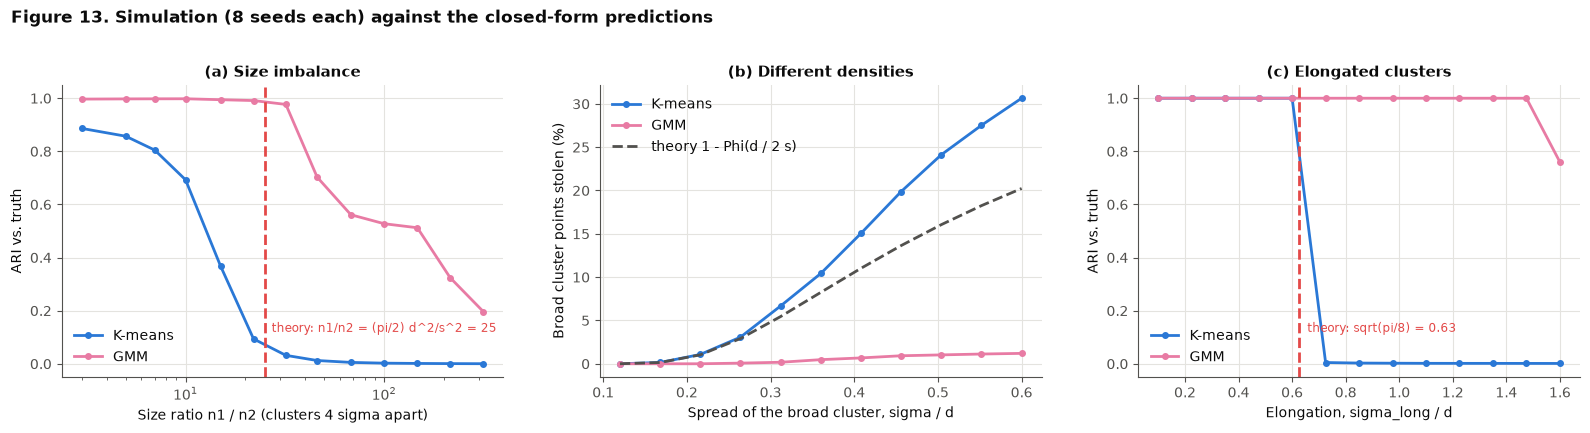

In [26]:
# Quantitative check of three closed-form predictions (see the derivations in the text).
def ari_mean(fn, seeds, fit):
    out = []
    for s in seeds:
        X, yy = fn(s); out.append(adjusted_rand_score(yy, fit(X, s)))
    return np.mean(out), np.std(out)

fit_km = lambda X, s: KMeans(2, n_init=10, random_state=s).fit_predict(X)
fit_gm = lambda X, s: GaussianMixture(2, covariance_type="full", n_init=10, init_params="random_from_data", random_state=s).fit_predict(X)
seeds = range(8)

# (i) SIZE: separation gain  n1*n2/(n1+n2)*d^2   vs   gain from splitting the big cluster  (2/pi)*n1*sigma1^2
d, sig1, n2 = 4.0, 1.0, 40
ratios = np.unique(np.round(np.logspace(0.5, 2.5, 13)).astype(int))
res_size = {"K-means": [], "GMM": []}
for r in ratios:
    f = lambda s, r=r: make_blobs(n_samples=[int(n2 * r), n2], centers=[[0, 0], [d, 0]], cluster_std=[sig1, 0.25], random_state=s)
    res_size["K-means"].append(ari_mean(f, seeds, fit_km)); res_size["GMM"].append(ari_mean(f, seeds, fit_gm))
r_star = (np.pi / 2) * d ** 2 / sig1 ** 2

# (ii) SPREAD: K-means boundary sits halfway between centroids, so a broad cluster loses P = 1 - Phi(d / 2 sigma1)
d2_, sig2 = 5.0, 0.3
sig_grid = np.linspace(0.6, 3.0, 11)
res_spread = {"K-means": [], "GMM": []}
for sg in sig_grid:
    for key, fit in [("K-means", fit_km), ("GMM", fit_gm)]:
        vals = []
        for s in seeds:
            X, yy = make_blobs(n_samples=[500, 500], centers=[[0, 0], [d2_, 0]], cluster_std=[sig2, sg], random_state=s)
            lab = fit(X, s)
            tight = np.bincount(lab[yy == 0]).argmax()                # label that owns the tight cluster
            vals.append(np.mean(lab[yy == 1] == tight))               # share of the BROAD cluster stolen by the tight one
        res_spread[key].append(np.mean(vals))
theory_spread = 1 - norm.cdf(d2_ / (2 * sig_grid))

# (iii) SHAPE: correct split gains n*d^2/4,  a wrong cut along the long axis gains (2/pi)*n*sigma_a^2  ->  critical sigma_a/d = sqrt(pi/8)
d3 = 2.0
ratio_grid = np.linspace(0.1, 1.6, 13)
res_shape = {"K-means": [], "GMM": []}
for q in ratio_grid:
    def f(s, q=q): return stripes(500, q * d3, d3, 0.15, s)
    res_shape["K-means"].append(ari_mean(f, seeds, fit_km)); res_shape["GMM"].append(ari_mean(f, seeds, fit_gm))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
ax = axes[0]
for key in ["K-means", "GMM"]:
    m = np.array([v[0] for v in res_size[key]]); ax.plot(ratios, m, marker="o", ms=4, color=ALGO_COL[key], label=key)
ax.axvline(r_star, color=PAL["red"], ls="--"); ax.text(r_star * 1.08, 0.12, f"theory: n1/n2 = (pi/2) d^2/s^2 = {r_star:.0f}", color=PAL["red"], fontsize=8.5)
ax.set_xscale("log"); ax.set_xlabel("Size ratio n1 / n2 (clusters 4 sigma apart)"); ax.set_ylabel("ARI vs. truth"); ax.set_ylim(-0.05, 1.05); ax.legend(loc="lower left"); ax.set_title("(a) Size imbalance")
ax = axes[1]
for key in ["K-means", "GMM"]: ax.plot(sig_grid / d2_, np.array(res_spread[key]) * 100, marker="o", ms=4, color=ALGO_COL[key], label=key)
ax.plot(sig_grid / d2_, theory_spread * 100, color=INK2, ls="--", label="theory 1 - Phi(d / 2 s)")
ax.set_xlabel("Spread of the broad cluster, sigma / d"); ax.set_ylabel("Broad cluster points stolen (%)"); ax.legend(); ax.set_title("(b) Different densities")
ax = axes[2]
for key in ["K-means", "GMM"]:
    m = np.array([v[0] for v in res_shape[key]]); ax.plot(ratio_grid, m, marker="o", ms=4, color=ALGO_COL[key], label=key)
ax.axvline(np.sqrt(np.pi / 8), color=PAL["red"], ls="--"); ax.text(np.sqrt(np.pi / 8) + 0.03, 0.12, "theory: sqrt(pi/8) = 0.63", color=PAL["red"], fontsize=8.5)
ax.set_xlabel("Elongation, sigma_long / d"); ax.set_ylabel("ARI vs. truth"); ax.set_ylim(-0.05, 1.05); ax.legend(loc="lower left"); ax.set_title("(c) Elongated clusters")
plt.suptitle("Figure 13. Simulation (8 seeds each) against the closed-form predictions", x=0.01, ha="left", fontweight="bold", y=1.02)
plt.tight_layout(); savefig("fig13_kmeans_theory")

In [27]:
# Where does each simulated curve cross its tipping value?  (compared with the closed-form prediction)
def crossing(xs, ys, thr, below=True):
    xs, ys = np.asarray(xs, float), np.asarray(ys, float)
    for i in range(1, len(xs)):
        if (ys[i - 1] >= thr > ys[i]) if below else (ys[i - 1] <= thr < ys[i]):
            return xs[i - 1] + (thr - ys[i - 1]) * (xs[i] - xs[i - 1]) / (ys[i] - ys[i - 1])
    return np.nan

km_size = [v[0] for v in res_size["K-means"]]; gm_size = [v[0] for v in res_size["GMM"]]
km_shape = [v[0] for v in res_shape["K-means"]]; gm_shape = [v[0] for v in res_shape["GMM"]]
tipping = pd.DataFrame({
    "Failure mode": ["(a) size imbalance: n1/n2", "(c) elongation: sigma_long/d"],
    "Theory (closed form)": [r_star, np.sqrt(np.pi / 8)],
    "K-means: ARI falls through 0.5 at": [crossing(ratios, km_size, 0.5), crossing(ratio_grid, km_shape, 0.5)],
    "GMM: ARI falls through 0.5 at": [crossing(ratios, gm_size, 0.5), crossing(ratio_grid, gm_shape, 0.5)]}).set_index("Failure mode")
display(tipping.round(2))
i_b = int(np.argmin(np.abs(sig_grid / d2_ - 0.5)))
print(f"(b) At sigma/d = {sig_grid[i_b] / d2_:.2f}: K-means loses {100 * res_spread['K-means'][i_b]:.1f}% of the broad cluster, GMM {100 * res_spread['GMM'][i_b]:.1f}%, first-order theory {100 * theory_spread[i_b]:.1f}%")
print(f"    At sigma/d = {sig_grid[-1] / d2_:.2f}: K-means {100 * res_spread['K-means'][-1]:.1f}%, GMM {100 * res_spread['GMM'][-1]:.1f}%, theory {100 * theory_spread[-1]:.1f}%")

,Theory (closed form),K-means: ARI falls through 0.5 at,GMM: ARI falls through 0.5 at
Failure mode,,,
(a) size imbalance: n1/n2,25.13,12.97,151.42
(c) elongation: sigma_long/d,0.63,0.66,NaN


(b) At sigma/d = 0.50: K-means loses 24.1% of the broad cluster, GMM 1.0%, first-order theory 16.1%
    At sigma/d = 0.60: K-means 30.6%, GMM 1.2%, theory 20.2%


<a id="q2"></a>
---
## **B10. Question 2: how does standardisation change the clusters? (experiment)**

**Design.** Real systems seldom cluster text alone; they append structured descriptors. To each offer we add four numeric descriptors of its title (`title_chars`, `title_words`, `digit_chars`, `avg_word_len`, whose scales differ by orders of magnitude) to the 20 LSA coordinates. Four conditions, each run through all four algorithms: **A** LSA only (baseline), **B** LSA + descriptors, raw; **C** LSA + descriptors, z-scored; **D** LSA only, z-scored. DBSCAN's `eps` is re-read from the *same point of the k-distance curve* in each space (it equals 0.475, 3.21, 3.01 and 2.34), because `eps` carries the units of the features.

**Mathematics.** Euclidean distance is $d^2(x,y)=\sum_j(x_j-y_j)^2$. Feature $j$ therefore contributes roughly $\mathrm{Var}(x_j)\big/\sum_l\mathrm{Var}(x_l)$ of the geometry. After $z_j=(x_j-\bar x_j)/s_j$ the distance becomes $\sum_j (x_j-y_j)^2/s_j^2$ (a diagonal Mahalanobis distance) and every feature carries the same share, $1/24$ here.

In [28]:
# ==============================================================================
# QUESTION 2 - DOES STANDARDISATION CHANGE THE CLUSTERS?  (experiment)
# ==============================================================================
# Real systems rarely cluster text alone: they append structured descriptors.  We add four numeric descriptors of each title
# (very different scales) to the 20 LSA coordinates and ask how the four algorithms react to scaling.
t_dev = df["Product Title"].astype(str).iloc[idx_dev].reset_index(drop=True)
n_words = t_dev.str.split().str.len()
meta = pd.DataFrame({"title_chars": t_dev.str.len(), "title_words": n_words,
                     "digit_chars": t_dev.str.count(r"\d"), "avg_word_len": t_dev.str.len() / n_words})
M = meta.to_numpy(float)
H_raw = np.hstack([Z_dev, M])
CONDS = {"A  LSA only\n(raw)": Z_dev, "B  LSA + meta\n(raw)": H_raw,
         "C  LSA + meta\n(z-scored)": StandardScaler().fit_transform(H_raw), "D  LSA only\n(z-scored)": StandardScaler().fit_transform(Z_dev)}

var_tbl = pd.DataFrame({"feature": ["LSA dimension (mean of 20)"] + list(meta.columns),
                        "variance (raw)": [Z_dev.var(axis=0).mean()] + list(meta.var().values)})
var_tbl["share of total variance in B"] = np.r_[Z_dev.var(axis=0).sum(), meta.var().values] / H_raw.var(axis=0).sum()
display(var_tbl.style.format({"variance (raw)": "{:.4f}", "share of total variance in B": "{:.4%}"}).hide(axis="index"))
print(f"Std. dev. of the 20 LSA coordinates: {Z_dev.std(axis=0).min():.2f} to {Z_dev.std(axis=0).max():.2f}  |  title_chars std = {meta.title_chars.std():.1f}")

feature,variance (raw),share of total variance in B
LSA dimension (mean of 20),0.0444,0.1639%
title_chars,502.8205,92.7028%
title_words,17.3128,3.1919%
digit_chars,19.2161,3.5428%
avg_word_len,2.2164,0.4086%


Std. dev. of the 20 LSA coordinates: 0.16 to 0.27  |  title_chars std = 22.4


In [29]:
pct_ref = float((kdist(MS_STAR) <= EPS_STAR).mean())             # share of offers whose k-distance <= selected eps in the reference space

def eta_squared(lab, x):
    """Share of the variance of x explained by cluster membership (1 = clusters are just bins of x)."""
    g = pd.Series(x).groupby(lab).transform("mean")
    return float(((g - x.mean()) ** 2).sum() / ((x - x.mean()) ** 2).sum())

def run_models(Xc):
    out = {}
    out["K-means"] = KMeans(K, init="k-means++", n_init=20, random_state=SEED).fit_predict(Xc)
    out["Agglomerative (Ward)"] = AgglomerativeClustering(K, linkage="ward").fit_predict(Xc)
    out["GMM"] = GaussianMixture(K, covariance_type="full", n_init=5, random_state=SEED, reg_covar=1e-4, max_iter=300).fit_predict(Xc)
    kd = NearestNeighbors(n_neighbors=MS_STAR).fit(Xc).kneighbors(Xc)[0][:, -1]
    eps_c = float(np.quantile(kd, pct_ref))                       # eps re-read from the SAME point of the k-distance curve
    out["DBSCAN"] = DBSCAN(eps=eps_c, min_samples=MS_STAR).fit_predict(Xc); out["_eps"] = eps_c
    return out

rows, LAB = [], {}
for cname, Xc in CONDS.items():
    res = run_models(Xc); LAB[cname] = res
    for name in ALGO:
        lab = res[name]; sc = external_scores(y_dev, lab); nz = lab != -1
        rows.append(dict(condition=cname.replace("\n", " "), cond_short=cname.split()[0], model=name, clusters=n_clusters(lab), noise=(lab == -1).mean(),
                         largest=np.bincount(lab[nz]).max() / len(lab) if nz.any() else np.nan,
                         ARI=sc["ARI"], NMI=sc["NMI"], length_eta2=eta_squared(lab, meta.title_chars.to_numpy())))
std_res = pd.DataFrame(rows)
std_res.drop(columns="cond_short").to_csv(RES / "standardisation_experiment.csv", index=False)
print("DBSCAN eps used per condition:", {k.split()[0]: round(v["_eps"], 3) for k, v in LAB.items()})
display(std_res.drop(columns="cond_short").pivot_table(index="condition", columns="model", values=["ARI", "NMI", "length_eta2"])[
    [(m, a) for m in ["ARI", "NMI", "length_eta2"] for a in ALGO]].round(3))

DBSCAN eps used per condition: {'A': 0.475, 'B': 3.214, 'C': 3.008, 'D': 2.335}


ARI                                        NMI  \
model                    K-means Agglomerative (Ward) DBSCAN    GMM K-means   
condition                                                                     
A  LSA only (raw)          0.622                0.550  0.469  0.538   0.699   
B  LSA + meta (raw)        0.014                0.014  0.005  0.308   0.036   
C  LSA + meta (z-scored)   0.537                0.419  0.360  0.490   0.665   
D  LSA only (z-scored)     0.531                0.480  0.373  0.492   0.650   

                                                            length_eta2  \
model                    Agglomerative (Ward) DBSCAN    GMM     K-means   
condition                                                                 
A  LSA only (raw)                       0.681  0.644  0.654       0.077   
B  LSA + meta (raw)                     0.035  0.021  0.441       0.975   
C  LSA + meta (z-scored)                0.594  0.562  0.622       0.118   
D  LSA only (z-scored)                  0.637  0.582  0.622       0.043   

                                                             
model                    Agglomerative (Ward) DBSCAN    GMM  
condition                                                    
A  LSA only (raw)                       0.076  0.096  0.095  
B  LSA + meta (raw)                     0.965  0.288  0.162  
C  LSA + meta (z-scored)                0.217  0.079  0.095  
D  LSA only (z-scored)                  0.077  0.089  0.086

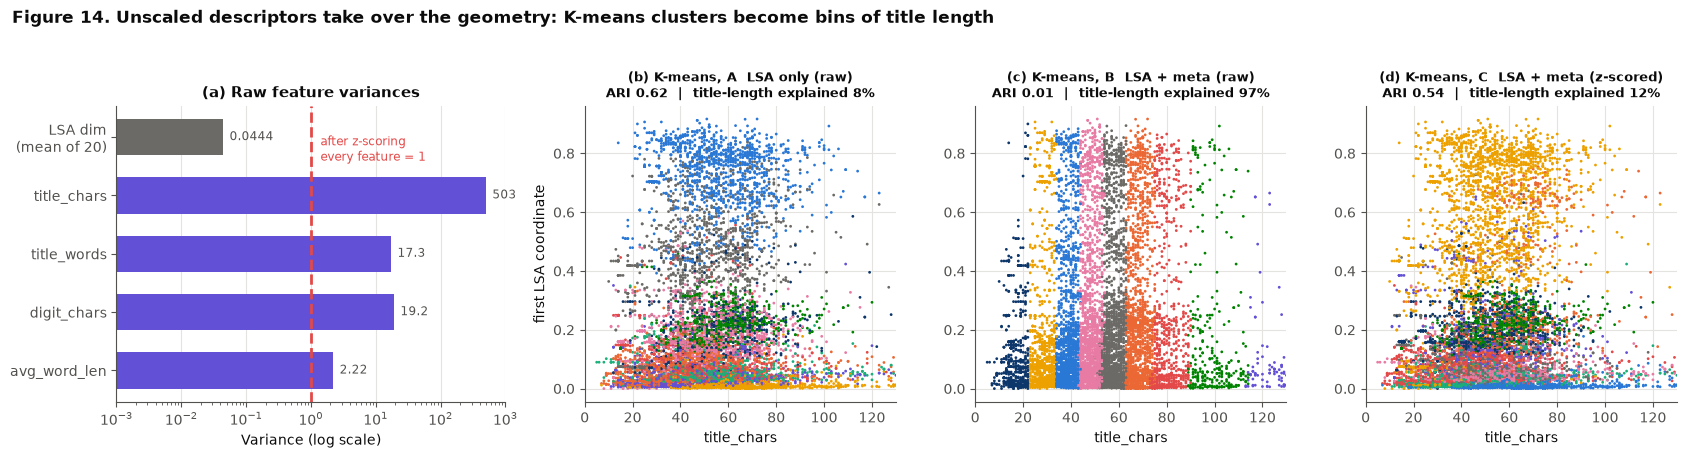

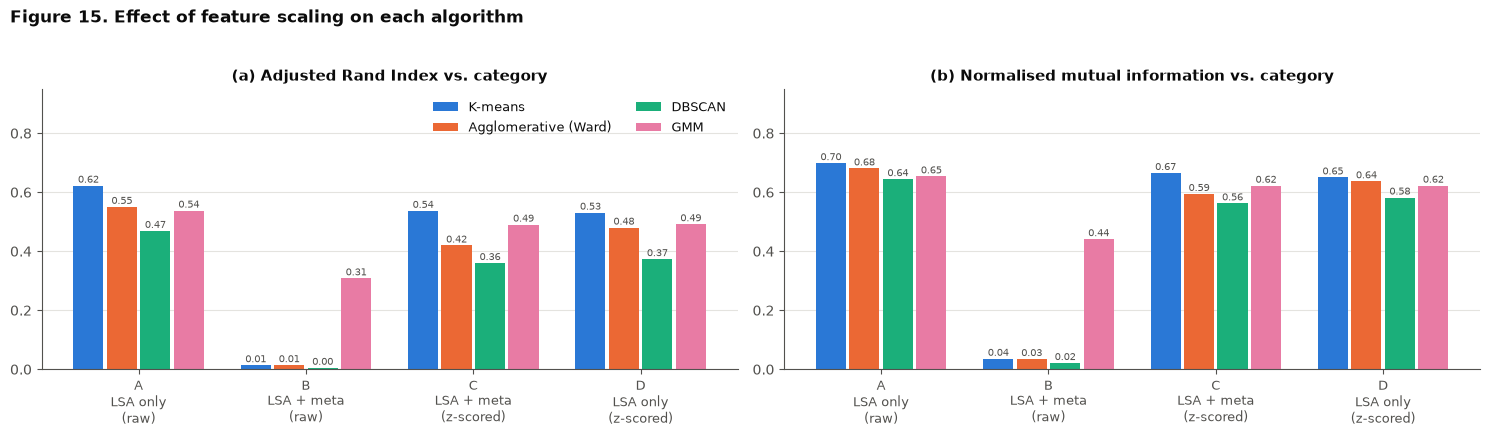

In [30]:
fig = plt.figure(figsize=(17, 4.4))
gs = fig.add_gridspec(1, 4, width_ratios=[1.25, 1, 1, 1])
ax = fig.add_subplot(gs[0])
names = ["LSA dim\n(mean of 20)", "title_chars", "title_words", "digit_chars", "avg_word_len"]
vals = [Z_dev.var(axis=0).mean()] + list(meta.var().values)
ax.barh(names[::-1], vals[::-1], color=[PAL["violet"]] * 4 + ["#6b6a66"], height=0.62); ax.set_xscale("log"); ax.axvline(1, color=PAL["red"], ls="--")
ax.text(1.4, 4.05, "after z-scoring\nevery feature = 1", color=PAL["red"], fontsize=8.5, va="top")
for i, v in enumerate(vals[::-1]): ax.text(v * 1.25, i, f"{v:.3g}", va="center", fontsize=8.5, color=INK2)
ax.set_xlim(1e-3, 1e3); ax.set_xlabel("Variance (log scale)"); ax.set_title("(a) Raw feature variances"); ax.grid(axis="y", visible=False)
for gi, key in zip(range(1, 4), ["A  LSA only\n(raw)", "B  LSA + meta\n(raw)", "C  LSA + meta\n(z-scored)"]):
    ax = fig.add_subplot(gs[gi]); lab = LAB[key]["K-means"]
    ax.scatter(meta.title_chars, Z_dev[:, 0], c=[CAT10[c] for c in lab], s=4, lw=0)
    ax.set_xlabel("title_chars"); ax.set_ylabel("first LSA coordinate" if gi == 1 else ""); ax.set_xlim(0, 130)
    r = std_res[(std_res.cond_short == key.split()[0]) & (std_res.model == "K-means")].iloc[0]
    ax.set_title(f"({'bcd'[gi - 1]}) K-means, {key.replace(chr(10), ' ')}\nARI {r.ARI:.2f}  |  title-length explained {r.length_eta2:.0%}", fontsize=9.5)
plt.suptitle("Figure 14. Unscaled descriptors take over the geometry: K-means clusters become bins of title length", x=0.01, ha="left", fontweight="bold", y=1.03)
plt.tight_layout(); savefig("fig14_standardisation_geometry")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), sharey=False)
cond_order = [c.replace("\n", " ") for c in CONDS]
for ax, metric, ttl in zip(axes, ["ARI", "NMI"], ["(a) Adjusted Rand Index vs. category", "(b) Normalised mutual information vs. category"]):
    w = 0.2
    for i, name in enumerate(ALGO):
        v = [std_res[(std_res.condition == c) & (std_res.model == name)][metric].iloc[0] for c in cond_order]
        xs_ = np.arange(len(cond_order)) + (i - 1.5) * w
        ax.bar(xs_, v, width=w - 0.02, color=ALGO_COL[name], label=name)
        for x_, v_ in zip(xs_, v): ax.text(x_, v_ + 0.01, f"{v_:.2f}", ha="center", fontsize=7.5, color=INK2)
    ax.set_xticks(range(len(cond_order))); ax.set_xticklabels([c.replace("  ", "\n", 1).replace(" (", "\n(") for c in cond_order], fontsize=9)
    ax.set_title(ttl); ax.set_ylim(0, 0.95); ax.grid(axis="x", visible=False)
axes[0].legend(ncol=2, fontsize=9, loc="upper right")
plt.suptitle("Figure 15. Effect of feature scaling on each algorithm", x=0.01, ha="left", fontweight="bold", y=1.03)
plt.tight_layout(); savefig("fig15_standardisation_scores")

In [31]:
# How much of the K-means difference is just random initialisation?  10 seeds x 20 restarts per condition.
seed_rows = []
for cname, Xc in CONDS.items():
    aris = [adjusted_rand_score(y_dev, KMeans(K, init="k-means++", n_init=20, random_state=s).fit_predict(Xc)) for s in range(10)]
    seed_rows.append(dict(condition=cname.replace("\n", " "), ARI_mean=np.mean(aris), ARI_sd=np.std(aris, ddof=1), ARI_min=np.min(aris), ARI_max=np.max(aris)))
km_seeds = pd.DataFrame(seed_rows).set_index("condition")
display(km_seeds.round(3))

,ARI_mean,ARI_sd,ARI_min,ARI_max
condition,,,,
A LSA only (raw),0.602,0.035,0.537,0.628
B LSA + meta (raw),0.014,0.000,0.014,0.014
C LSA + meta (z-scored),0.542,0.040,0.456,0.602
D LSA only (z-scored),0.554,0.058,0.484,0.649


**Results (Figures 14-15; ARI against category).**

| Condition | K-means (mean $\pm$ sd, 10 seeds) | Ward | DBSCAN | GMM |
|---|---|---|---|---|
| A: LSA only | 0.60 $\pm$ 0.04 | 0.55 | 0.47 | 0.54 |
| **B: + descriptors, raw** | **0.01** | **0.01** | **0.005** | 0.31 |
| C: + descriptors, z-scored | 0.54 $\pm$ 0.04 | 0.42 | 0.36 | 0.49 |
| D: LSA only, z-scored | 0.55 $\pm$ 0.06 | 0.48 | 0.37 | 0.49 |

1. **Without scaling the geometry is hijacked.** `title_chars` alone carries 92.7 % of the total variance in B (the 20 LSA coordinates together carry 0.16 %, the four descriptors 99.8 %). K-means and Ward clusters become **bins of title length** (97.5 % and 96.5 % of the variance of `title_chars` is explained by cluster membership, against 8 % in A), and agreement with the categories vanishes (ARI 0.01).
2. **Standardisation repairs it (B $\to$ C):** ARI returns to 0.54 (K-means) and the length effect falls to 12 %. C is still a little below A: the four descriptors are mostly noise for category and now get 1/6 of the weight.
3. **It is not a free lunch (A $\to$ D).** The 20 LSA coordinates already share a scale (std 0.16-0.27); z-scoring them changes K-means by less than its seed-to-seed spread (0.60 $\pm$ 0.04 vs 0.55 $\pm$ 0.06) but lowers Ward (0.55 $\to$ 0.48) and DBSCAN (0.47 $\to$ 0.37), because it inflates weak components. When features share a unit and variance carries information (TF-IDF/LSA, spectral bands), scaling can *remove* signal.
4. **Algorithms differ in scale sensitivity.** K-means, Ward and DBSCAN use raw Euclidean distance, so they are fully exposed. GMM with full covariance models each feature's scale itself (its Mahalanobis distance is affine-invariant), so it degrades less (0.54 $\to$ 0.31), but not to zero because EM starts from a K-means partition computed on the unscaled data.

**Rules of thumb.** Standardise (or robust-scale / log-transform skewed features) when features differ in units or range and each should matter comparably, e.g. *age (years) vs income (dollars)* in customer segmentation, or *NDVI in [-1, 1] vs a 16-bit digital number* in remote sensing. Do not blindly standardise features that already live on a common scale. Always re-derive scale-bound parameters (`eps`) after scaling.

<a id="q3"></a>
---
## **B11. Question 3: how should DBSCAN's `eps` and `min_samples` be selected without arbitrary choices?**

> **Short answer.** Treat the pair as **one density threshold plus one resolution**, constrain `min_samples` with the dimension rule, bound `eps` with the k-distance knee, and let a **label-free validity score** pick the cell on a grid, with a guard against chaining.

**Mathematics.** In a region of local density $\lambda$ (points per unit volume in $D$ dimensions) the expected neighbour count inside radius $\varepsilon$ is $\lambda\,V_D\,\varepsilon^{D}$, with $V_D=\pi^{D/2}/\Gamma(D/2+1)$. A point is core when this reaches $m$, so DBSCAN returns the **level set of a density estimate at**
$$\lambda^{*}=\frac{m}{V_D\,\varepsilon^{D}} .$$
The two parameters are not independent: they define one density level $\lambda^*$, and $m$ sets the smallest cluster size that counts as a cluster. Likewise the $m$-th neighbour distance of a point is $r_m(x)\approx\big(m/(\lambda(x)V_D)\big)^{1/D}$, so the sorted **k-distance curve is the distribution of local densities**; its knee is where "cluster-like" densities give way to "sparse" ones. As $\varepsilon$ grows, clusters first form, then **percolate**: bridges of points join them into one component.

**Procedure and result (Section B6, Figures 6-7).**

| Step | Rule | Outcome here |
|---|---|---|
| 1. `min_samples` range | $m\ge D+1=21$; default $2D=40$; larger for noisy / duplicated data | scan $m\in\{5,\dots,320\}$ |
| 2. `eps` upper bound | knee of the $m$-distance curve | knee `eps` percolates for $m\ge40$ (**$\ge$ 94 % of points in one cluster**) |
| 3. Choose the cell | maximise $(1-\text{noise})\times\text{silhouette}$, guard: $\ge 2$ clusters, largest $\le 50$ % | **`min_samples` = 160, `eps` = 0.475** (score 0.451) |
| 4. Robustness | plateau, interior optimum, resampling | scores 0.441 / 0.446 / 0.451 for $m$ = 80 / 120 / 160, then 0.348 at 240; mean bootstrap ARI 0.74 |
| 5. Only now, labels | validate | ARI 0.47, the same cell an oracle maximising ARI would have chosen |

**Real-world analogue.** With physical units, choose `eps` from the application: clustering GPS crash points, `eps` = 200 m (a street segment) and `min_samples` = 10 crashes (the smallest hotspot worth acting on). In an abstract embedding there is no such unit, hence the data-driven procedure above. Alternatives that avoid `eps`: HDBSCAN (tried: 92 micro-clusters here) or OPTICS.

**Cautions.** Standardise first (Q2) or `eps` is meaningless; re-derive `eps` after any rescaling; DBSCAN degrades when clusters have very different densities (a single $\lambda^*$ cannot fit all of them), which is exactly where HDBSCAN helps.

<a id="q4"></a>
---
## **B12. Question 4: which model for deployment, and what is the evidence?**

All numbers come from the cells below: generalisation to 25,311 unseen offers, stability under 80 % subsampling (10 refits), scalability up to all 35,311 offers, and the operational properties of each model.

In [32]:
# ==============================================================================
# QUESTION 4 - EVIDENCE FOR THE DEPLOYMENT DECISION
# ==============================================================================
# Generalisation: label 25,311 offers the models have never seen.  Only K-means and GMM have a native predict();
#      for Ward and DBSCAN the standard workaround is a nearest-neighbour rule (1-NN to dev points / to the nearest core point within eps).
core_idx = db.core_sample_indices_
core_nn = NearestNeighbors(n_neighbors=1).fit(Z_dev[core_idx])
core_lab = db.labels_[core_idx]
ward_nn = NearestNeighbors(n_neighbors=1).fit(Z_dev)

def predict_dbscan(Zn):
    d, i = core_nn.kneighbors(Zn)
    return np.where(d[:, 0] <= EPS_STAR, core_lab[i[:, 0]], -1)
def predict_ward(Zn): return ward.labels_[ward_nn.kneighbors(Zn)[1][:, 0]]
PREDICT = {"K-means": MODELS["K-means"]["est"].predict, "Agglomerative (Ward)": predict_ward, "DBSCAN": predict_dbscan, "GMM": MODELS["GMM"]["est"].predict}

rows, HOLD_LAB = [], {}
for name in ALGO:
    t0 = time.time(); lab = PREDICT[name](Z_hold); dt = time.time() - t0
    HOLD_LAB[name] = lab; sc = external_scores(y_hold, lab)
    rows.append({"Model": name, "Noise": (lab == -1).mean(), "Assign time (s)": dt, "ARI (holdout)": sc["ARI"], "NMI (holdout)": sc["NMI"],
                 "Homogeneity": sc["Homogeneity"], "Completeness": sc["Completeness"]})
holdout = pd.DataFrame(rows).set_index("Model")
holdout["ARI (dev)"] = comparison["ARI"]; holdout["NMI (dev)"] = comparison["NMI"]
holdout.to_csv(RES / "model_comparison_holdout.csv")
display(holdout[["ARI (dev)", "ARI (holdout)", "NMI (dev)", "NMI (holdout)", "Homogeneity", "Completeness", "Noise", "Assign time (s)"]].style.format("{:.3f}"))

,ARI (dev),ARI (holdout),NMI (dev),NMI (holdout),Homogeneity,Completeness,Noise,Assign time (s)
Model,,,,,,,,
K-means,0.622,0.618,0.699,0.696,0.698,0.695,0.000,0.002
Agglomerative (Ward),0.550,0.560,0.681,0.686,0.676,0.697,0.000,0.274
DBSCAN,0.469,0.476,0.644,0.647,0.682,0.616,0.193,0.147
GMM,0.538,0.533,0.654,0.650,0.650,0.651,0.000,0.066


In [33]:
# Stability: re-fit each algorithm on 10 random 80% subsamples and compare with the reference partition on the same points (ARI).
B, FRAC = 10, 0.8
def refit(name, Zb, seed):
    if name == "K-means": return KMeans(K, n_init=5, random_state=seed).fit_predict(Zb)
    if name == "Agglomerative (Ward)": return AgglomerativeClustering(K, linkage="ward").fit_predict(Zb)
    if name == "DBSCAN": return DBSCAN(eps=EPS_STAR, min_samples=MS_STAR).fit_predict(Zb)
    return GaussianMixture(K, covariance_type="full", n_init=2, random_state=seed, reg_covar=1e-4, max_iter=300).fit_predict(Zb)

rs = np.random.default_rng(SEED)
stab = {n: [] for n in ALGO}
t0 = time.time()
for b in range(B):
    idx = rs.choice(len(Z_dev), int(FRAC * len(Z_dev)), replace=False)
    for name in ALGO:
        stab[name].append(adjusted_rand_score(MODELS[name]["labels"][idx], refit(name, Z_dev[idx], b)))
print(f"{B * len(ALGO)} refits in {time.time() - t0:.0f}s")
stab_df = pd.DataFrame(stab); stab_df.to_csv(RES / "bootstrap_stability.csv", index=False)
display(stab_df.agg(["mean", "std", "min"]).T.round(3))

40 refits in 81s


,mean,std,min
K-means,0.817,0.088,0.705
Agglomerative (Ward),0.676,0.036,0.632
DBSCAN,0.736,0.027,0.695
GMM,0.692,0.038,0.643


In [34]:
# Scalability: wall-clock time as the number of offers grows (all 35,311 offers, embedded with the dev-fitted pipeline)
Z_all = np.vstack([Z_dev, Z_hold])
perm = np.random.default_rng(SEED).permutation(len(Z_all))
sizes = [2_500, 5_000, 10_000, 20_000, 35_311]
rows = []
for n in sizes:
    Zn = Z_all[perm[:n]]
    for name in ALGO:
        if name == "Agglomerative (Ward)" and n > 20_000:
            rows.append(dict(model=name, n=n, seconds=np.nan, note=f"needs {n * (n - 1) / 2 * 8 / 1e9:.1f} GB for the distance matrix - not run")); continue
        t0 = time.time()
        if name == "K-means": KMeans(K, n_init=10, random_state=SEED).fit(Zn)
        elif name == "GMM": GaussianMixture(K, covariance_type="full", n_init=1, random_state=SEED, reg_covar=1e-4, max_iter=300).fit(Zn)
        elif name == "DBSCAN": DBSCAN(eps=EPS_STAR, min_samples=MS_STAR).fit(Zn)
        else: AgglomerativeClustering(K, linkage="ward").fit(Zn)
        rows.append(dict(model=name, n=n, seconds=time.time() - t0, note=""))
scal = pd.DataFrame(rows); scal.to_csv(RES / "scalability.csv", index=False)
display(scal.pivot(index="n", columns="model", values="seconds")[ALGO].round(1))
slopes = {}
for name in ALGO:
    d = scal[(scal.model == name) & scal.seconds.notna()]
    slopes[name] = np.polyfit(np.log(d.n), np.log(d.seconds), 1)[0]
print("Empirical scaling exponent (time ~ n^p):", {k: round(float(v), 2) for k, v in slopes.items()})

model,K-means,Agglomerative (Ward),DBSCAN,GMM
n,,,,
2500,0.1,0.2,0.0,0.4
5000,0.1,1.1,0.1,1.0
10000,0.2,4.5,0.3,2.6
20000,0.3,23.3,0.6,4.1
35311,0.5,NaN,4.0,12.9


Empirical scaling exponent (time ~ n^p): {'K-means': 0.69, 'Agglomerative (Ward)': 2.19, 'DBSCAN': 1.79, 'GMM': 1.28}


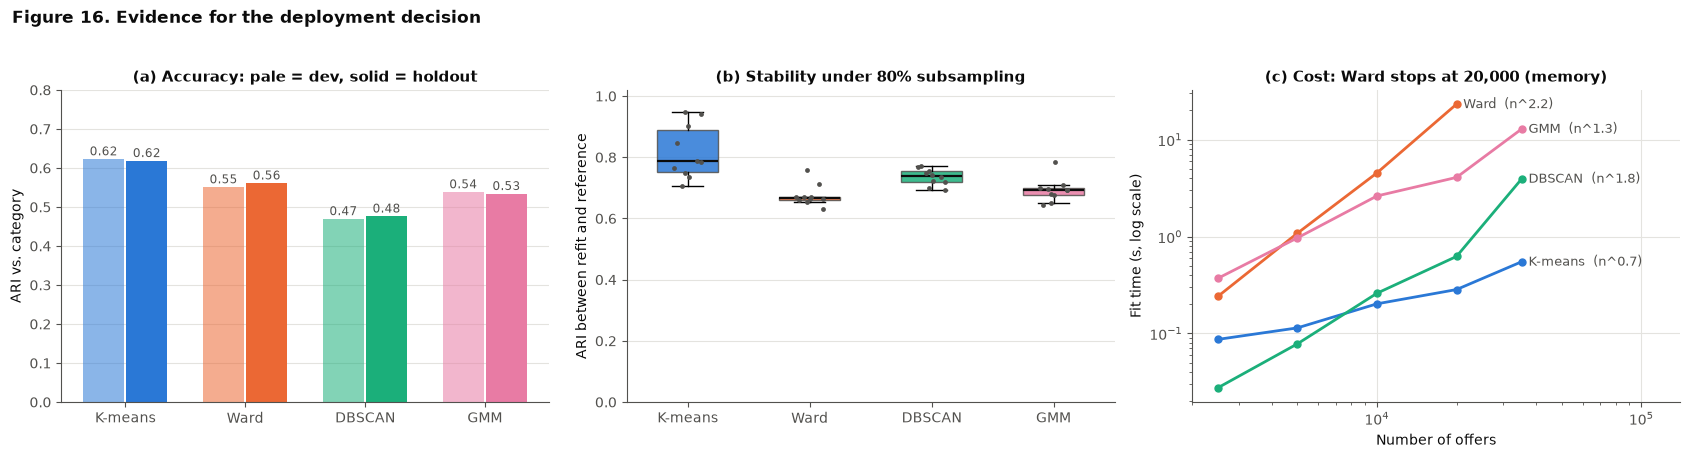

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
ax = axes[0]
w = 0.36; xs_ = np.arange(len(ALGO))
ax.bar(xs_ - w / 2, [holdout.loc[n, "ARI (dev)"] for n in ALGO], w - 0.02, color=[ALGO_COL[n] for n in ALGO], alpha=0.55, label="dev (10,000)")
ax.bar(xs_ + w / 2, [holdout.loc[n, "ARI (holdout)"] for n in ALGO], w - 0.02, color=[ALGO_COL[n] for n in ALGO], label="holdout (25,311, unseen)")
for x_, n in zip(xs_, ALGO):
    ax.text(x_ - w / 2, holdout.loc[n, "ARI (dev)"] + 0.01, f"{holdout.loc[n, 'ARI (dev)']:.2f}", ha="center", fontsize=8.5, color=INK2)
    ax.text(x_ + w / 2, holdout.loc[n, "ARI (holdout)"] + 0.01, f"{holdout.loc[n, 'ARI (holdout)']:.2f}", ha="center", fontsize=8.5, color=INK2)
ax.set_xticks(xs_); ax.set_xticklabels(["K-means", "Ward", "DBSCAN", "GMM"]); ax.set_ylabel("ARI vs. category"); ax.set_ylim(0, 0.8)
ax.set_title("(a) Accuracy: pale = dev, solid = holdout"); ax.grid(axis="x", visible=False)
ax = axes[1]
bp = ax.boxplot([stab_df[n] for n in ALGO], positions=xs_, widths=0.5, patch_artist=True, showfliers=False, medianprops=dict(color=INK, lw=1.6))
for patch, n in zip(bp["boxes"], ALGO): patch.set_facecolor(ALGO_COL[n]); patch.set_alpha(0.85); patch.set_edgecolor(INK2)
for x_, n in zip(xs_, ALGO): ax.scatter(np.full(B, x_) + np.random.default_rng(1).uniform(-0.12, 0.12, B), stab_df[n], s=12, color=INK2, zorder=5, lw=0)
ax.set_xticks(xs_); ax.set_xticklabels(["K-means", "Ward", "DBSCAN", "GMM"]); ax.set_ylabel("ARI between refit and reference"); ax.set_ylim(0, 1.02)
ax.set_title("(b) Stability under 80% subsampling"); ax.grid(axis="x", visible=False)
ax = axes[2]
for name in ALGO:
    d = scal[(scal.model == name) & scal.seconds.notna()]
    ax.plot(d.n, d.seconds, marker="o", ms=5, color=ALGO_COL[name])
    ax.text(d.n.iloc[-1] * 1.06, d.seconds.iloc[-1], f"{['K-means', 'Ward', 'DBSCAN', 'GMM'][ALGO.index(name)]}  (n^{slopes[name]:.1f})", va="center", fontsize=9, color=INK2)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(2000, 140000); ax.set_xlabel("Number of offers"); ax.set_ylabel("Fit time (s, log scale)")
ax.set_title("(c) Cost: Ward stops at 20,000 (memory)")
plt.suptitle("Figure 16. Evidence for the deployment decision", x=0.01, ha="left", fontweight="bold", y=1.03)
plt.tight_layout(); savefig("fig16_deployment_evidence")

In [36]:
# Decision table assembled from the measured numbers
tbl = pd.DataFrame({
    "ARI dev / holdout": [f"{holdout.loc[n, 'ARI (dev)']:.2f} / {holdout.loc[n, 'ARI (holdout)']:.2f}" for n in ALGO],
    "NMI dev / holdout": [f"{holdout.loc[n, 'NMI (dev)']:.2f} / {holdout.loc[n, 'NMI (holdout)']:.2f}" for n in ALGO],
    "Stability (mean ARI)": [f"{stab_df[n].mean():.2f}" for n in ALGO],
    "Fit time at 20,000 offers": [f"{scal[(scal.model == n) & (scal.n == 20000)].seconds.iloc[0]:.1f} s" for n in ALGO],
    "Assign 25,311 new offers": [f"{holdout.loc[n, 'Assign time (s)']:.2f} s" for n in ALGO],
    "Native predict()": ["yes", "no (1-NN proxy)", "no (core-point proxy)", "yes, with probabilities"],
    "Must choose": ["k", "k or cut height", "eps and min_samples", "k and covariance type"],
    "Outlier handling": ["none", "none", "built in (noise label)", "none (low posterior flags them)"],
}, index=ALGO)
tbl.to_csv(RES / "decision_table.csv")
display(tbl.T)

,K-means,Agglomerative (Ward),DBSCAN,GMM
ARI dev / holdout,0.62 / 0.62,0.55 / 0.56,0.47 / 0.48,0.54 / 0.53
NMI dev / holdout,0.70 / 0.70,0.68 / 0.69,0.64 / 0.65,0.65 / 0.65
Stability (mean ARI),0.82,0.68,0.74,0.69
"Fit time at 20,000 offers",0.3 s,23.3 s,0.6 s,4.1 s
"Assign 25,311 new offers",0.00 s,0.27 s,0.15 s,0.07 s
Native predict(),yes,no (1-NN proxy),no (core-point proxy),"yes, with probabilities"
Must choose,k,k or cut height,eps and min_samples,k and covariance type
Outlier handling,none,none,built in (noise label),none (low posterior flags them)


In [37]:
# Deployment prototype: the recommended model as a reusable scoring function (saved with joblib)
import joblib
km_final = MODELS["K-means"]["est"]
cluster_major = {c: CLASSES[np.bincount(y_dev[MODELS["K-means"]["labels"] == c], minlength=K).argmax()] for c in range(K)}
deploy = dict(tfidf=tfidf, svd=svd, n_components=N_COMP, kmeans=km_final, cluster_to_category=cluster_major)
Path("models").mkdir(exist_ok=True); joblib.dump(deploy, "models/kmeans_deployment.joblib")

def score_offers(titles, bundle=deploy):
    """New offer titles -> (cluster, suggested category, confidence).  Confidence = 1 - d1/d2 (distance to nearest vs second-nearest centroid)."""
    Zn = embed(bundle["svd"].transform(bundle["tfidf"].transform([t.lower() for t in titles])), bundle["n_components"])
    d = np.sort(bundle["kmeans"].transform(Zn), axis=1)
    cl = bundle["kmeans"].predict(Zn)
    return pd.DataFrame({"title": titles, "cluster": cl, "suggested_category": [bundle["cluster_to_category"][c] for c in cl], "confidence": 1 - d[:, 0] / d[:, 1]})

demo = ["Samsung Galaxy S9 64GB Midnight Black dual sim", "Bosch Serie 6 washing machine 8kg 1400 rpm WAW28560GB", "Intel Core i7 8700K 3.7GHz socket 1151 processor",
        "LG 55 inch 4K UHD smart LED TV 55UK6200", "Beko 70/30 frost free fridge freezer in white", "Canon EOS 800D DSLR camera body only"]
display(score_offers(demo).style.format({"confidence": "{:.2f}"}).hide(axis="index"))
size_kb = Path("models/kmeans_deployment.joblib").stat().st_size / 1024
print(f"Saved models/kmeans_deployment.joblib ({size_kb:.0f} KB): TF-IDF + SVD + K-means + cluster-to-category map")

title,cluster,suggested_category,confidence
Samsung Galaxy S9 64GB Midnight Black dual sim,1,Mobile Phones,0.53
Bosch Serie 6 washing machine 8kg 1400 rpm WAW28560GB,5,Washing Machines,0.51
Intel Core i7 8700K 3.7GHz socket 1151 processor,3,CPUs,0.68
LG 55 inch 4K UHD smart LED TV 55UK6200,2,TVs,0.89
Beko 70/30 frost free fridge freezer in white,0,Fridge Freezers,0.34
Canon EOS 800D DSLR camera body only,6,Digital Cameras,0.81


Saved models/kmeans_deployment.joblib (4934 KB): TF-IDF + SVD + K-means + cluster-to-category map


### **Recommendation: K-means (k = 10, k-means++ with 20 restarts) on the L2-normalised 20-d LSA embedding**

| Evidence | K-means | Ward | DBSCAN | GMM |
|---|---|---|---|---|
| **Accuracy on 25,311 unseen offers** (ARI / NMI) | **0.62 / 0.70** | 0.56 / 0.69 | 0.48 / 0.65 | 0.53 / 0.65 |
| **Generalisation** (dev $\to$ unseen ARI) | 0.62 $\to$ 0.62 | 0.55 $\to$ 0.56 | 0.47 $\to$ 0.48 | 0.54 $\to$ 0.53 |
| **Stability** (mean ARI under 80 % resampling) | **0.82** | 0.68 | 0.74 | 0.69 |
| **Cost** | sub-second, near-linear in $n$ | $\approx n^2$ time, 5 GB of RAM at 35k offers | near-linear to quadratic | seconds to tens of seconds |
| **Scoring new offers** | native, one distance computation per centroid | nearest-neighbour proxy | nearest-core-point proxy, 19 % noise | native with probabilities |
| **What must be chosen** | $k$ | $k$ and linkage | `eps`, `min_samples` (fragile, Q3) | $k$, covariance type, initialisation |

**Why K-means.** It has the best accuracy and stability in the table, it is the cheapest, and it is the only model that is both accurate *and* simple to serve: the whole model is ten centroids. Its weaknesses (Q1) are real but did not bite on this data once the offers were mapped to the unit sphere, where category groups are roughly spherical caps.

**Why not the others.** *Ward*: slightly lower accuracy and the lowest stability, with quadratic memory (35k offers already need 5 GB; a catalogue of millions is out of reach) and no `predict()`. *DBSCAN*: leaves about 19 % of offers unlabelled, depends on two fragile parameters and returns 15 groups that do not map to the 10 categories; keep it as an **outlier / near-duplicate detector**, not as the category assigner. *GMM*: the most flexible and the only soft model, but ARI is about 0.08 lower, it is far slower to fit (tens of seconds against under a second), EM depends on initialisation, and its extra flexibility did not pay on unit-sphere LSA features.

**How strong is the evidence?** K-means' own seed-to-seed spread is about 0.04 ARI (10 seeds: 0.54-0.63), so its lead over Ward (+0.06 to +0.07 ARI, +0.02 NMI) is modest and not decisive on accuracy alone; its leads over GMM (+0.08) and DBSCAN (+0.15) are clearer. K-means partitions vary the most across resamples (sd 0.09), yet even its worst refit (0.71) agrees more with the reference than the *average* Ward refit (0.68). The decision therefore rests on accuracy **plus** stability, cost and serving simplicity together.

**Operating it** (prototype in the last cells; the fitted pipeline is saved to `models/kmeans_deployment.joblib`):

1. **Score** a new title with the saved TF-IDF, SVD, normalisation and centroids; report the **confidence margin** $1-d_1/d_2$ (distance to the nearest vs second-nearest centroid). Route low-margin offers (for example $<0.2$) to human review.
2. **Pre-process language:** detect German titles and translate or route them separately (the largest observed error source, Section B4).
3. **Monitor drift** weekly: mean distance to centroid, cluster-share shift, and ARI against the previous model on a fixed audit set; **refit monthly** or when drift crosses a threshold.
4. **Revisit the choice if requirements change:** soft memberships needed $\to$ GMM (tied covariance); noise filtering needed $\to$ DBSCAN pre-filter; a small catalogue that needs a hierarchy $\to$ Ward.

**A caution on the evidence.** An ARI of 0.62 is good but not high. When labels exist, a *supervised* classifier is the right tool for assigning categories; clustering earns its place for unlabelled merchants, for discovering structure, and for bootstrapping labels.

In [38]:
# Key numbers for the written answers (kept in results/ so every figure quoted in the text can be traced)
key = dict(
    n_offers=len(df), n_categories=K, n_products=int(df["Cluster ID"].nunique()), n_dev=len(idx_dev), n_holdout=len(idx_hold),
    dev=comparison[["Clusters", "Noise", "Fit time (s)", "Silhouette", "Davies_Bouldin", "Calinski_Harabasz", "ARI", "NMI", "Homogeneity", "Completeness", "V_measure", "Purity"]].round(4).to_dict(orient="index"),
    holdout=holdout.round(4).to_dict(orient="index"),
    stability_mean={k: round(float(v), 4) for k, v in stab_df.mean().items()}, stability_std={k: round(float(v), 4) for k, v in stab_df.std().items()},
    dbscan=dict(min_samples=MS_STAR, eps=EPS_STAR), scaling_exponent={k: round(float(v), 3) for k, v in slopes.items()},
)
json.dump(key, open(RES / "key_numbers.json", "w"), indent=2)
print("Wrote results/key_numbers.json")

Wrote results/key_numbers.json


<a id="s15"></a>
---
## **B13. Limitations and next steps**

- **Text only.** Offers are described by short titles. Language mixing (German vs English) creates clusters unrelated to category; translation, language ID or multilingual embeddings are the first improvements, and images or attributes would help the fridge/freezer boundary.
- **One dataset, one split.** Results come from one stratified 10,000-offer dev sample and one 25,311-offer holdout; differences below about 0.04 ARI (the K-means seed spread) should not be over-read.
- **Label-informed choices.** $k = 10$ and the embedding size use external knowledge (disclosed); every other tuning step is label-free.
- **Fixed embedding.** TF-IDF + LSA is a simple baseline; sentence embeddings may separate categories better and change the ranking.
- **Timings** are from one laptop run and vary by machine; the *scaling exponents* and memory formulas carry the message.

<a id="s16"></a>
## **B14. Reproducibility**

| Item | Detail |
|---|---|
| Run | `jupyter nbconvert --to notebook --execute Clustering_Assignment.ipynb` from the assignment folder (about 10 minutes) |
| Input | `pricerunner_aggregate.csv` in the same folder |
| Packages | see `requirements.txt` (Python 3.14, scikit-learn 1.9, pandas 3.1, numpy 2.5, scipy 1.18, matplotlib 3.11, seaborn 0.13) |
| Seeds | every random step uses seed 42 (or an explicit seed list) |
| Colab | Open the notebook in Colab from GitHub; the first code cell downloads `pricerunner_aggregate.csv` from the repository (or asks for an upload); then Runtime > Run all (slower than a 12-thread laptop) |
| Outputs | `images/` (16 figures), `results/` (CSV/JSON tables quoted above), `models/kmeans_deployment.joblib` |